# Les Jeux de Paris 2024 ont-ils transformé le marché Airbnb parisien ?

À l'été 2024, Paris accueille les Jeux olympiques, puis les Jeux paralympiques. Les épreuves se déroulent dans plusieurs lieux de la capitale et attirent des visiteurs aux besoins d'hébergement variés. Dans les mois qui précèdent, des propriétaires peuvent être tentés de proposer leur logement à la location de courte durée ou d'en modifier le prix. Qu'observe-t-on dans les données d'Airbnb ?

Notre étude porte sur l'offre d'annonces et les prix affichés à Paris autour des sites de compétition. Nous cherchons à savoir comment ils évoluent au fil de l'année 2024 et si leur niveau varie avec la distance aux sites olympiques et paralympiques.

Pour cela, nous croisons des relevés d'annonces avec les coordonnées des sites et les contours des arrondissements. Les cartes et les statistiques descriptives permettent d'abord d'explorer les différences entre lieux et entre dates ; une analyse statistique complète ensuite cette exploration.

Les relevés décrivent des annonces à des dates de collecte données. Ils ne nous disent pas directement si un logement a été réservé ni à quel prix il l'a été. Les variations observées peuvent également être liées à la saison ou à d'autres évolutions du marché : elles ne suffisent donc pas à établir un effet causal des Jeux.

## 1. Sources et périmètre

Notre analyse repose sur trois sources :

- **Annonces Airbnb.** Les relevés parisiens proviennent d'Inside Airbnb et sont conservés sur SSP Cloud. Leurs fichiers et leurs dates de collecte sont présentés plus loin.
- **Sites olympiques et paralympiques.** Le ministère chargé des Sports met leurs coordonnées et leurs dates à disposition sur [data.gouv.fr](https://www.data.gouv.fr/api/1/datasets/r/5a0599d1-ad3f-42d1-b64c-204ee19cf520). Le script `sites_competition.py` prépare ces données et documente les corrections de dates ainsi que les sources utilisées pour les justifier.
- **Contours de Paris.** Les limites des 20 arrondissements proviennent de [Paris Data](https://opendata.paris.fr/explore/dataset/arrondissements/). Le fichier `contours_arrondissements.geojson` sert à sélectionner les annonces situées dans Paris et à tracer les cartes.

Nous retenons les annonces dont les coordonnées se trouvent dans Paris intra-muros. Leur position reste approximative : selon [Inside Airbnb](https://insideairbnb.com/data-assumptions/), elle peut être décalée jusqu'à environ 150 mètres par rapport à l'adresse réelle. Cette marge compte lorsque l'on étudie la proximité d'un site.

In [1]:
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt
from shapely.geometry import shape
from shapely.ops import unary_union
from IPython.display import display

from carte_sites_paris import FICHIERS, CONTOURS, SITES, charger_annonces, preparer_population

if not SITES.exists():
    raise FileNotFoundError("Données des sites absentes : exécutez python sites_competition.py puis relancez le notebook.")
from sites_competition import charger_tables_locales, garder_sites_paris

pd.set_option("display.max_columns", 30)
plt.style.use("seaborn-v0_8-whitegrid")

## 2. Sites des Jeux dans Paris

Nous distinguons les sites olympiques des sites paralympiques dans deux tables. Lorsqu'un lieu a servi aux deux événements, il apparaît dans chacune d'elles. Les tableaux indiquent aussi les dates et les coordonnées conservées après préparation des données.

In [2]:
sites_olympiques, sites_paralympiques = charger_tables_locales()
sites_olympiques_paris = garder_sites_paris(sites_olympiques)
sites_paralympiques_paris = garder_sites_paris(sites_paralympiques)
for nom, table in [("Olympiques", sites_olympiques_paris), ("Paralympiques", sites_paralympiques_paris)]:
    print(f"{nom} : {len(table)} lignes, {table['code_site'].nunique()} codes distincts")
    display(table[["code_site", "nom_site", "date_debut", "date_fin", "latitude", "longitude"]])

Olympiques : 19 lignes, 19 codes distincts


,code_site,nom_site,date_debut,date_fin,latitude,longitude
0,BCY,Arena Bercy,2024-07-27,2024-08-11,48.838630,2.378597
1,CDM,Arena Champ de Mars,2024-07-27,2024-08-11,48.853100,2.302520
2,SP1,Arena Paris Sud 1,2024-07-27,2024-08-11,48.832968,2.284007
3,SP4,Arena Paris Sud 4,2024-07-27,2024-08-10,48.830184,2.289033
4,SP6,Arena Paris Sud 6,2024-07-25,2024-08-11,48.829381,2.290865
5,CPL,Arena Porte de la Chapelle,2024-07-27,2024-08-10,48.899729,2.360514
6,GRP,Grand Palais,2024-07-27,2024-08-10,48.866164,2.312547
7,HDV,Hôtel de Ville,2024-08-10,2024-08-11,48.856388,2.352222
8,INV,Invalides,2024-07-25,2024-08-11,48.857048,2.312836
9,LCO,La Concorde,2024-07-27,2024-08-10,48.865704,2.321214


Paralympiques : 12 lignes, 12 codes distincts


,code_site,nom_site,date_debut,date_fin,latitude,longitude
0,BCY,Arena Bercy,2024-08-29,2024-09-08,48.838630,2.378597
1,CDM,Arena Champ de Mars,2024-08-29,2024-09-07,48.853100,2.302520
2,SP1,Arena Paris Sud 1,2024-08-29,2024-09-05,48.832968,2.284007
3,SP4,Arena Paris Sud 4,2024-08-29,2024-09-07,48.830184,2.289033
4,SP6,Arena Paris Sud 6,2024-08-29,2024-09-05,48.829381,2.290865
5,CPL,Arena Porte de la Chapelle,2024-08-29,2024-09-08,48.899729,2.360514
6,GRP,Grand Palais,2024-08-29,2024-09-07,48.866164,2.312547
7,INV,Invalides,2024-08-29,2024-09-08,48.857048,2.312836
8,LCO,La Concorde,2024-08-28,2024-08-28,48.865704,2.321214
9,ALX,Pont Alexandre III,2024-09-02,2024-09-02,48.863700,2.313400


## 3. Nettoyage et qualité des relevés Airbnb

Nous utilisons les relevés distincts disponibles de janvier à décembre 2024 afin de situer l'été des Jeux Olympiques et Paralympiques dans l'évolution de l'année. Les Jeux olympiques se déroulent du 26 juillet au 11 août et les Jeux paralympiques du 28 août au 8 septembre. Les dates de collecte, indiquées par `last_scraped`, couvrent parfois plusieurs jours : un fichier peut donc chevaucher une période de compétition et les jours qui la précèdent ou la suivent.

Le fichier nommé « mars » a été écarté après vérification : il est strictement identique à celui de juin, avec la même empreinte SHA-256. Nous n'avons donc pas de relevé distinct pour mars dans cette série.

Pour chaque fichier, nous gardons une ligne par identifiant, retirons les lignes sans coordonnées et sélectionnons les points situés dans Paris. Nous considérons comme exploitable un prix numérique strictement positif. Les montants sont exprimés en dollars, sans conversion.

In [3]:
mois_etudies = list(FICHIERS)  # Tous les relevés distincts disponibles en 2024.
contours = json.loads(CONTOURS.read_text(encoding="utf-8"))["features"]
if len(contours) != 20:
    raise ValueError("Le fichier doit contenir les 20 arrondissements de Paris.")
paris = unary_union([shape(feature["geometry"]) for feature in contours])

populations, lignes_qualite = {}, []
for mois in mois_etudies:
    print(f"Lecture de {FICHIERS[mois]}…")
    brut = charger_annonces(mois)
    population, controles = preparer_population(brut, paris)
    dates = pd.to_datetime(population["last_scraped"], errors="coerce").dropna()
    nombre = len(population)
    valides = int(population["prix_valide"].sum())
    populations[mois] = population
    lignes_qualite.append({
        "relevé": mois, "collecte_min": dates.min().date() if not dates.empty else None,
        "collecte_max": dates.max().date() if not dates.empty else None,
        "lignes_brutes": controles["lignes"], "sans_identifiant": controles["sans_id"],
        "doublons": controles["doublons"], "sans_coordonnées": controles["sans_coord"],
        "hors_Paris": controles["hors_paris"], "annonces_Paris": nombre,
        "prix_valides": valides, "prix_invalides_ou_manquants": nombre - valides,
        "part_prix_valides_%": round(100 * valides / nombre, 1) if nombre else float("nan"),
    })
qualite = pd.DataFrame(lignes_qualite).set_index("relevé")
display(qualite)

Lecture de etiennealpy/données paris/listing_13_janvier_2024…
Chargement des annonces : etiennealpy/données paris/listing_13_janvier_2024 ...


Lecture de etiennealpy/données paris/listing_14_fevrier_2024…
Chargement des annonces : etiennealpy/données paris/listing_14_fevrier_2024 ...


Lecture de etiennealpy/données paris/listing_17_avril_2024.csv…
Chargement des annonces : etiennealpy/données paris/listing_17_avril_2024.csv ...


Lecture de etiennealpy/données paris/listing_11_mai_2024.csv…
Chargement des annonces : etiennealpy/données paris/listing_11_mai_2024.csv ...


Lecture de etiennealpy/données paris/listing_10_juin_2024…
Chargement des annonces : etiennealpy/données paris/listing_10_juin_2024 ...


Lecture de etiennealpy/données paris/listing_14_juillet_2024.csv…
Chargement des annonces : etiennealpy/données paris/listing_14_juillet_2024.csv ...


... (2 outputs left out)

Lecture de etiennealpy/données paris/listing_07_octobre_2024.csv…
Chargement des annonces : etiennealpy/données paris/listing_07_octobre_2024.csv ...


Lecture de etiennealpy/données paris/listing_09_novembre_2024.csv…
Chargement des annonces : etiennealpy/données paris/listing_09_novembre_2024.csv ...


Lecture de etiennealpy/données paris/listing_16_decembre_2024…
Chargement des annonces : etiennealpy/données paris/listing_16_decembre_2024 ...


,collecte_min,collecte_max,lignes_brutes,sans_identifiant,doublons,sans_coordonnées,hors_Paris,annonces_Paris,prix_valides,prix_invalides_ou_manquants,part_prix_valides_%
relevé,,,,,,,,,,,
janvier,2024-01-14,2024-01-30,76938,0,0,0,0,76938,55672,21266,72.4
fevrier,2024-02-14,2024-02-22,80545,0,0,0,0,80545,56396,24149,70.0
avril,2024-04-17,2024-04-22,88548,0,0,0,0,88548,66388,22160,75.0
mai,2024-05-11,2024-05-14,92665,0,0,0,0,92665,70934,21731,76.5
juin,2024-06-11,2024-06-14,95885,0,0,0,0,95885,74579,21306,77.8
juillet,2024-07-14,2024-07-28,98810,0,0,0,0,98810,77010,21800,77.9
aout,2024-08-09,2024-08-15,98736,0,0,0,0,98736,74401,24335,75.4
septembre,2024-09-06,2024-09-13,95461,0,0,0,0,95461,64230,31231,67.3
octobre,2024-10-07,2024-10-11,93275,0,0,0,0,93275,61611,31664,66.1


### Effectifs et prix renseignés

Le nombre d'annonces localisées à Paris progresse au fil des relevés disponibles : il passe de **76 938 en janvier à 98 810 en juillet**, soit environ 28,4 % de plus. Il diminue ensuite pour atteindre **91 031 en décembre**, environ 7,9 % en dessous de juillet. La série ne comporte toutefois pas de relevé distinct pour mars. Ces chiffres décrivent les annonces présentes lors des collectes ; ils ne permettent pas de compter les logements loués.

Autour des Jeux, l'effectif passe de **95 885 en juin à 98 810 en juillet**. Il reste proche de ce niveau en août (98 736), puis recule en septembre (95 461). La hausse commence donc avant l'été. Elle peut refléter l'anticipation des Jeux, mais aussi des variations saisonnières ou des différences dans les collectes ; ces résultats seuls ne permettent pas de départager ces explications.

Les prix ne sont pas disponibles pour toutes les annonces. Leur part exploitable est de **77,8 % en juin, 77,9 % en juillet, 75,4 % en août et 67,3 % en septembre**. Pour ce dernier relevé, 31 231 annonces, soit 32,7 %, n'ont pas de prix exploitable. La proportion tombe ensuite autour des deux tiers en octobre, novembre et décembre. Si les annonces sans prix diffèrent des autres, les médianes calculées sur les seuls prix renseignés peuvent donner une image partielle du marché de la location de courte durée.


### Que nous apprend la disponibilité ?

La variable `availability_30` compte les nuits affichées comme disponibles pendant les **30 jours suivant la collecte**. Le tableau ci-dessous présente, pour chaque relevé, le nombre de valeurs utilisables, leur médiane et la part des annonces qui n'affichent aucune nuit disponible sur cette période.

Une nuit indisponible n'est pas forcément louée : l'hôte peut aussi la bloquer, et certaines règles du calendrier peuvent empêcher une réservation. Cette variable ne donne donc pas un taux de réservation réel. De plus, la période de 30 jours change avec la date de collecte ; elle ne correspond pas exactement aux dates des épreuves. Ces limites sont expliquées par [Inside Airbnb](https://insideairbnb.com/data-assumptions/) et par [Airbnb](https://www.airbnb.com/help/article/3612).

In [4]:
lignes_disponibilite = []
for mois, population in populations.items():
    valeurs = pd.to_numeric(population['availability_30'], errors='coerce')
    valides = valeurs.loc[valeurs.between(0, 30)]
    lignes_disponibilite.append({
        'relevé': mois, 'annonces à Paris': len(population),
        'disponibilités valides': len(valides),
        'disponibilités manquantes ou invalides': len(population) - len(valides),
        'nuits disponibles médianes': valides.median(),
        'part avec 0 nuit disponible (%)': 100 * valides.eq(0).mean() if len(valides) else float('nan'),
    })
disponibilites = pd.DataFrame(lignes_disponibilite).set_index('relevé')
display(disponibilites.round(1))

,annonces à Paris,disponibilités valides,disponibilités manquantes ou invalides,nuits disponibles médianes,part avec 0 nuit disponible (%)
relevé,,,,,
janvier,76938,76938,0,0.0,54.9
fevrier,80545,80545,0,0.0,53.9
avril,88548,88548,0,1.0,49.3
mai,92665,92665,0,0.0,50.6
juin,95885,95885,0,4.0,42.1
juillet,98810,98810,0,15.0,25.0
aout,98736,98736,0,11.0,29.9
septembre,95461,95461,0,1.0,47.7
octobre,93275,93275,0,2.0,47.7


Entre juin et juillet, la disponibilité affichée augmente dans nos relevés : la médiane passe de **4 à 15 nuits** sur les 30 jours suivants. Elle est ensuite de 11 nuits en août, puis de 1 en septembre. Sur les mêmes relevés, la part d'annonces sans aucune nuit disponible est respectivement de **42,1 %, 25,0 %, 29,9 % et 47,7 %**.

Ces résultats décrivent l'état des calendriers à quatre moments différents. Ils ne disent pas combien de nuits ont été réservées : une disponibilité faible peut aussi venir de nuits bloquées. Les fenêtres observées n'étant pas les mêmes d'un mois à l'autre, on ne peut pas non plus attribuer directement leurs écarts aux Jeux.

## 4. Prix affichés et types de logement

Pour décrire les prix renseignés, nous utilisons la médiane : la moitié des valeurs exploitables se situe en dessous et l'autre moitié au-dessus. Elle est moins sensible que la moyenne à quelques prix très élevés. Nous regardons aussi les effectifs par type de logement, car la proportion de logements entiers ou de chambres peut varier d'un relevé à l'autre. Les prix sont exprimés en dollars, sans conversion.

In [5]:
synthese, types = [], []
for mois, population in populations.items():
    valides = population.loc[population["prix_valide"]]
    synthese.append({"relevé": mois, "annonces": len(population), "prix exploitables": len(valides),
                     "prix médian ($)": valides["prix"].median()})
    groupes = population.assign(type_logement=population["room_type"].fillna("Non renseigné"))
    for categorie, groupe in groupes.groupby("type_logement"):
        prix = groupe.loc[groupe["prix_valide"], "prix"]
        types.append({"relevé": mois, "type de logement": categorie, "annonces": len(groupe),
                      "prix exploitables": len(prix), "prix manquants ou invalides": len(groupe)-len(prix),
                      "prix médian ($)": prix.median()})
synthese = pd.DataFrame(synthese).set_index("relevé")
par_type = pd.DataFrame(types)
display(synthese.round(2))
display(par_type.round(2))

,annonces,prix exploitables,prix médian ($)
relevé,,,
janvier,76938,55672,148.0
fevrier,80545,56396,150.0
avril,88548,66388,160.0
mai,92665,70934,163.5
juin,95885,74579,164.0
juillet,98810,77010,159.0
aout,98736,74401,170.0
septembre,95461,64230,155.0
octobre,93275,61611,160.0


,relevé,type de logement,annonces,prix exploitables,prix manquants ou invalides,prix médian ($)
0,janvier,Entire home/apt,67346,49166,18180,150.0
1,janvier,Hotel room,824,810,14,265.0
2,janvier,Private room,8302,5371,2931,100.0
3,janvier,Shared room,466,325,141,50.0
4,fevrier,Entire home/apt,70872,50610,20262,152.0
5,fevrier,Hotel room,808,548,260,189.0
6,fevrier,Private room,8386,4906,3480,96.0
7,fevrier,Shared room,479,332,147,54.0
8,avril,Entire home/apt,78711,60190,18521,166.0
9,avril,Hotel room,788,544,244,237.0


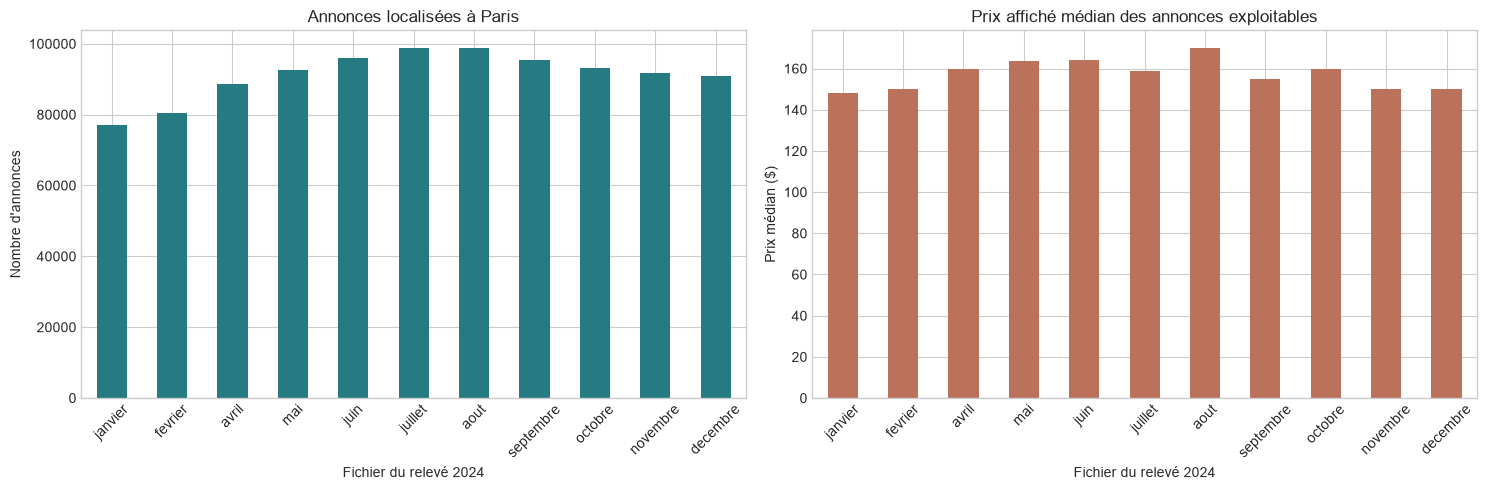

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
synthese["annonces"].plot.bar(ax=axes[0], color="#267b83", rot=45)
axes[0].set(title="Annonces localisées à Paris", xlabel="Fichier du relevé 2024", ylabel="Nombre d'annonces")
synthese["prix médian ($)"].plot.bar(ax=axes[1], color="#bc725a", rot=45)
axes[1].set(title="Prix affiché médian des annonces exploitables", xlabel="Fichier du relevé 2024", ylabel="Prix médian ($)")
fig.tight_layout()
plt.show()

Le premier graphique montre une augmentation du nombre d'annonces à Paris à l'approche des Jeux : de **76 938 en janvier à 98 810 en juillet**, soit **28,4 % de plus**. L'effectif reste presque identique en août (98 736), puis diminue dès septembre pour atteindre 91 031 en décembre. Le maximum se situe donc pendant l'été des Jeux, mais la progression commence plusieurs mois auparavant. Cette évolution est compatible avec une mobilisation de l'offre en anticipation de l'événement, sans permettre de distinguer cette hypothèse de la saisonnalité touristique.

Le second graphique ne montre cependant pas une hausse continue des prix à l'approche des compétitions. Le prix médian passe de **148 dollars en janvier à 164 dollars en juin**, puis **baisse à 159 dollars en juillet**, alors que le nombre d'annonces atteint son maximum. Il culmine à **170 dollars en août**, soit **6,9 % de plus qu'en juillet**, avant de retomber à **155 dollars en septembre**. Le sommet d'août coïncide avec un relevé effectué pendant les Jeux olympiques, mais il ne dépasse celui de juin que de **3,7 %**. À l'échelle de Paris, ces données montrent donc un pic estival ponctuel plutôt qu'une envolée générale et durable des prix pendant les Jeux.

Le tableau par type de logement précise cette évolution : entre juillet et août, la médiane augmente aussi bien pour les **logements entiers (164 dollars à 176 dollars)** que pour les **chambres privées (103 dollars à 120 dollars)**. La part des logements entiers reste proche de **89,5 % des annonces** sur ces deux relevés : le pic global d'août ne s'explique donc pas simplement par une plus forte proportion de cette catégorie. Cela ne signifie toutefois pas que les mêmes logements ont tous augmenté leur prix.

Pour notre projet, le résultat à approfondir est donc le décalage entre une offre déjà maximale en juillet et un prix médian maximal en août. Une offre plus abondante pourrait avoir limité la hausse des prix, mais ces graphiques ne permettent pas de tester ce mécanisme. Ils donnent surtout une référence pour l'analyse spatiale : **le pic d'août est-il plus marqué près des sites de compétition que dans le reste de Paris ?** Les comparaisons spatiales et les modèles présentés ci-dessous examinent si cette évolution dépasse les variations estivales habituelles.

## 5. Prix dans Paris : sites de compétition et parcours des cérémonies

### 5.1. Des quartiers qui restent chers avant, pendant et après les Jeux

Les trois cartes produites par `carte_sites_paris.py` utilisent une échelle commune, de 100 à 350 dollars, avec des couleurs extrêmes au-delà de ces bornes. Chaque maille d'environ 250 mètres représente le prix médian d'au moins cinq annonces exploitables. Les zones grises correspondent à un effectif insuffisant, et non à une absence de logements.

La collecte de juillet s'étend du 14 au 28, celle d'août du 9 au 15 et celle de septembre du 6 au 13. Elles ne représentent donc pas exactement les trois mois calendaires : juillet chevauche l'ouverture olympique, août la fin des Jeux olympiques et septembre la fin des Paralympiques.

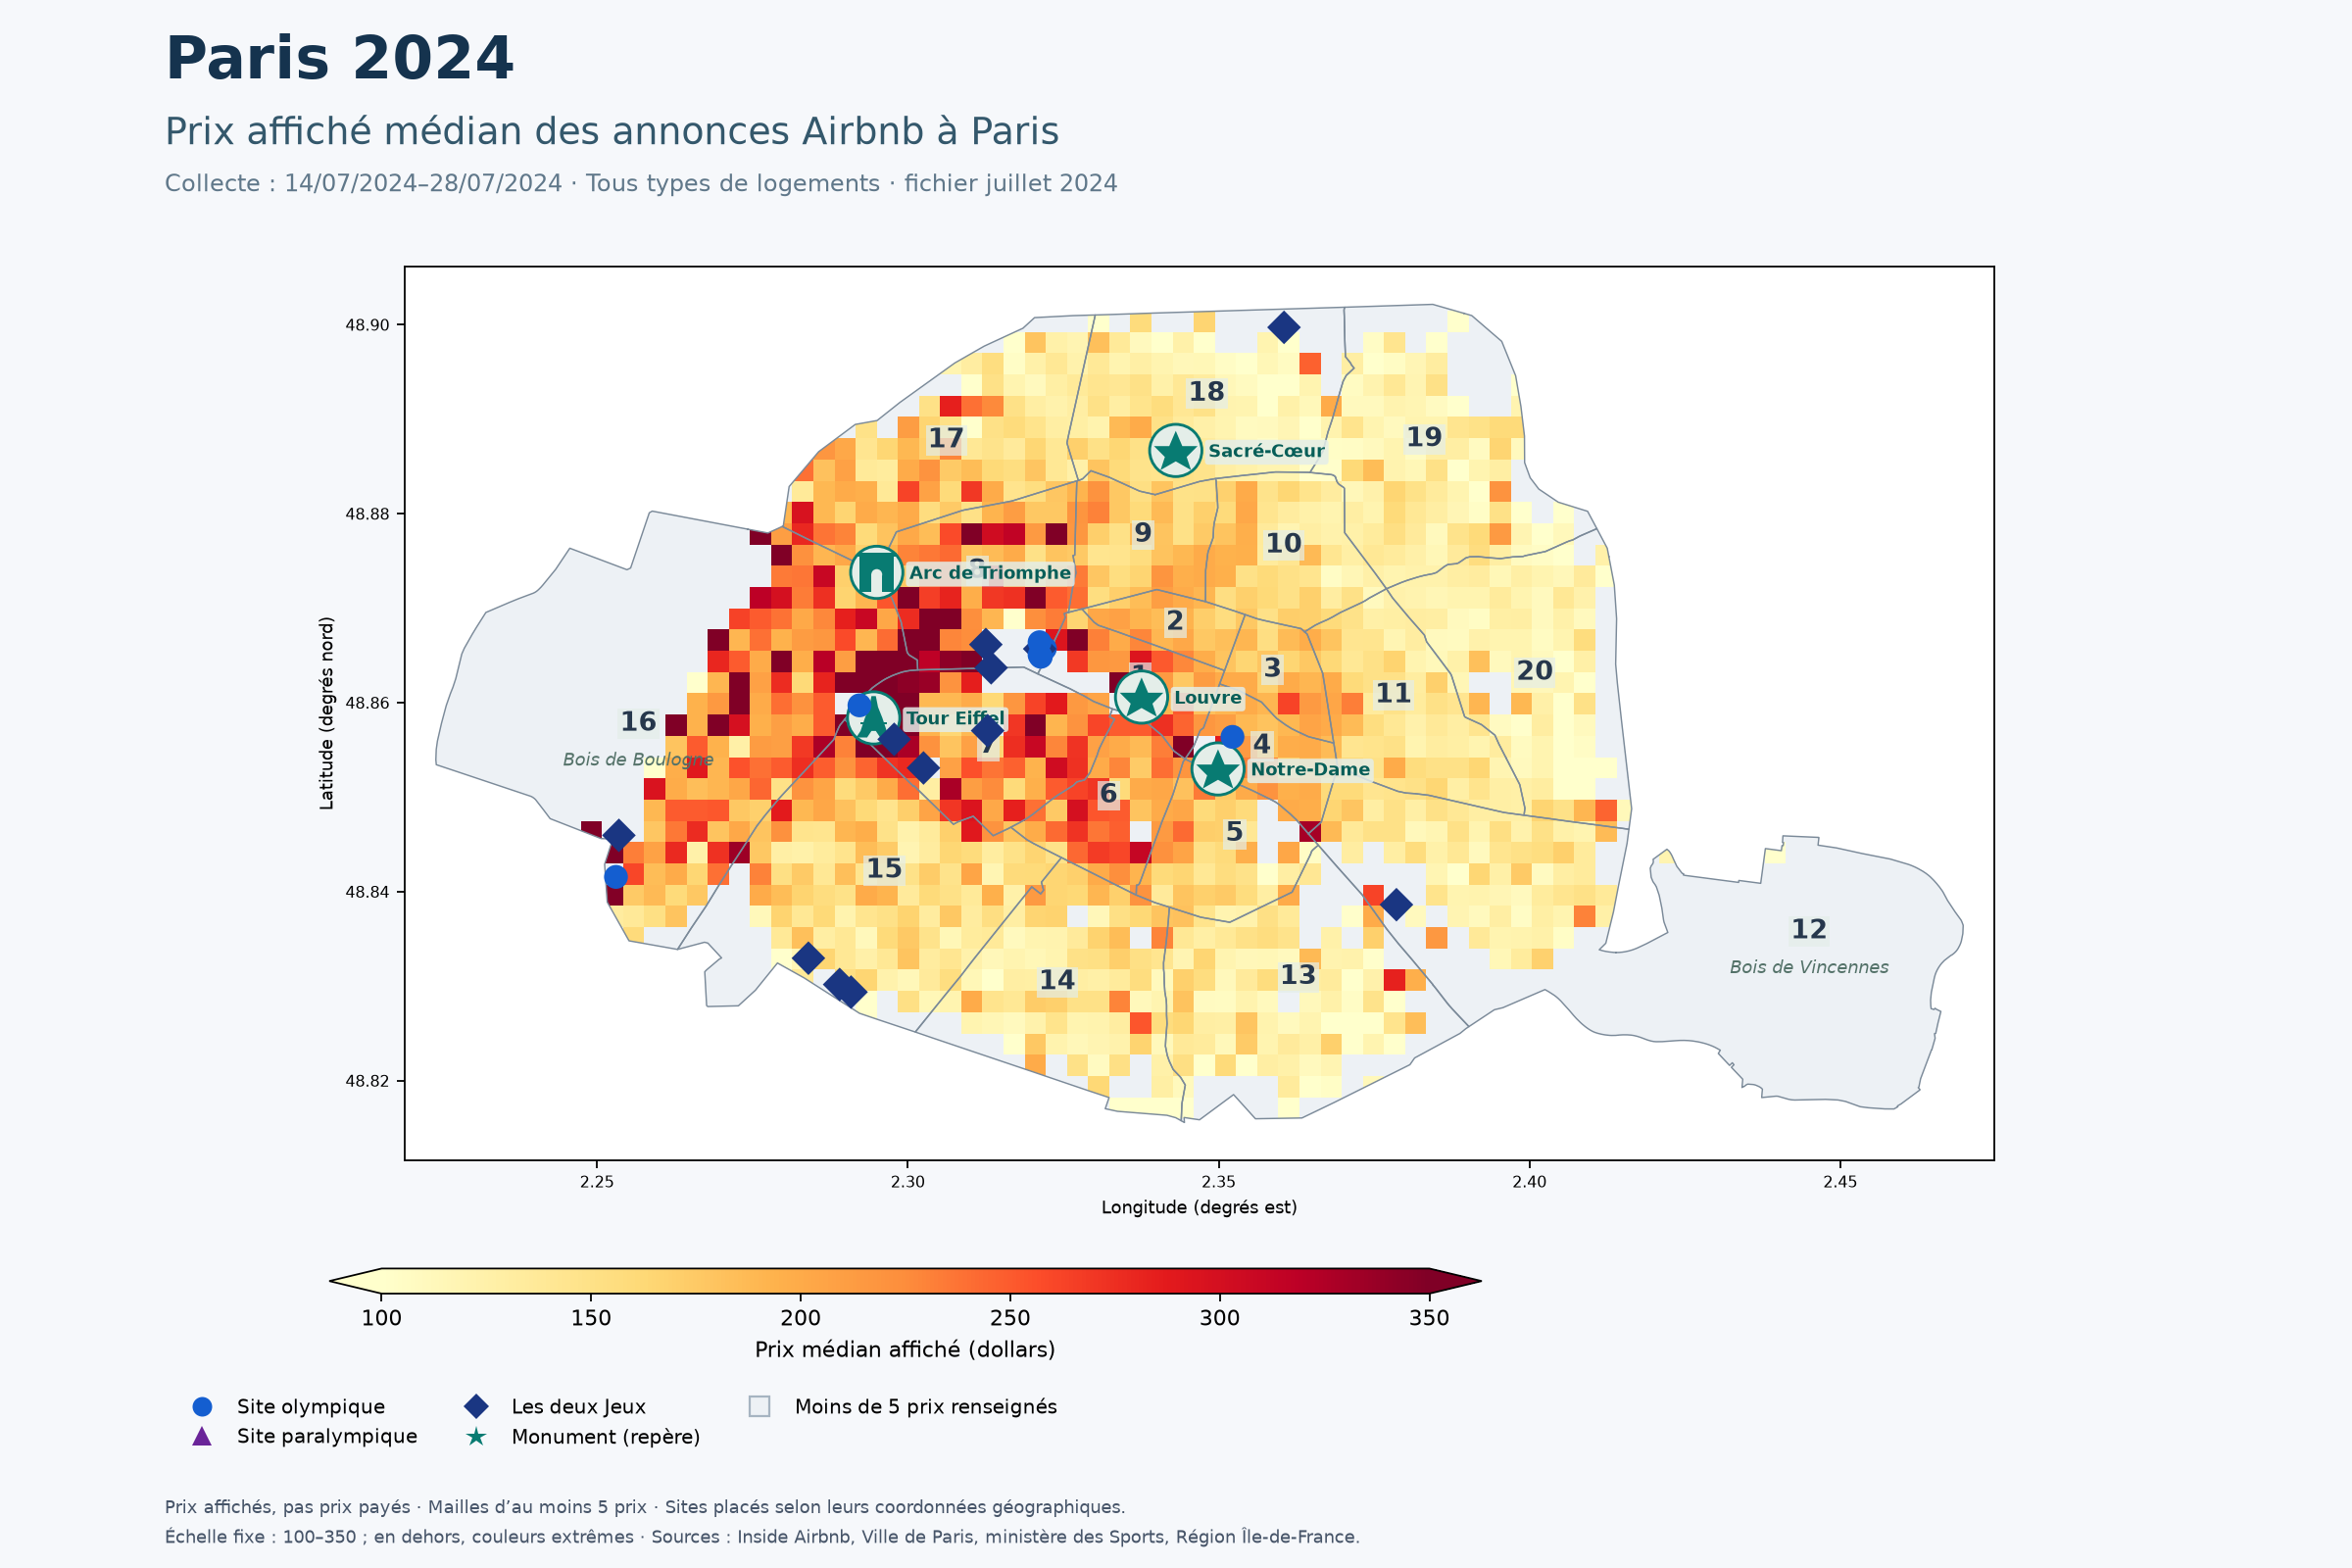

Juillet : les prix élevés se concentrent déjà dans le centre et l'ouest, près des monuments et de plusieurs sites de compétition.

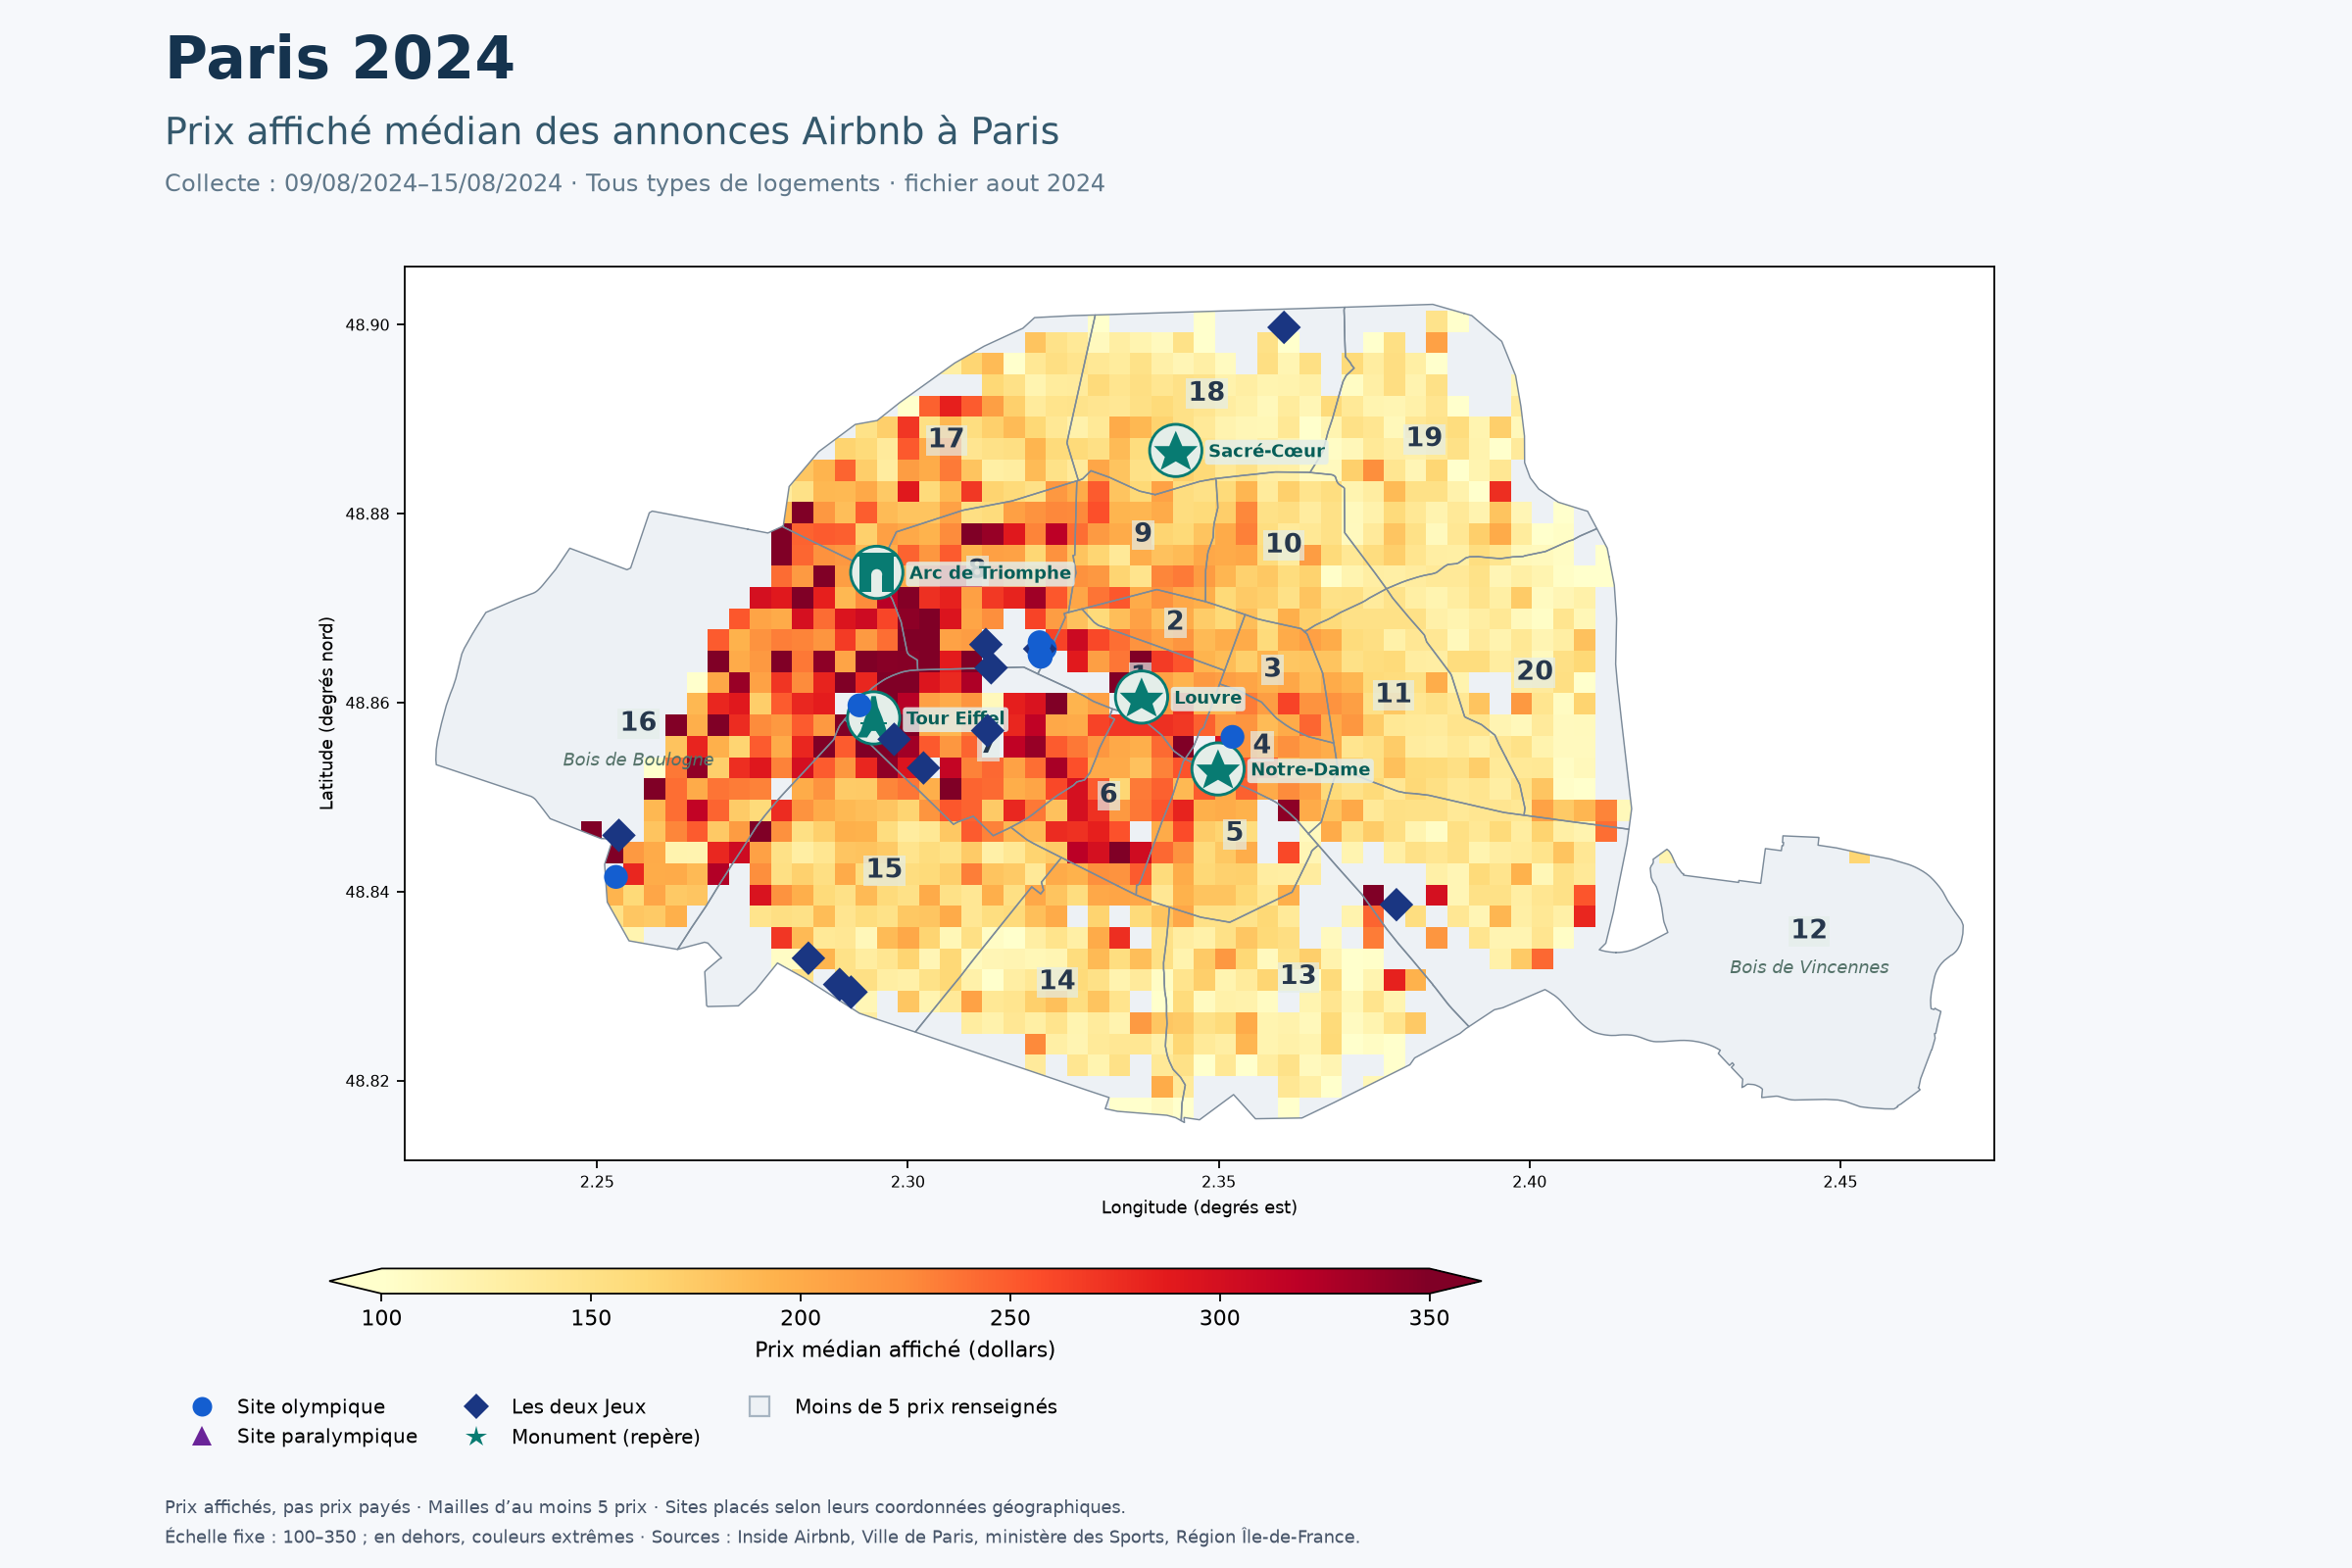

Août : davantage de mailles avec des prix élevés apparaissent, mais la structure centre-ouest / périphérie reste visible.

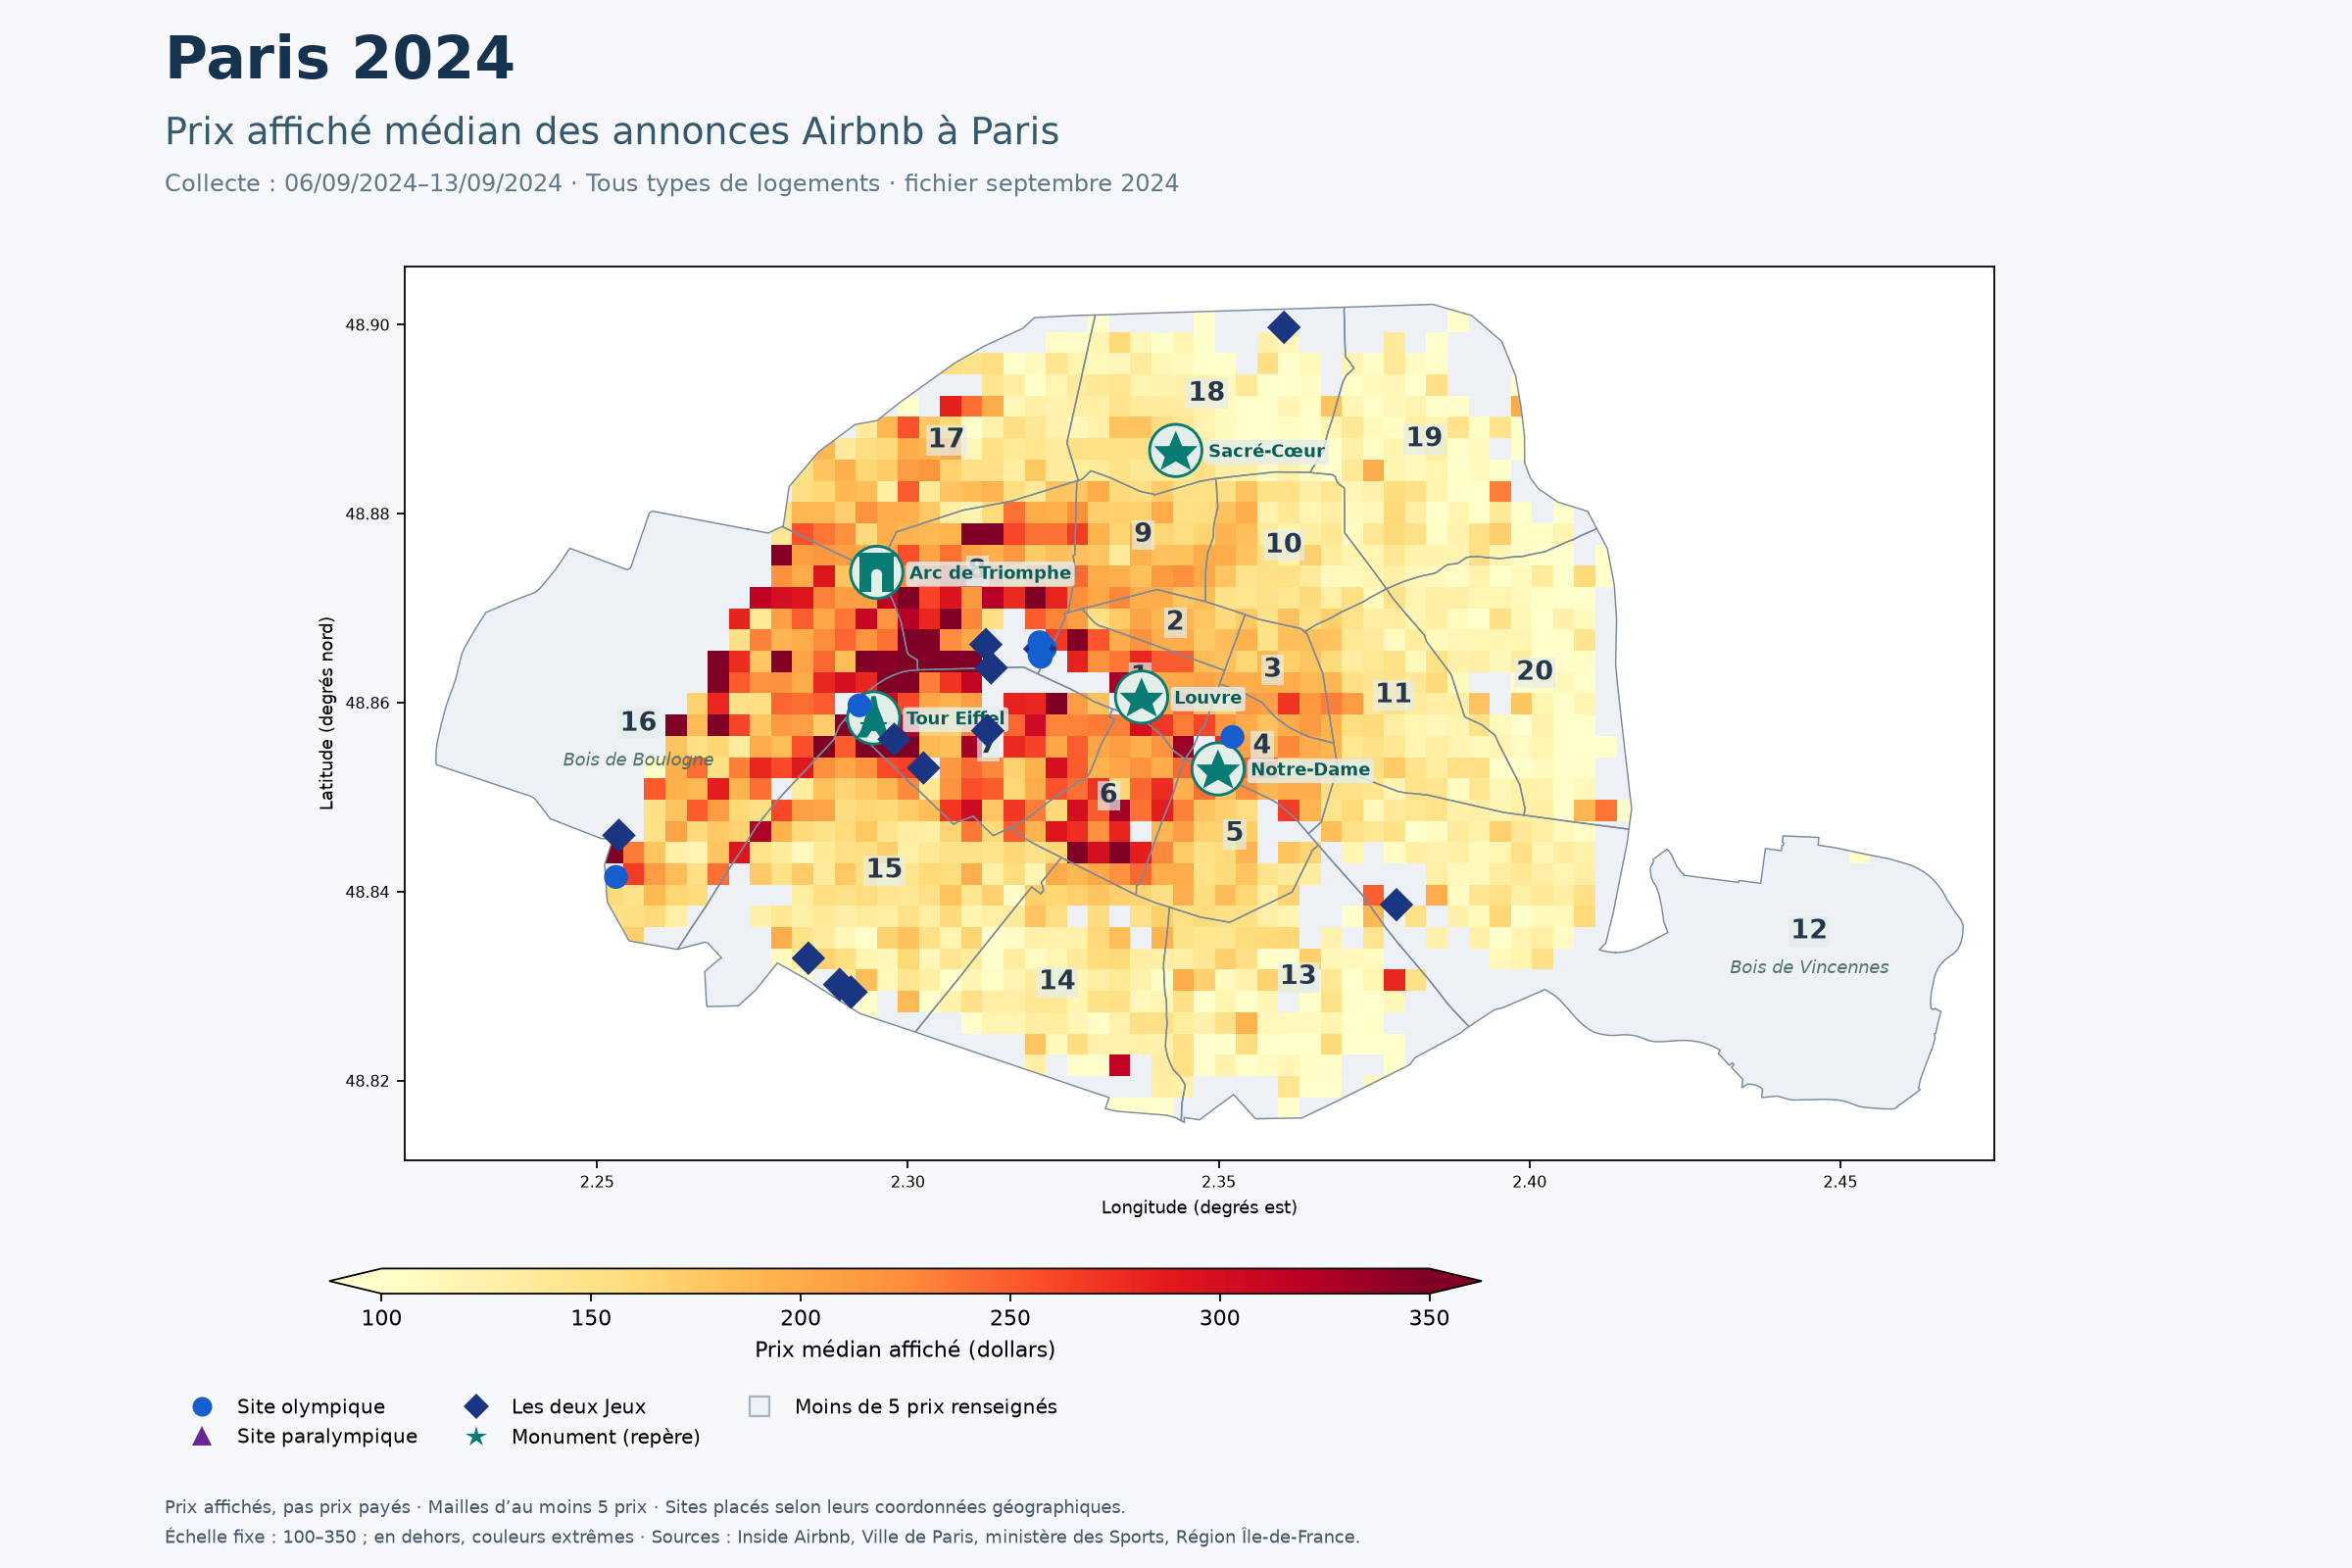

Septembre : les niveaux diminuent dans plusieurs secteurs ; les quartiers centraux et ceux d'ouest restent plus chers.

In [7]:
from IPython.display import Image, Markdown, display

cartes = [f"cartes prix/carte_prix_paris_{mois}.png" for mois in ["juillet", "aout", "septembre"]]
legendes_cartes = dict(zip(cartes, [
    "Juillet : les prix élevés se concentrent déjà dans le centre et l'ouest, près des monuments et de plusieurs sites de compétition.",
    "Août : davantage de mailles avec des prix élevés apparaissent, mais la structure centre-ouest / périphérie reste visible.",
    "Septembre : les niveaux diminuent dans plusieurs secteurs ; les quartiers centraux et ceux d'ouest restent plus chers."
]))
for fichier in cartes:
    display(Image(filename=fichier, width=1000))
    display(Markdown(legendes_cartes[fichier]))

Les cartes mettent d'abord en évidence une structure persistante : le secteur Tour Eiffel–Invalides–Champs-Élysées est cher dans les trois relevés. À l'inverse, la présence de sites à Bercy ou Porte de la Chapelle ne s'accompagne pas d'un ensemble de prix aussi élevés à leur voisinage immédiat. L'emplacement d'un site n'est donc pas, à lui seul, une explication suffisante des variations de prix.

En août, le renforcement de certaines couleurs rejoint le pic médian observé à l'échelle de Paris. Mais les secteurs chers de septembre ressemblent encore à ceux de juillet. Cette continuité nous fait plutôt penser que cela serait lié à l'attractivité habituelle des quartiers. Une carte ne permet pas de décider quelle part du niveau des prix revient aux Jeux.

### 5.2. Le type de logement change la lecture

Les cartes séparées des logements entiers et des chambres privées reprennent la même échelle. En août, le gradient centre-ouest demeure visible pour les logements entiers, qui représentent l'essentiel des annonces. Il ne résulte donc pas uniquement d'un mélange de catégories différentes.

La carte des chambres privées est beaucoup plus lacunaire : de nombreuses mailles n'atteignent pas cinq prix. Certaines concentrations chères apparaissent dans les quartiers centraux, mais il serait trompeur de comparer visuellement une maille colorée à une zone grise. Les six cartes ci-dessous permettent de comparer les prix des logements entiers et des chambres privées en juillet, août et septembre 2024. *(cliquez sur le triangle pour les afficher)*


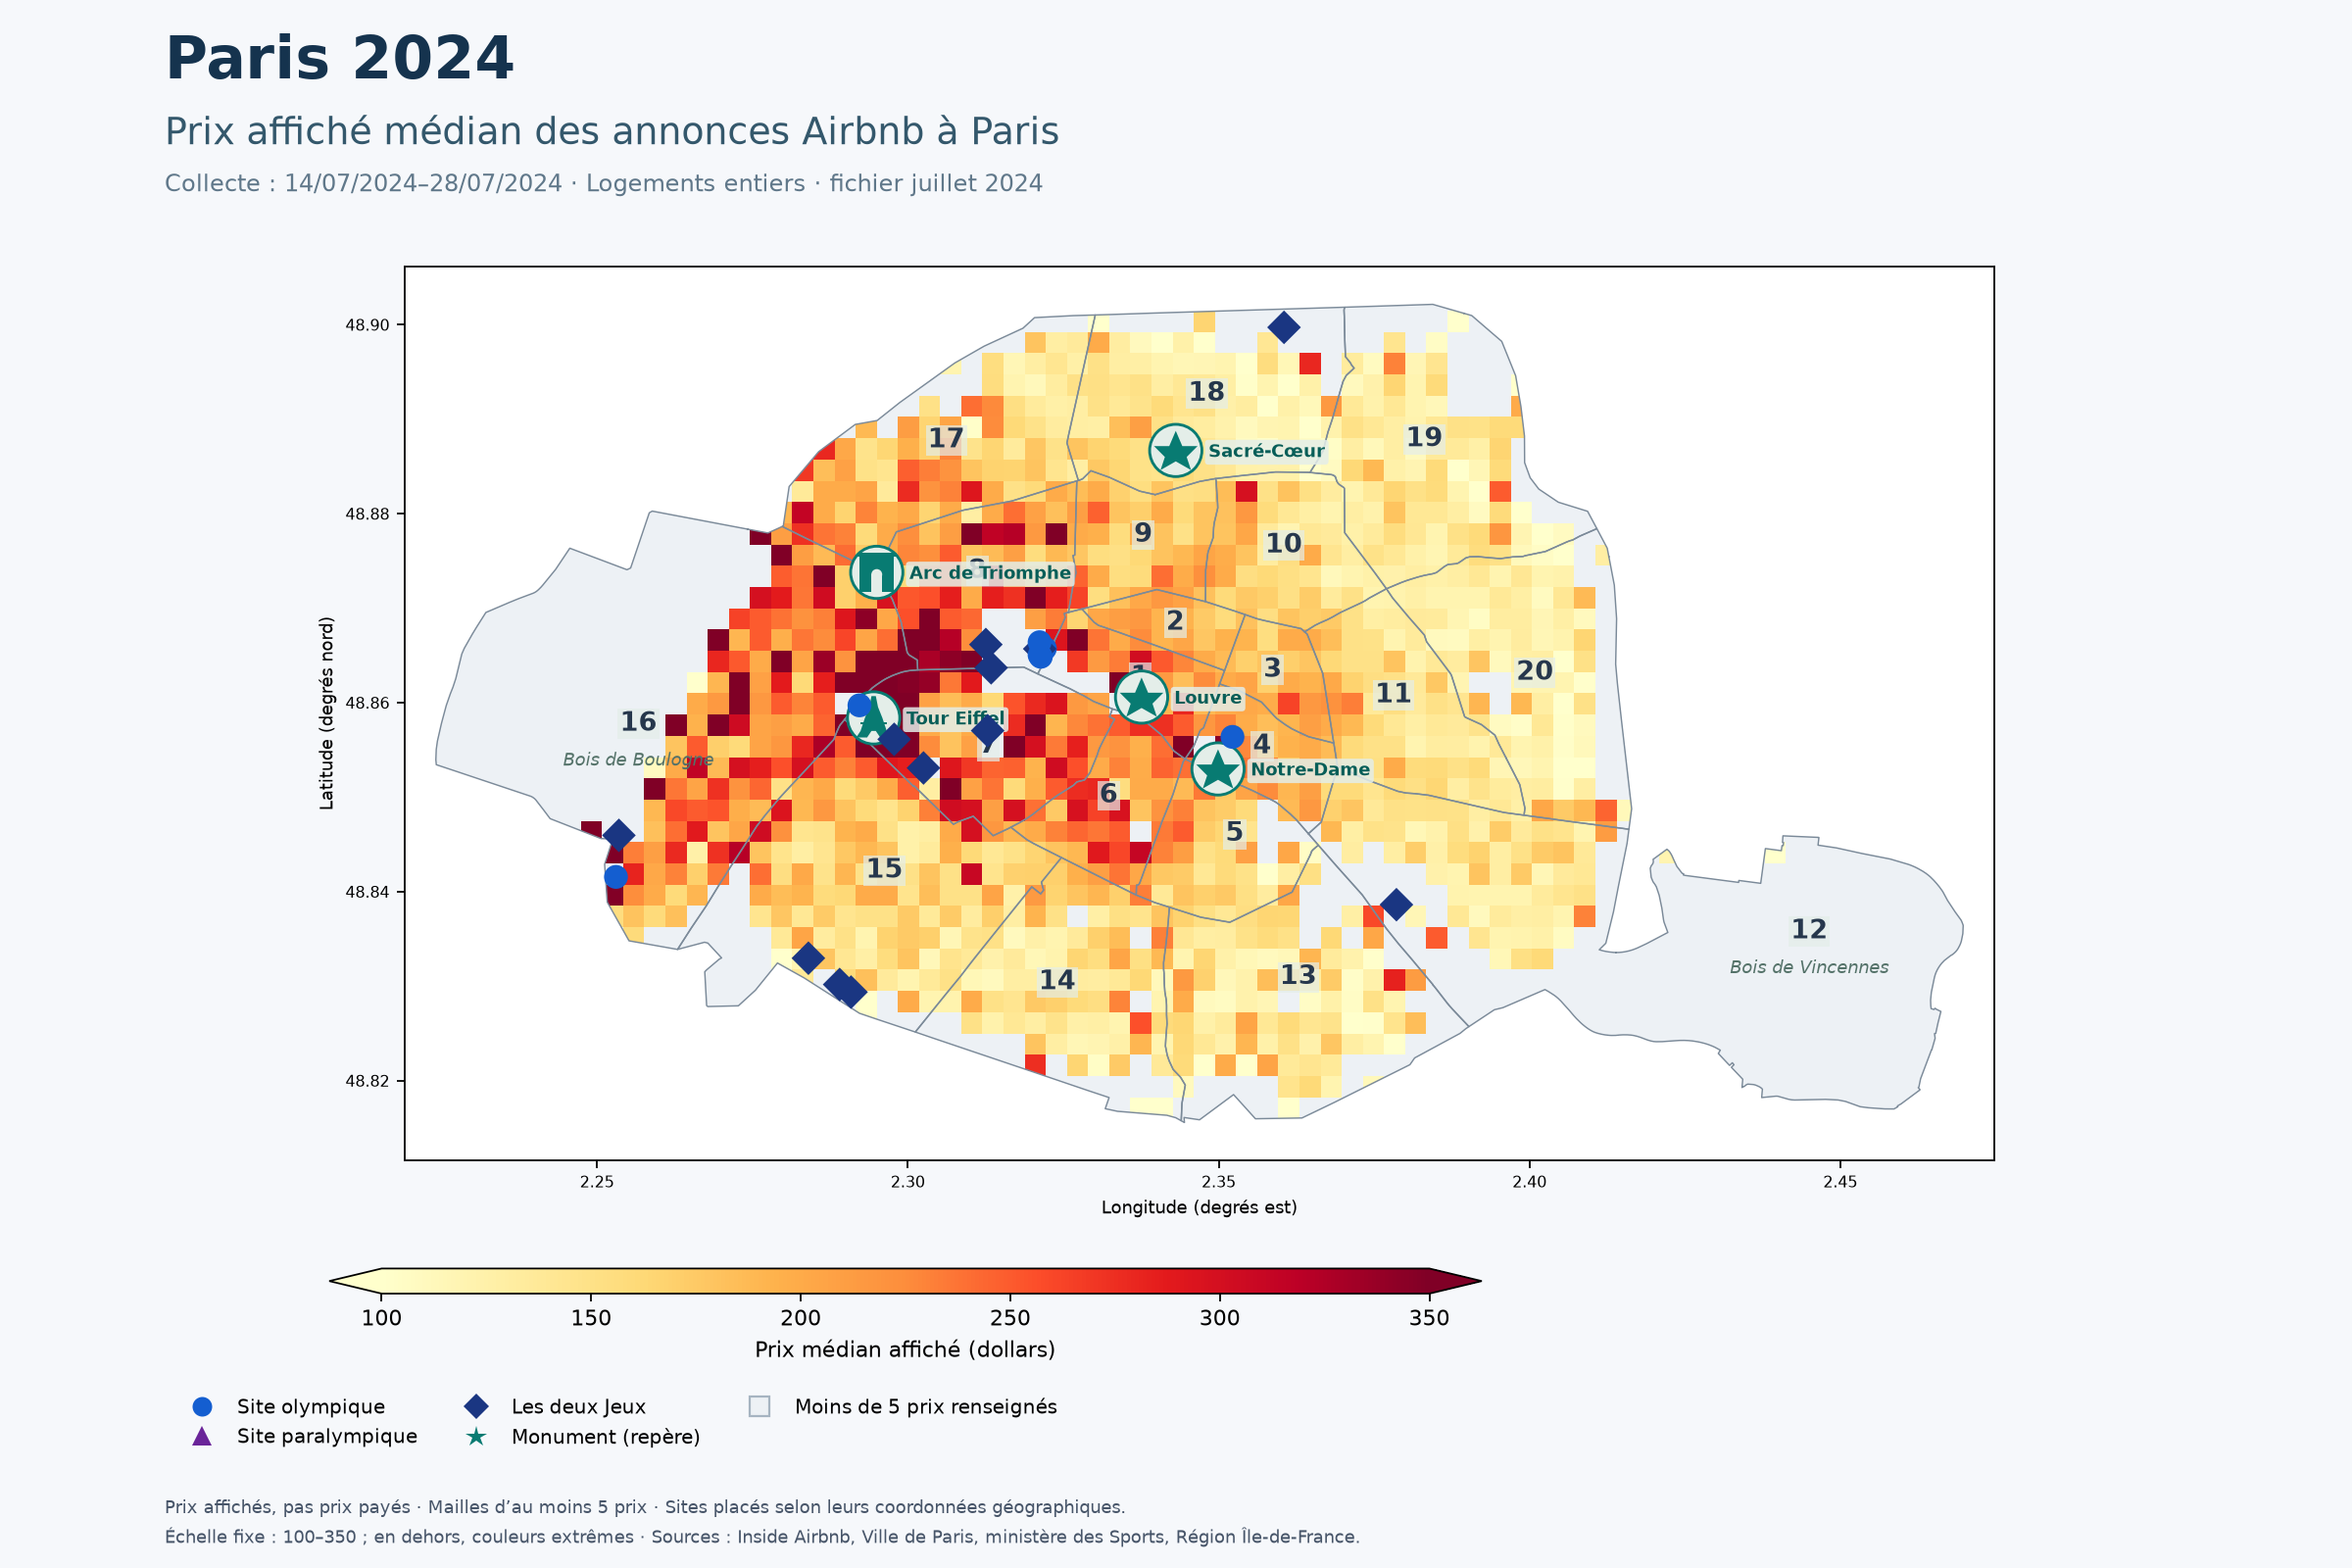
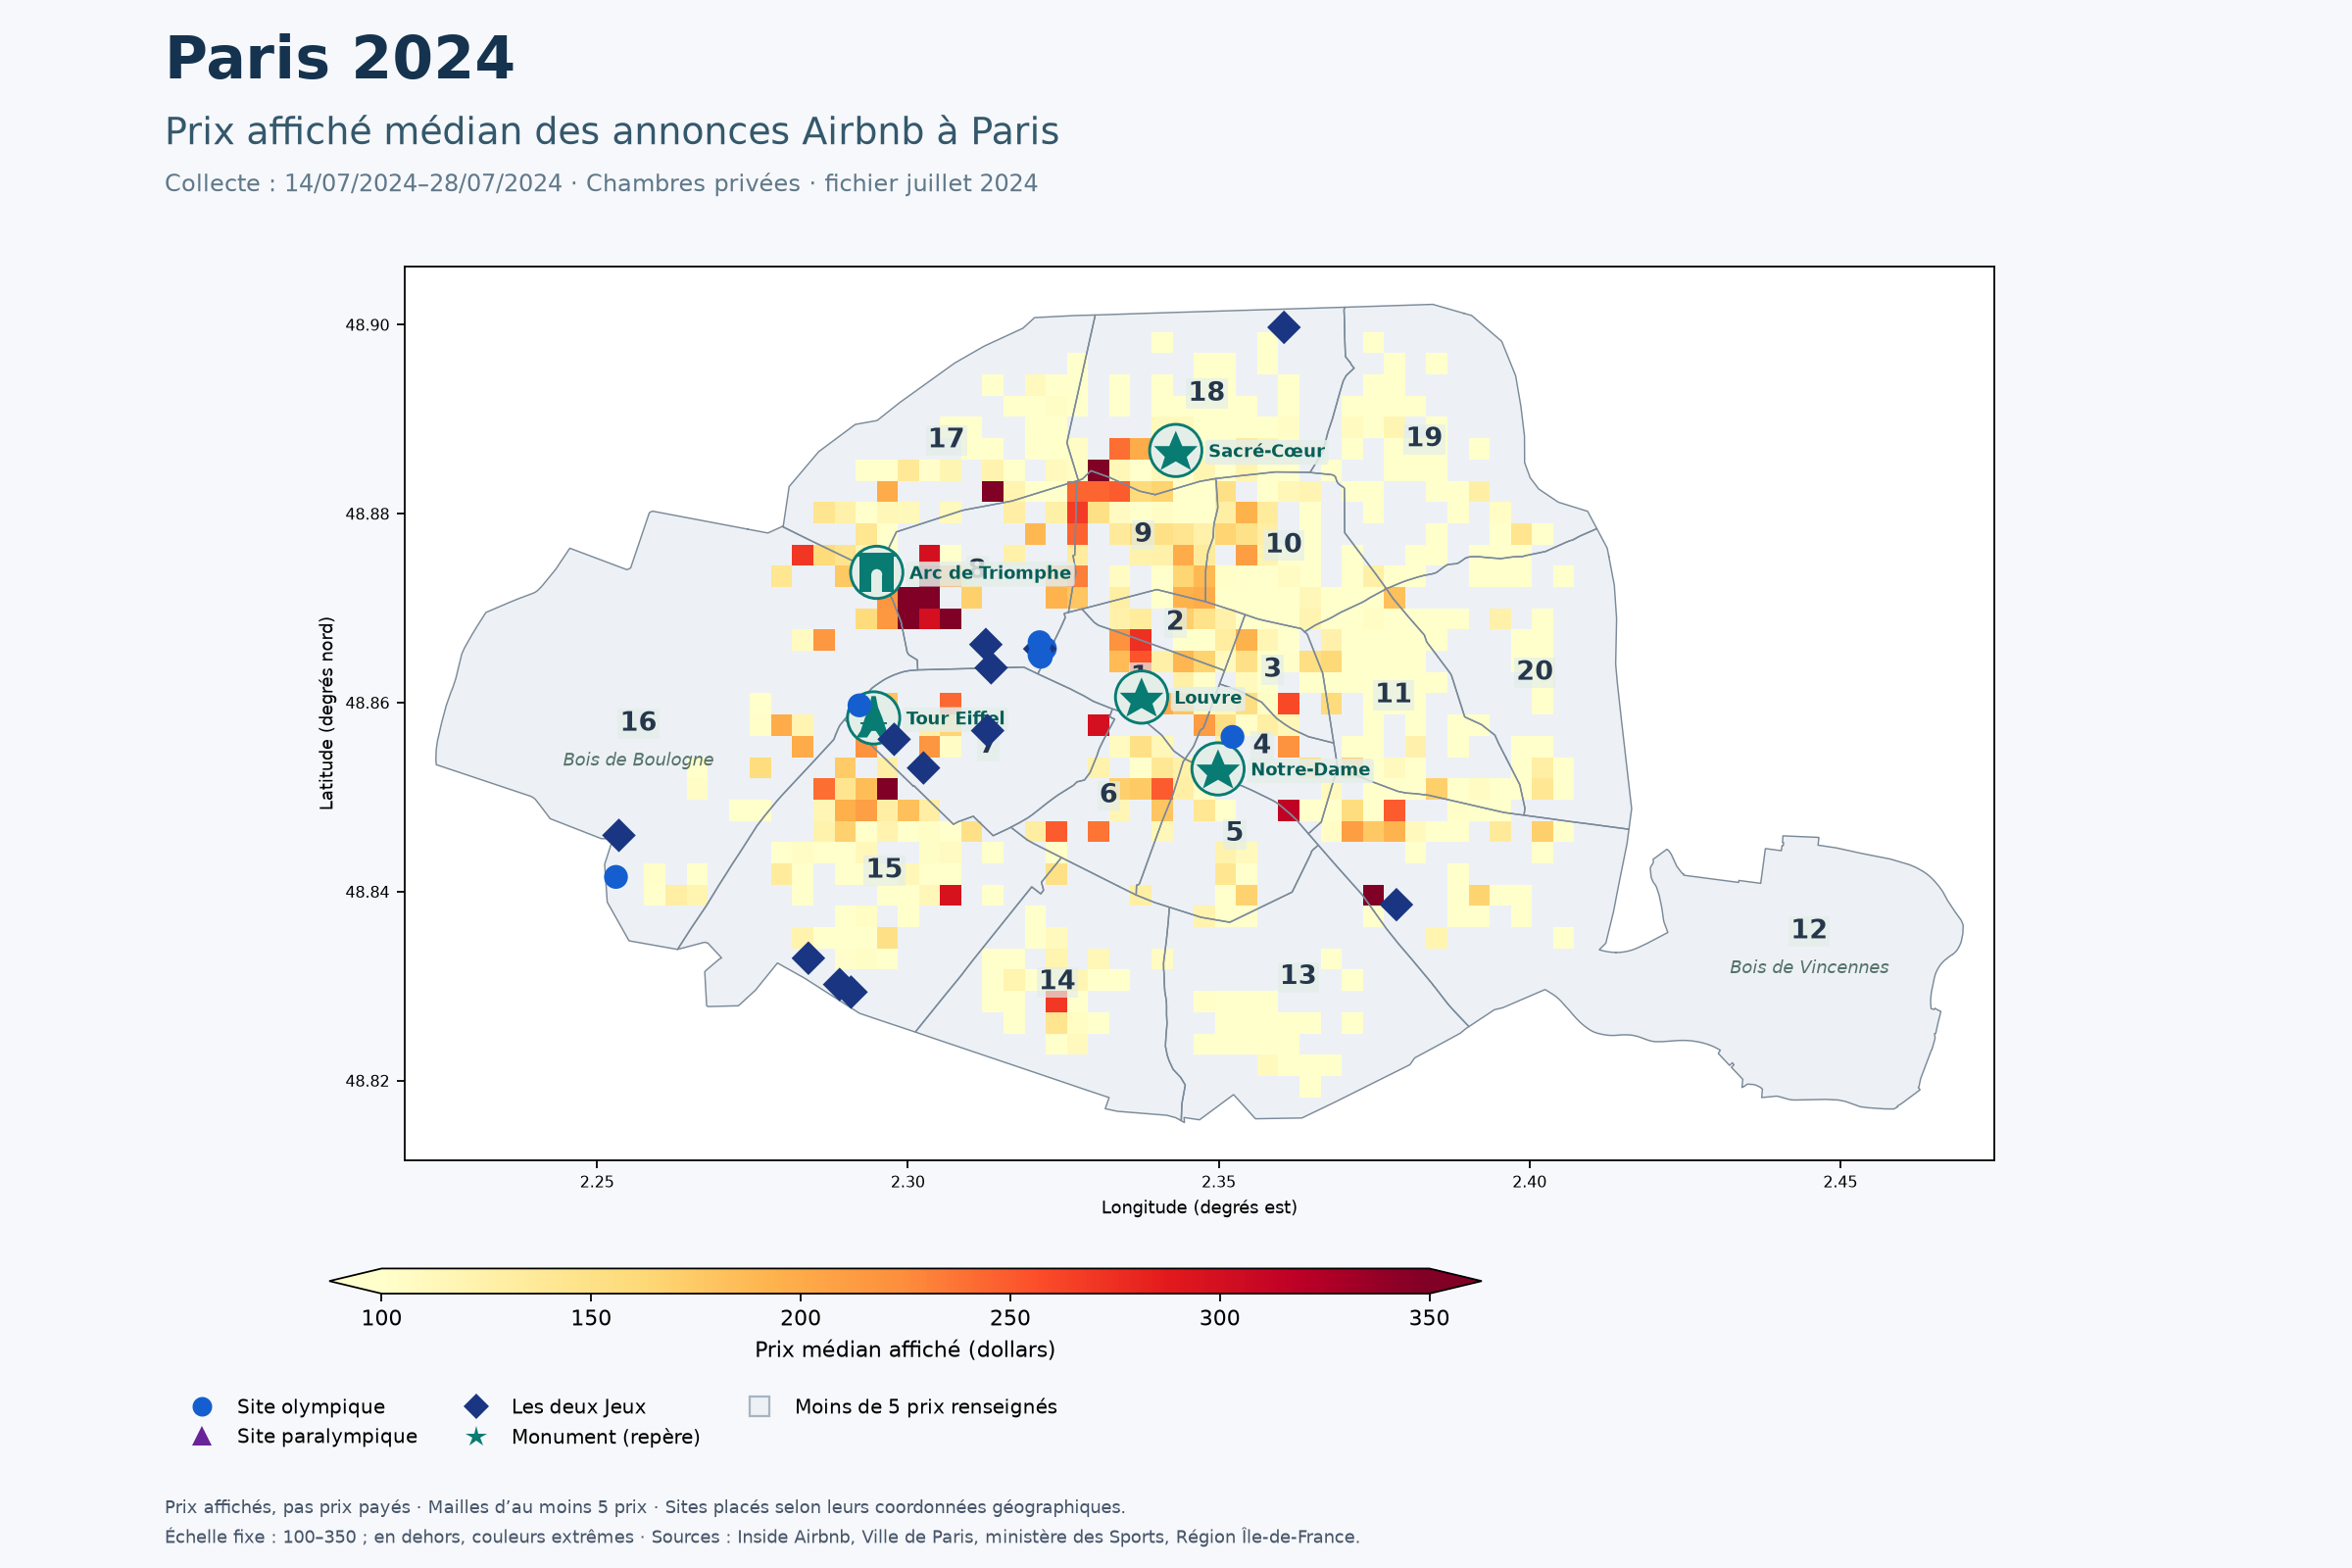
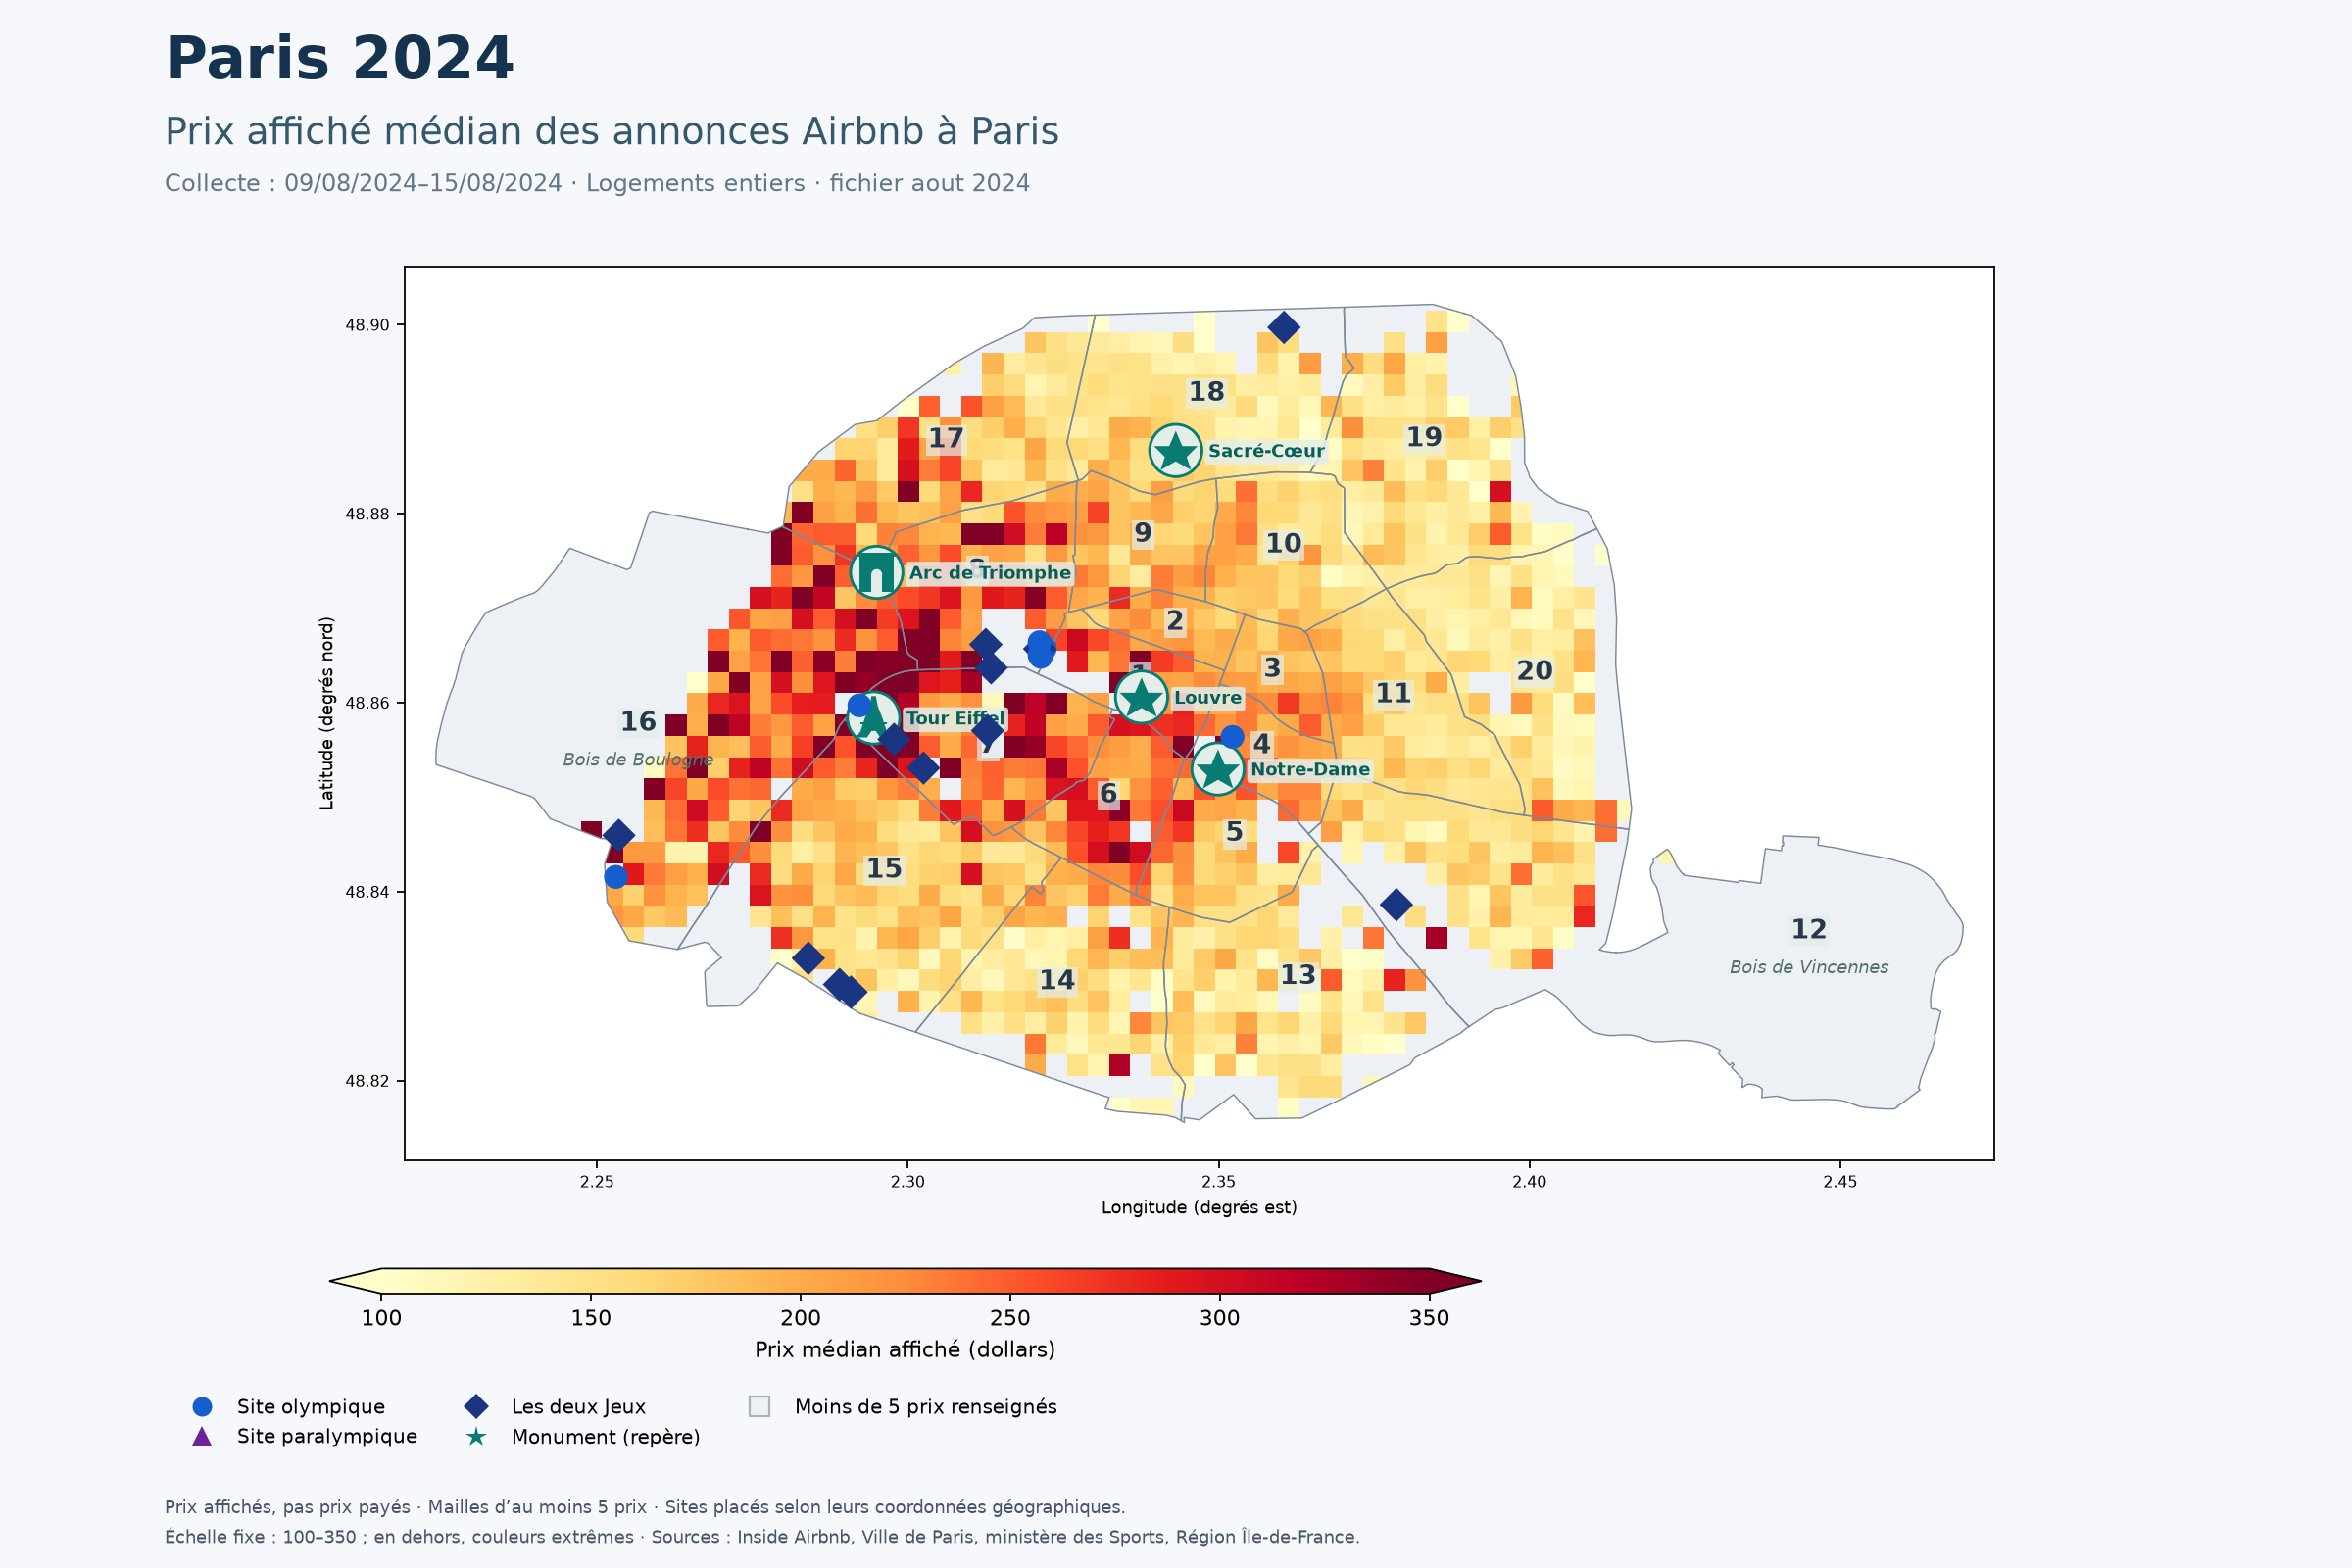
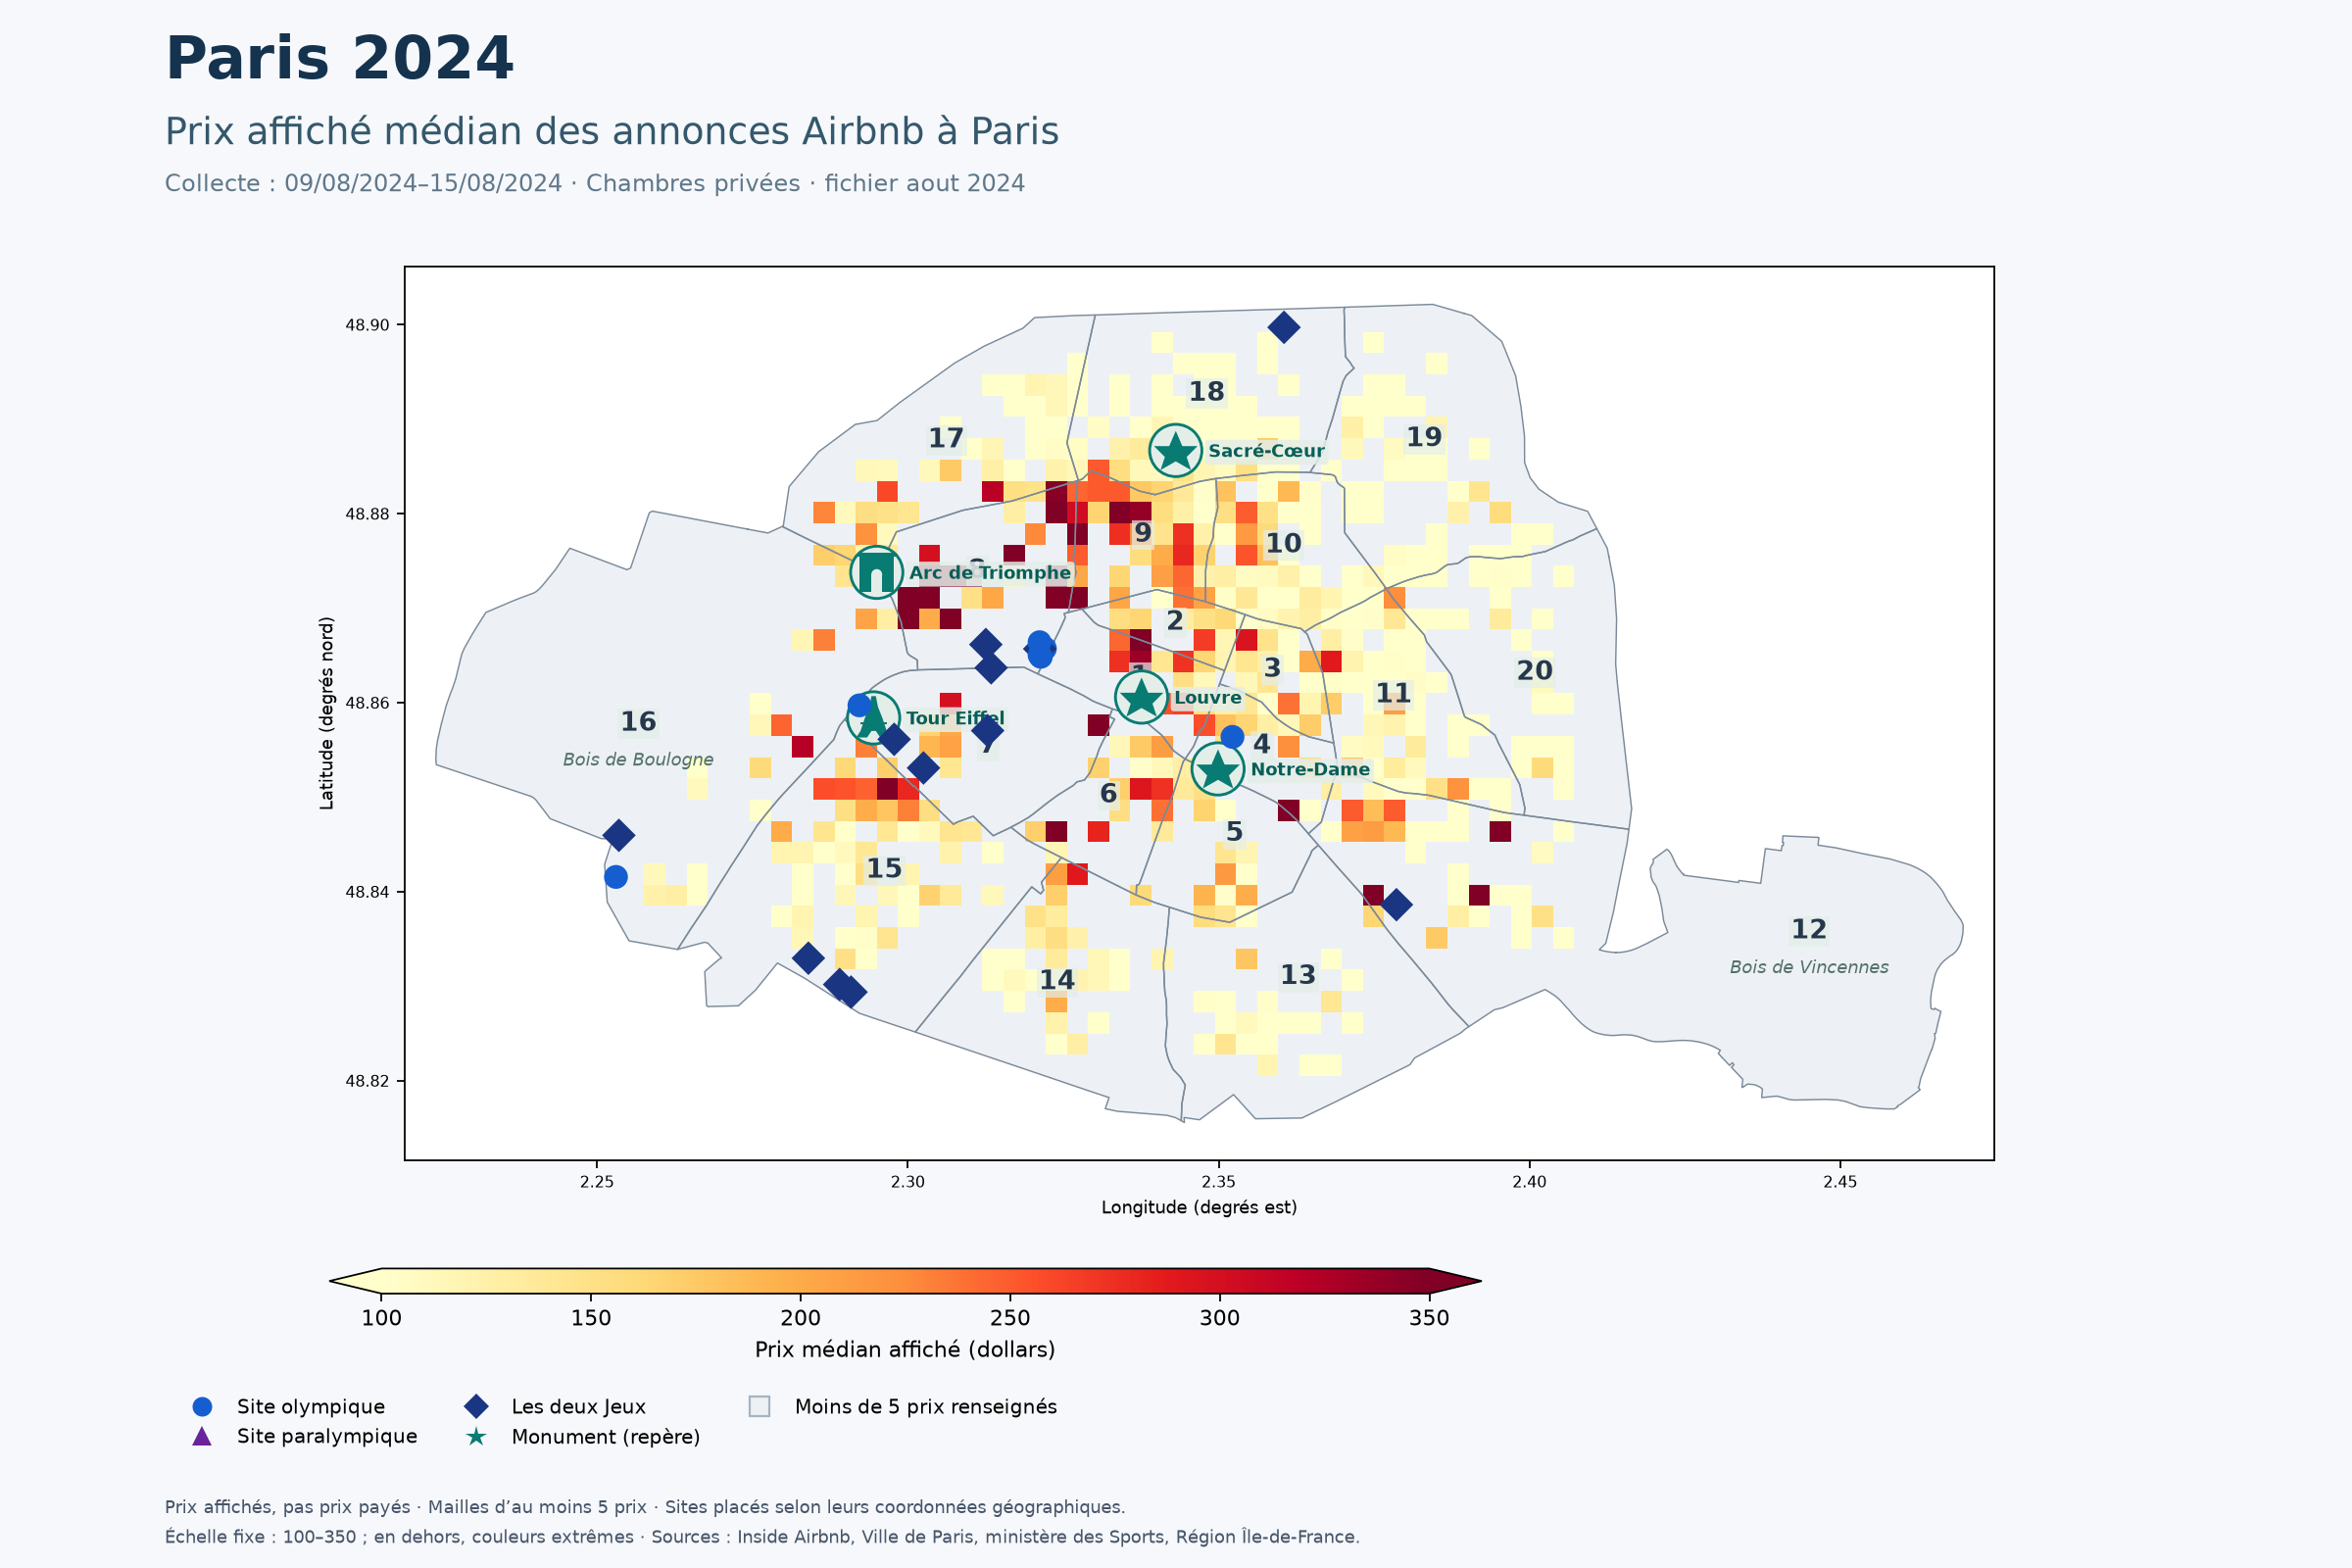
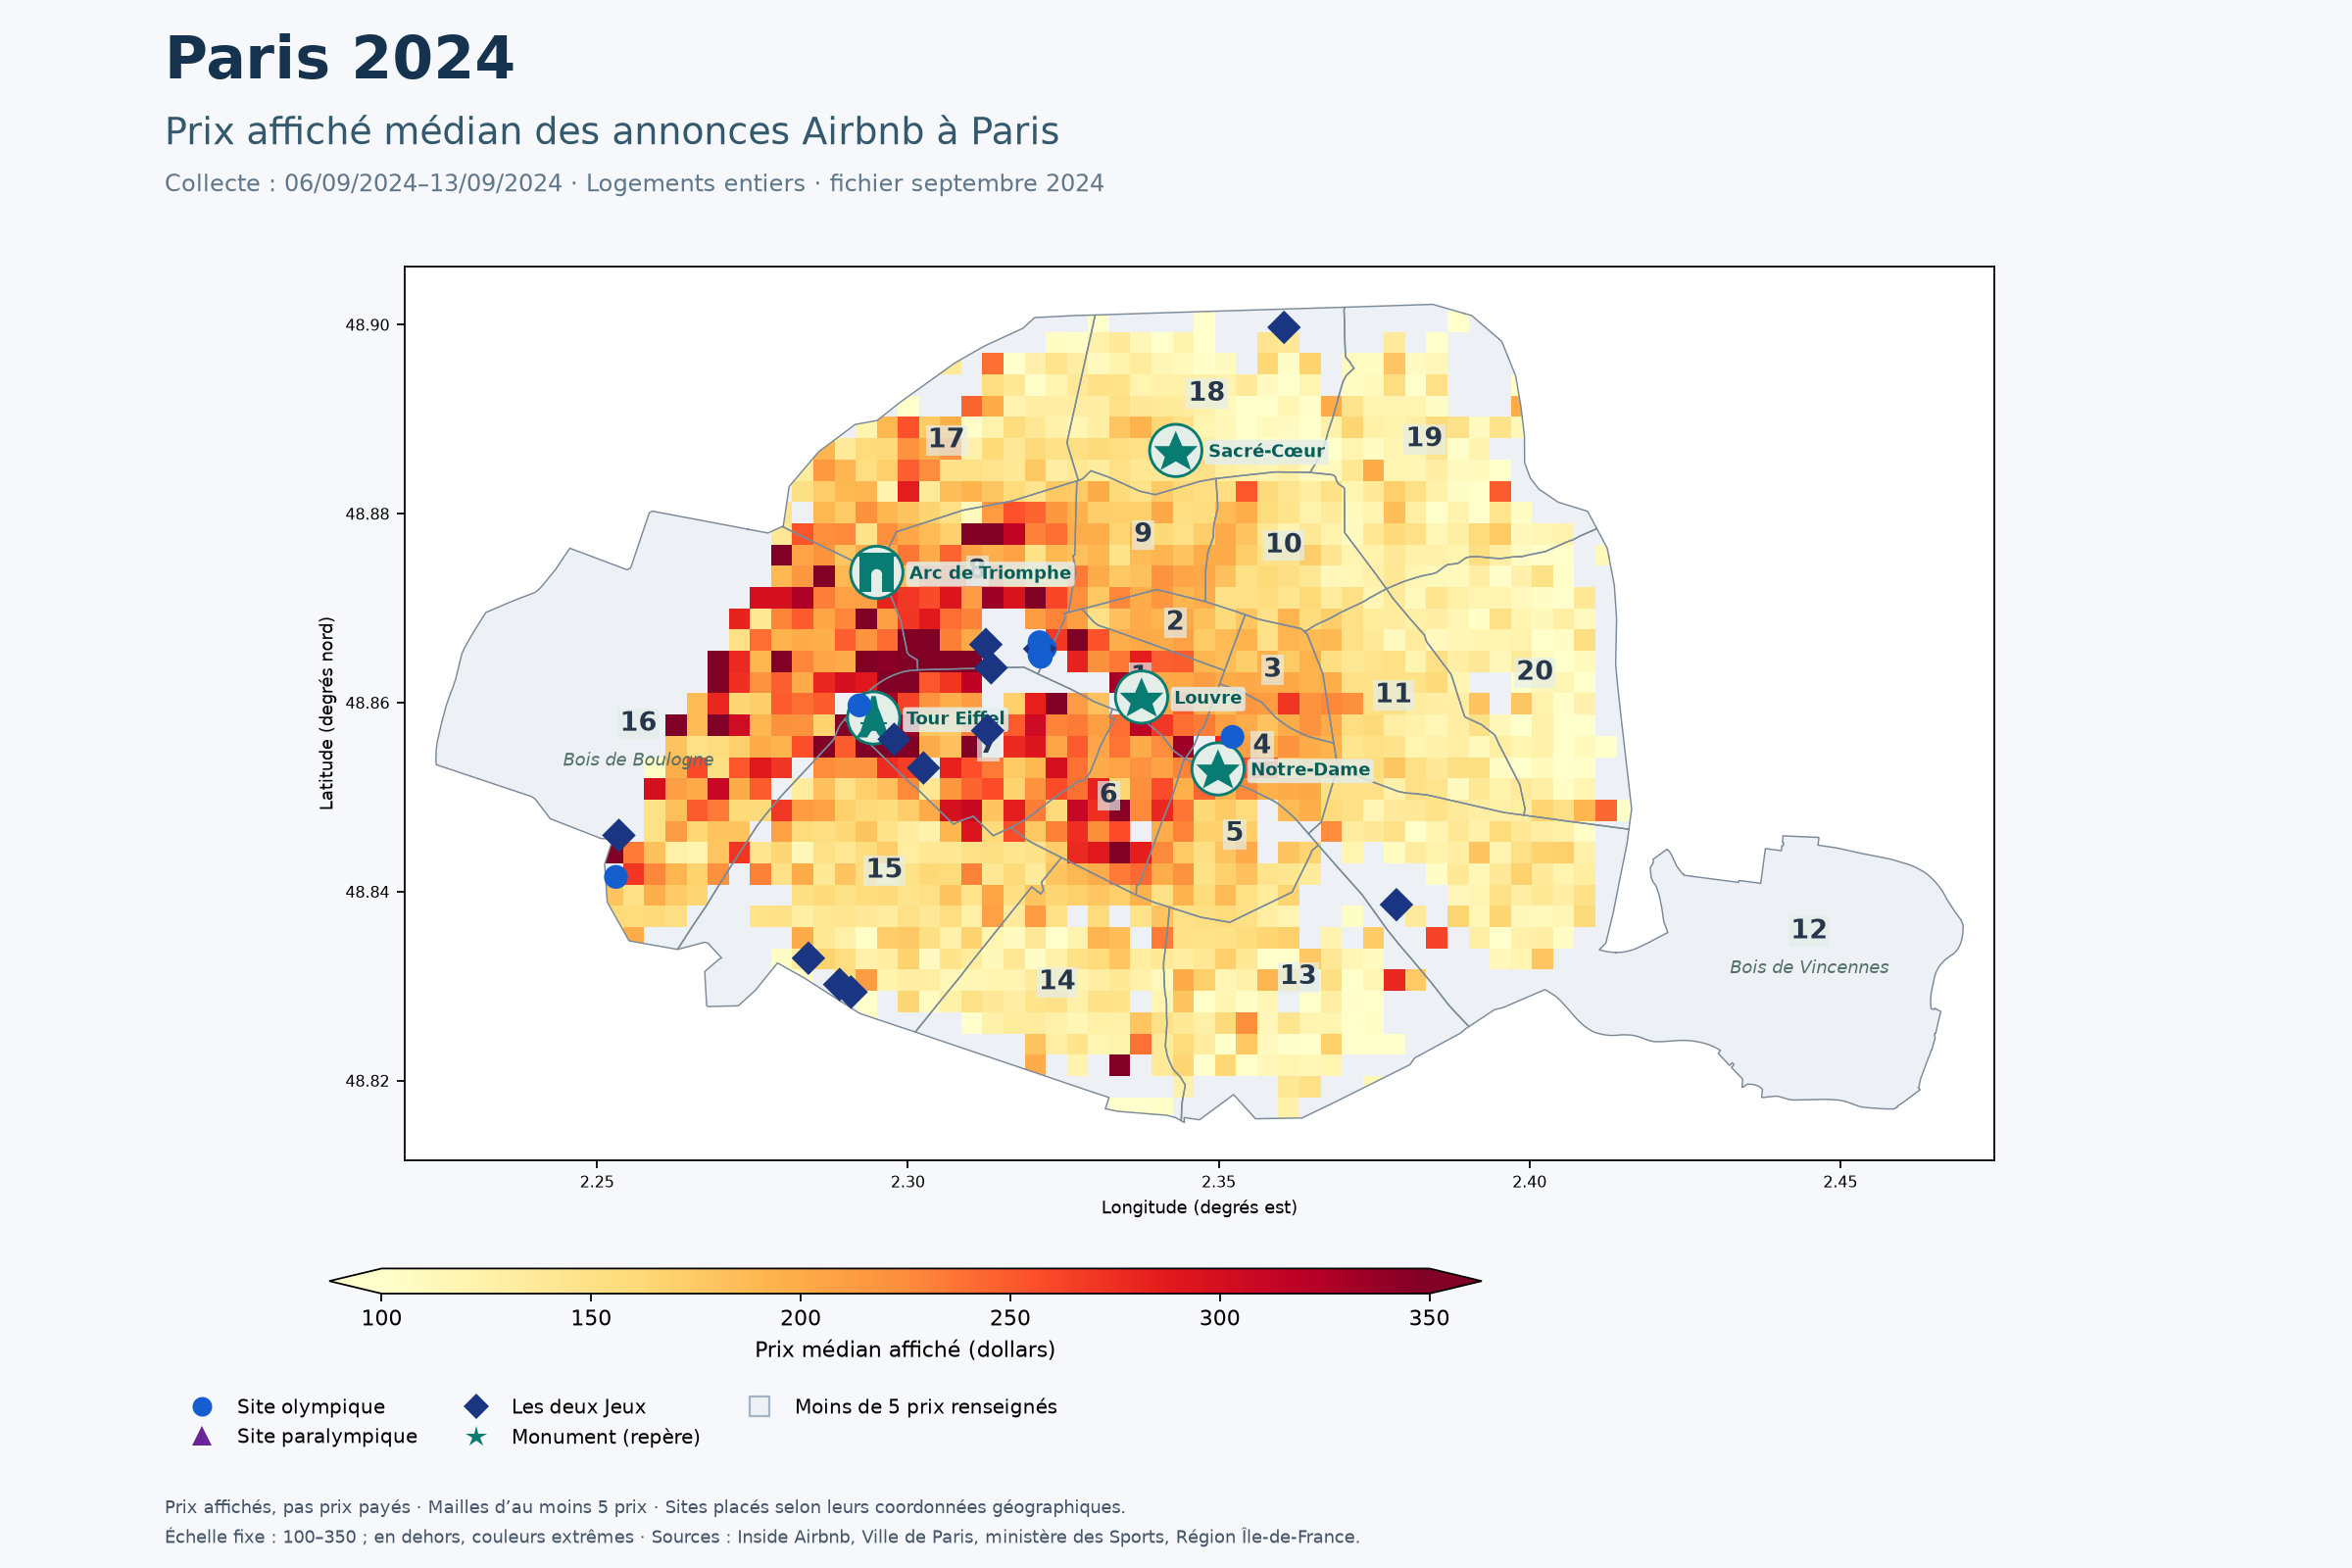
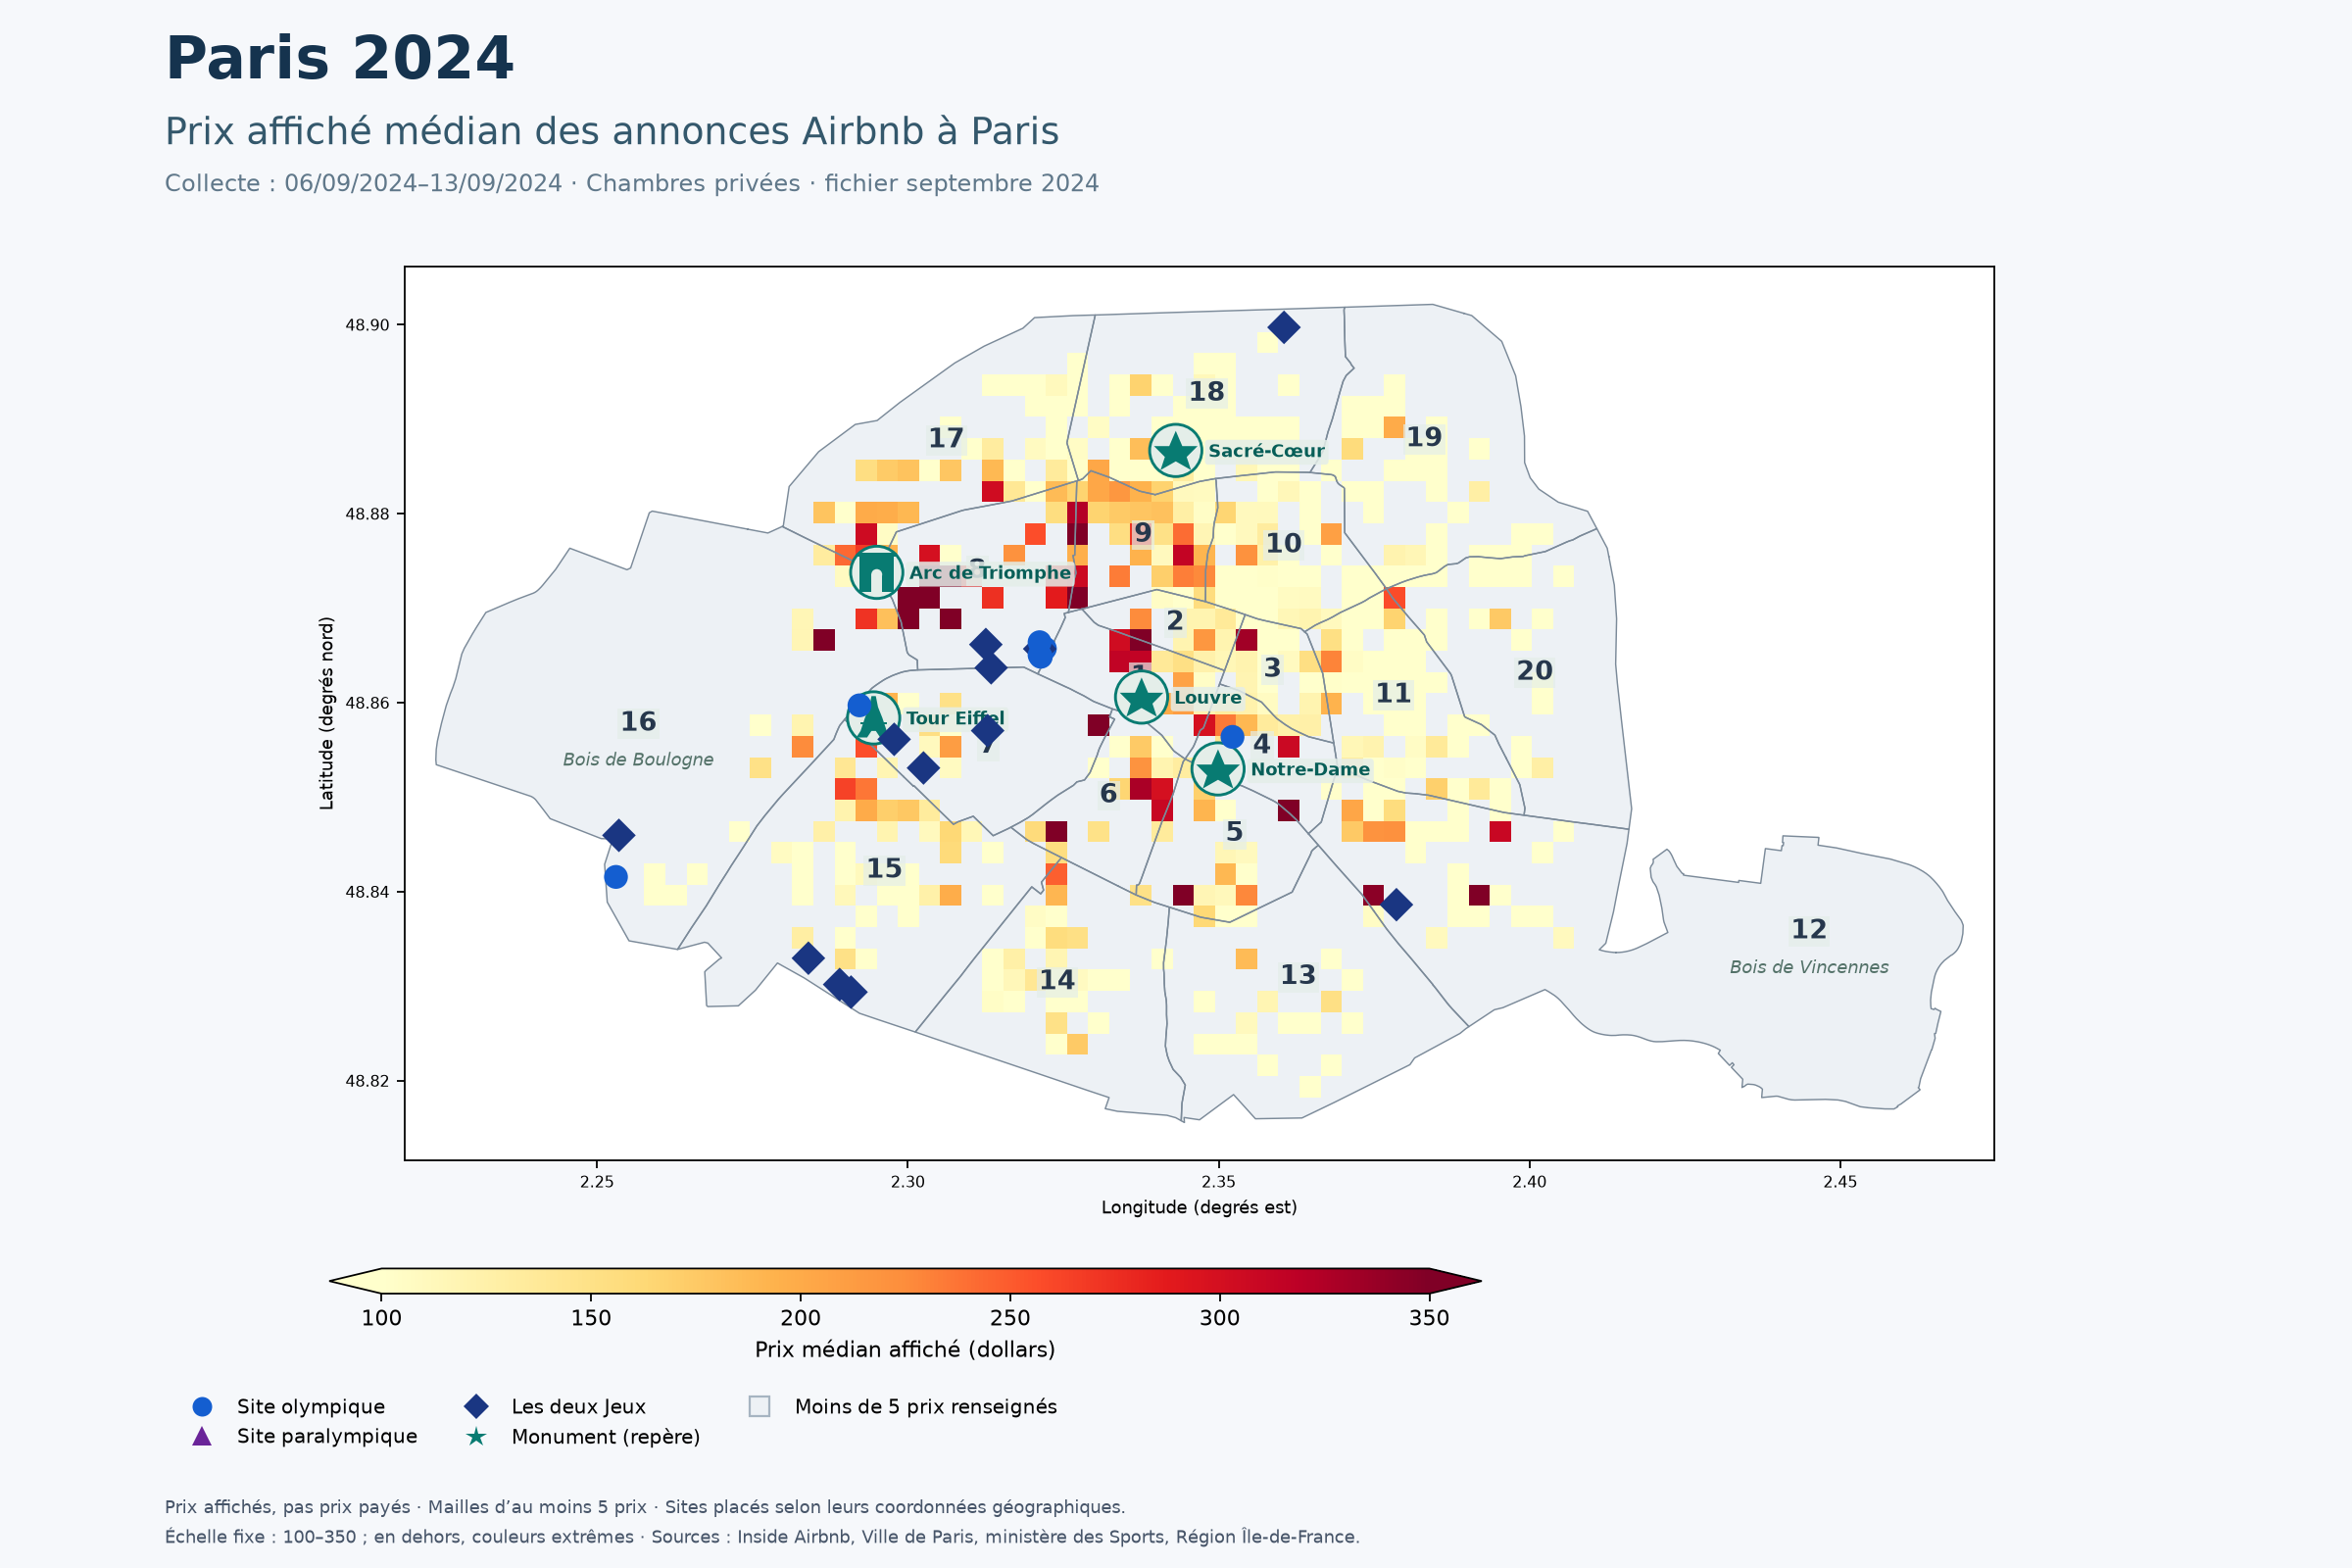

In [8]:
cartes_types = [f"cartes prix/analyses complementaires/carte_prix_paris_{mois}_{type_logement}.png"
               for mois in ["juillet", "aout", "septembre"] for type_logement in ["entiers", "chambres"]]
legendes_types = {}
for fichier in cartes_types:
    mois = next(m for m in ["juillet", "aout", "septembre"] if f"_{m}_" in fichier)
    categorie = "logements entiers" if "_entiers" in fichier else "chambres privées"
    legendes_types[fichier] = f"{mois.capitalize()} : {categorie}. Même échelle de prix ; gris : moins de cinq prix exploitables."
import base64
from html import escape
from IPython.display import HTML

images_types = []
for fichier in cartes_types:
    contenu = base64.b64encode(Path(fichier).read_bytes()).decode("ascii")
    images_types.append(f'<figure><img src="data:image/png;base64,{contenu}" style="width:100%;max-width:1000px" alt="{escape(legendes_types[fichier])}"/><figcaption>{escape(legendes_types[fichier])}</figcaption></figure>')
display(HTML('<details><summary>Afficher les six cartes par type — juillet, août et septembre 2024</summary>' + ''.join(images_types) + '</details>'))

### Ce que montrent les six cartes par type de logement

En juillet, les logements entiers dessinent déjà un ensemble de mailles chères dans le centre-ouest, autour de la Tour Eiffel, des Invalides et des Champs-Élysées. En août, cet ensemble s'étend ou se renforce par endroits, mais sans déplacement logique vers tous les sites de compétition. En septembre, cet ensemble reste toujours visible malgré la baisse de la médiane parisienne. Le voisinage de la Porte de la Chapelle demeure nettement moins cher que celui des sites centraux. La présence d'une compétition n'efface donc pas la hiérarchie entre les quartiers.

Les évolutions des prix des chambres privées sont, elles, moins continues. Quelques mailles chères apparaissent près de l'Arc de Triomphe, dans le 9e et dans le centre, tandis que beaucoup d'autres restent sous le seuil de cinq prix. Certaines de ces mailles sont visibles durant les trois périodes (juillet, août et septembre). 

La médiane des chambres privées augmente de 103 à 120 dollars entre juillet et août, soit 16,5 %, contre 7,3 % pour les logements entiers, de 164 à 176 dollars. La hausse proportionnelle est plus forte pour les chambres, mais leur faible nombre rend leur carte plus fragile. Une même couleur représente le même prix dans les deux catégories, pas la même densité d'annonces.

Enfin, une maille peut changer de couleur parce que ses prix évoluent ou parce que les annonces renseignées ne sont plus les mêmes. Le calcul suivant garde les mailles présentes aux deux dates, avec au moins cinq prix à chaque fois. Il améliore la comparabilité géographique, sans constituer un suivi des mêmes logements.

In [9]:
import numpy as np
from importation_données import lire_releve, charger_contours
from carte_sites_paris import preparer_population
from shapely.geometry import shape
from shapely.ops import unary_union

paris_ete = unary_union([shape(f["geometry"]) for f in charger_contours()])
populations_ete = {}
for mois in ["juin", "juillet", "aout", "septembre"]:
    brut = lire_releve(2024, mois)
    brut["prix"] = pd.to_numeric(brut["price"].astype("string").str.replace(r"[$,]", "", regex=True), errors="coerce")
    for colonne in ["latitude", "longitude"]:
        brut[colonne] = pd.to_numeric(brut[colonne], errors="coerce")
    populations_ete[mois] = preparer_population(brut, paris_ete)[0]

mailles_par_type = {}
for mois in ["juillet", "aout", "septembre"]:
    valides = populations_ete[mois].loc[populations_ete[mois]["prix_valide"]].copy()
    valides["x"] = np.floor(valides.longitude / 0.0034).astype(int)
    valides["y"] = np.floor(valides.latitude / 0.00225).astype(int)
    for nom, categorie in [("Tous types", None), ("Logements entiers", "Entire home/apt"), ("Chambres privées", "Private room")]:
        sous = valides if categorie is None else valides.loc[valides.room_type.eq(categorie)]
        mailles = sous.groupby(["x", "y"])["prix"].agg(prix_median="median", effectif="count")
        mailles_par_type[(mois, nom)] = mailles.loc[mailles.effectif.ge(5)]

comparaisons_mailles = []
for categorie in ["Tous types", "Logements entiers", "Chambres privées"]:
    for debut, fin in [("juillet", "aout"), ("aout", "septembre")]:
        communes = mailles_par_type[(debut, categorie)].join(mailles_par_type[(fin, categorie)],
                    how="inner", lsuffix="_debut", rsuffix="_fin")
        variation = 100 * (communes.prix_median_fin / communes.prix_median_debut - 1)
        comparaisons_mailles.append({"type": categorie, "comparaison": f"{debut} → {fin}",
            "mailles communes": len(communes), "variation médiane des mailles (%)": variation.median(),
            "mailles en hausse (%)": 100 * variation.gt(0).mean()})
comparaison_mailles = pd.DataFrame(comparaisons_mailles)
display(comparaison_mailles.set_index(["type", "comparaison"]).round(1))

C:\Users\assia\AppData\Local\Temp\ipykernel_23236\2899069647.py:29: Pandas4Warning: The 'lsuffix' and 'rsuffix' keywords in DataFrame.join are deprecated and will be removed in a future version. Use the 'suffixes' keyword instead.
  communes = mailles_par_type[(debut, categorie)].join(mailles_par_type[(fin, categorie)],
C:\Users\assia\AppData\Local\Temp\ipykernel_23236\2899069647.py:29: Pandas4Warning: The 'lsuffix' and 'rsuffix' keywords in DataFrame.join are deprecated and will be removed in a future version. Use the 'suffixes' keyword instead.
  communes = mailles_par_type[(debut, categorie)].join(mailles_par_type[(fin, categorie)],
C:\Users\assia\AppData\Local\Temp\ipykernel_23236\2899069647.py:29: Pandas4Warning: The 'lsuffix' and 'rsuffix' keywords in DataFrame.join are deprecated and will be removed in a future version. Use the 'suffixes' keyword instead.
  communes = mailles_par_type[(debut, categorie)].join(mailles_par_type[(fin, categorie)],
C:\Users\assia\AppData\Local\Temp\

mailles communes  \
type              comparaison                          
Tous types        juillet → aout                1212   
                  aout → septembre              1199   
Logements entiers juillet → aout                1193   
                  aout → septembre              1177   
Chambres privées  juillet → aout                 478   
                  aout → septembre               438   

                                    variation médiane des mailles (%)  \
type              comparaison                                           
Tous types        juillet → aout                                  6.2   
                  aout → septembre                               -8.3   
Logements entiers juillet → aout                                  5.6   
                  aout → septembre                               -8.4   
Chambres privées  juillet → aout                                 10.9   
                  aout → septembre                               -6.4   

                                    mailles en hausse (%)  
type              comparaison                              
Tous types        juillet → aout                     72.3  
                  aout → septembre                   18.8  
Logements entiers juillet → aout                     69.9  
                  aout → septembre                   18.7  
Chambres privées  juillet → aout                     70.7  
                  aout → septembre                   32.0

Sur les **1 212 mailles communes** aux cartes tous types de juillet et d'août, 72,3 % voient leur médiane augmenter. La variation médiane de ces mailles est de +6,2 %. La hausse est donc assez largement répartie dans les zones renseignées ; elle ne se réduit pas à quelques points rouges autour d'une compétition. Cette mesure donne le même poids à chaque maille, alors que la médiane parisienne porte sur les annonces.

Pour les logements entiers, 69,9 % des 1 193 mailles communes augmentent, avec une variation médiane de +5,6 %. Pour les chambres privées, les valeurs correspondantes sont de 70,7 % et +10,9 %, mais sur seulement 478 mailles. Le signal d'août existe donc dans les deux catégories. La couverture spatiale des chambres reste bien plus restreinte, ce qui invite à ne pas extrapoler leur hausse aux secteurs non renseignés.

Entre août et septembre, le mouvement s'inverse : la variation médiane des mailles communes est de −8,3 % tous types, −8,4 % pour les logements entiers et −6,4 % pour les chambres. Le tableau confirme ainsi un mouvement estival suivi d'un repli, déjà perceptible sur les cartes. Il ne permet pas d'en isoler la cause : saison touristique, composition des annonces, calendrier de collecte et Jeux évoluent simultanément.

### 5.3. Dix-neuf sites, plusieurs géographies de prix

Les graphiques construits dans le programme prix_en_fonction_de_la_distance.py représentent des **moyennes par tranche de 1 km autour de chaque site olympique parisien**, à différents relevés de 2024. Le point 0 correspond à moins de 1 km ; le point 1 à la tranche de 1 à moins de 2 km. Les prix sont en dollars. 

Nous les lisons par familles de profils. Les galeries ci-dessous contiennent tous les graphiques, avec un commentaire propre à chaque site. Le mois de mars est écarté de toute analyse car il duplique celui de juin.

#### Centre-ouest : Tour Eiffel, Trocadéro, Invalides, Grand Palais et Alexandre III

Autour de la Tour Eiffel, du Trocadéro, des Invalides, du Grand Palais et du pont Alexandre III, les prix moyens sont généralement plus élevés près des sites, puis diminuent sur les premiers kilomètres. Cette tendance apparaît sur plusieurs relevés, avant comme après les Jeux. Au Trocadéro, certaines courbes du printemps ou de l’automne dépassent même celles de juillet et d’août : l’été olympique n’est donc pas systématiquement la période la plus chère.

Ces observations suggèrent que les prix élevés tiennent aussi à l’attractivité habituelle de ces quartiers touristiques. Elles ne suffisent pas à mesurer un effet des Jeux. De plus, ces cinq sites sont proches : une même annonce peut entrer dans plusieurs graphiques. Leur ressemblance décrit en partie un même secteur, plutôt que cinq effets distincts.


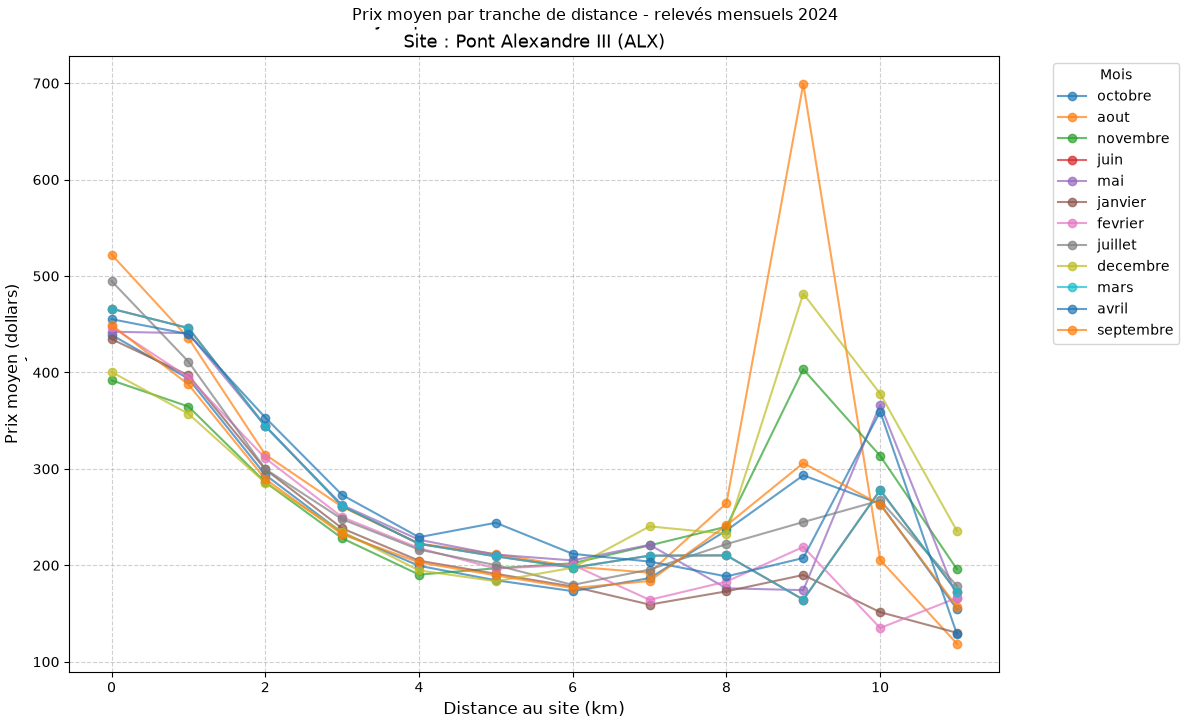
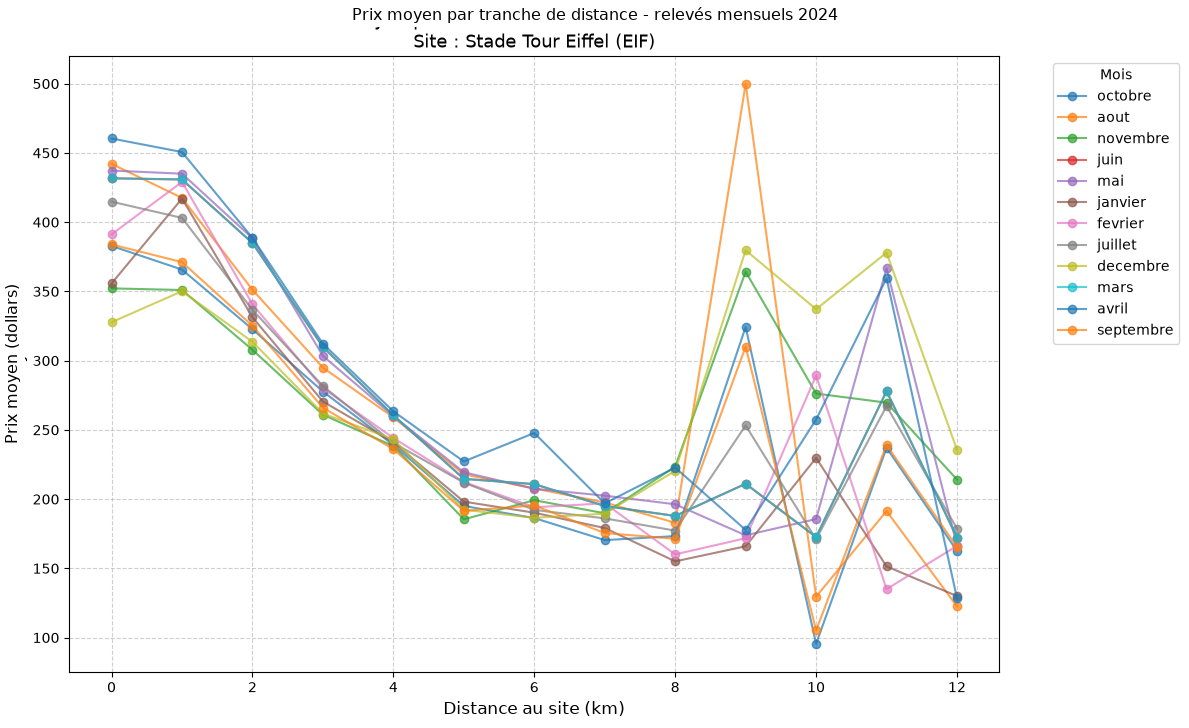
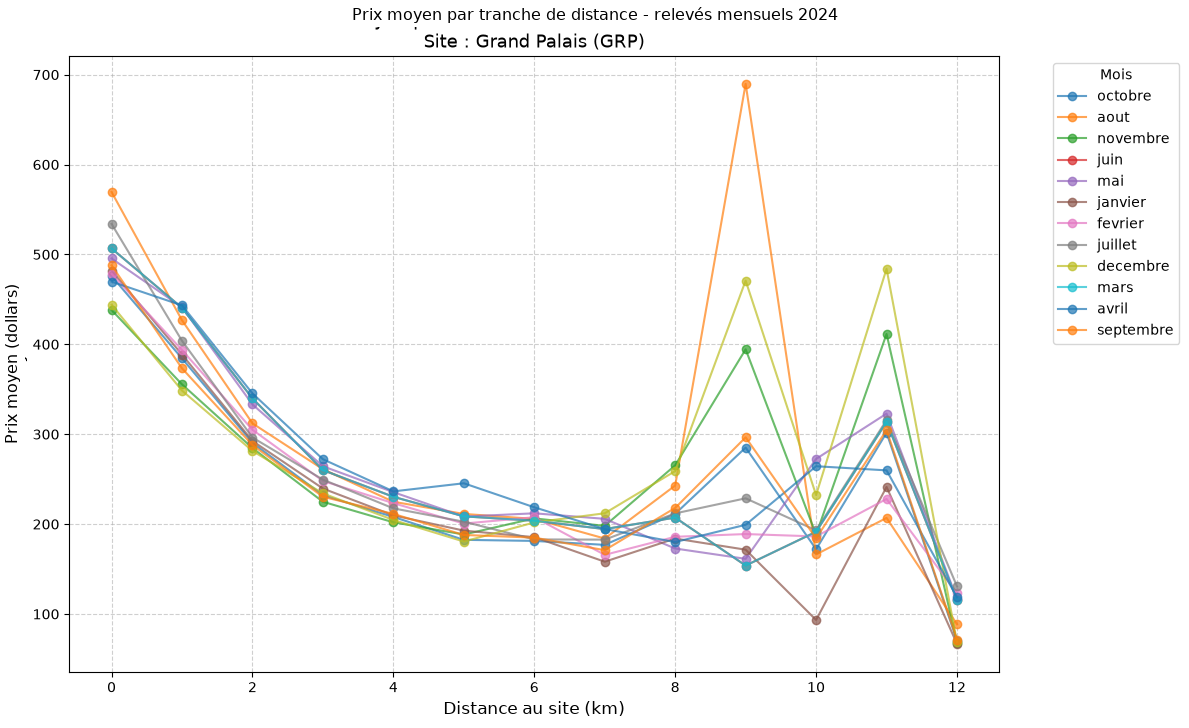
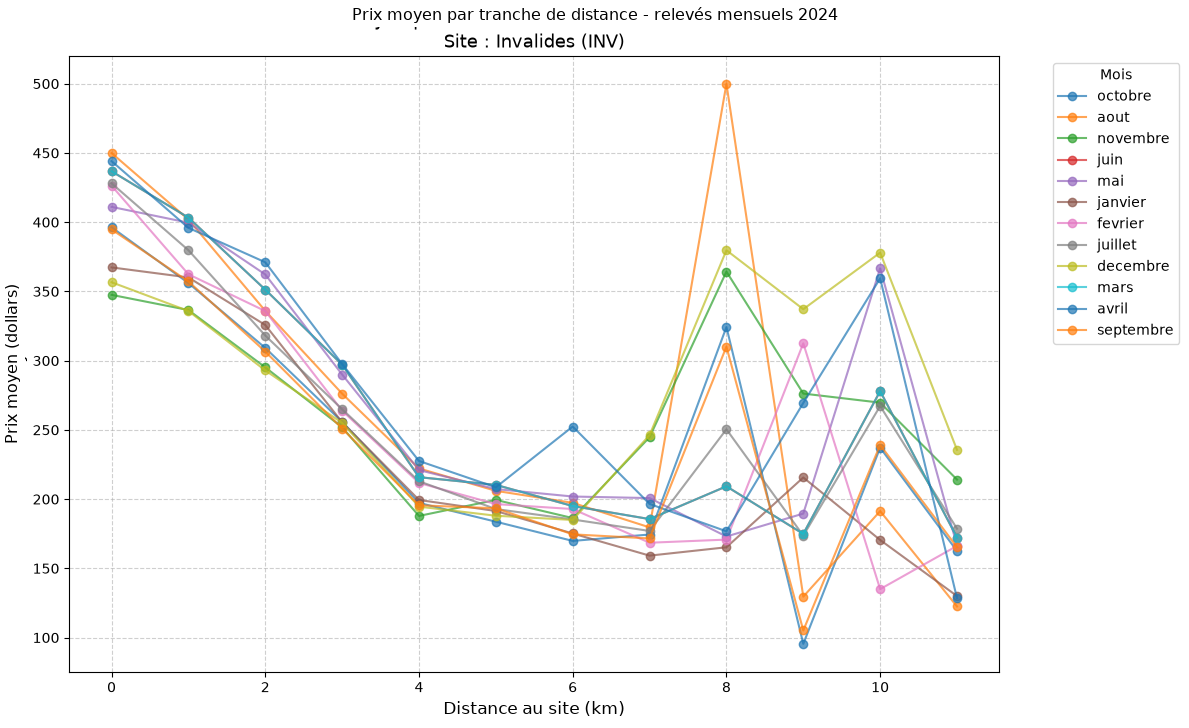
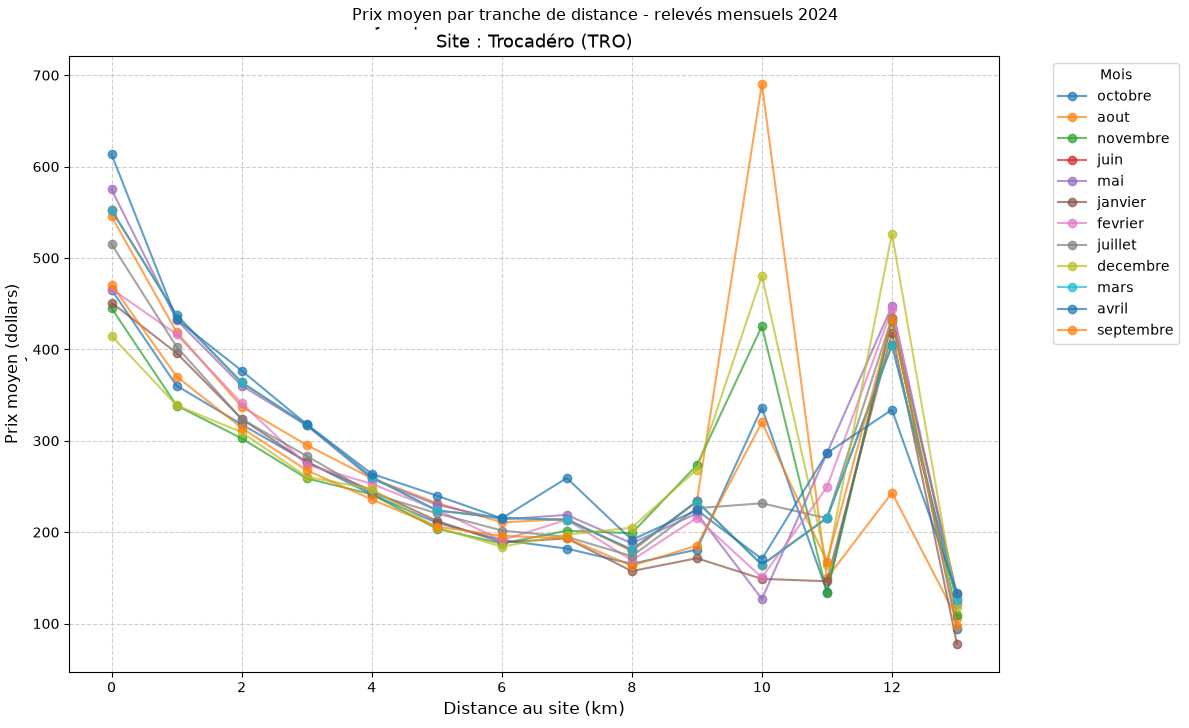

In [10]:
import base64
from html import escape
from IPython.display import HTML

codes_selectionnes = ['EIF', 'TRO', 'INV', 'GRP', 'ALX']
commentaires = {'EIF': 'Tour Eiffel : les prix moyens diminuent sur les premiers kilomètres, avant comme après l’été. Cette régularité suggère un lien avec l’emplacement touristique, sans permettre d’isoler un effet des Jeux.', 'TRO': 'Trocadéro : les annonces proches sont chères à plusieurs périodes de l’année. Certains relevés du printemps ou de l’automne dépassent ceux de juillet et d’août ; les Jeux ne coïncident donc pas systématiquement avec les prix les plus élevés.', 'INV': 'Invalides : les prix baissent nettement lorsqu’on s’éloigne de quelques kilomètres, à plusieurs mois de l’année. Le voisinage cher du site semble ainsi refléter aussi des différences habituelles entre quartiers.', 'GRP': 'Grand Palais : les prix proches du site dépassent ceux des distances intermédiaires sur plusieurs relevés. Le profil ressemble à celui des autres sites du centre-ouest, dont les voisinages se recouvrent en partie.', 'ALX': 'Pont Alexandre III : les prix diminuent sur les premiers kilomètres à plusieurs périodes de l’année. Les pics plus éloignés concernent d’autres quartiers et ne mesurent pas un surcoût dans le voisinage immédiat du pont.'}
figures = []
for fichier in sorted(Path("graphiques_sites_paris_tous_les_mois").glob("site_*.png")):
    code_site = fichier.name.split("_")[1]
    if code_site in codes_selectionnes:
        image = base64.b64encode(fichier.read_bytes()).decode("ascii")
        figures.append(f'<figure><img src="data:image/png;base64,{image}" style="width:100%;max-width:1000px" alt="{code_site}"/><figcaption>{escape(commentaires[code_site])}</figcaption></figure>')
display(HTML('<details><summary>Afficher les courbes de ce groupe — relevés 2024</summary>' + ''.join(figures) + '</details>'))

#### Concorde : un même secteur, plusieurs points de référence

Les graphiques de Concorde et de ses quatre sites voisins suivent un profil proche : les prix moyens sont élevés dans les premières tranches, puis diminuent lorsqu’on s’éloigne de quelques kilomètres. Cette forme se retrouve à plusieurs mois de l’année. Les annonces immédiatement voisines ne deviennent donc pas chères uniquement pendant les Jeux.

La similitude des cinq graphiques s’explique aussi par la proximité des points de départ, qui conduit à réutiliser largement les mêmes annonces. On ne peut pas y voir cinq confirmations indépendantes d’un effet olympique. Les pics observés plus loin changent selon les mois, notamment hors de l’été ; sans les effectifs de ces tranches, leur ampleur reste difficile à interpréter.


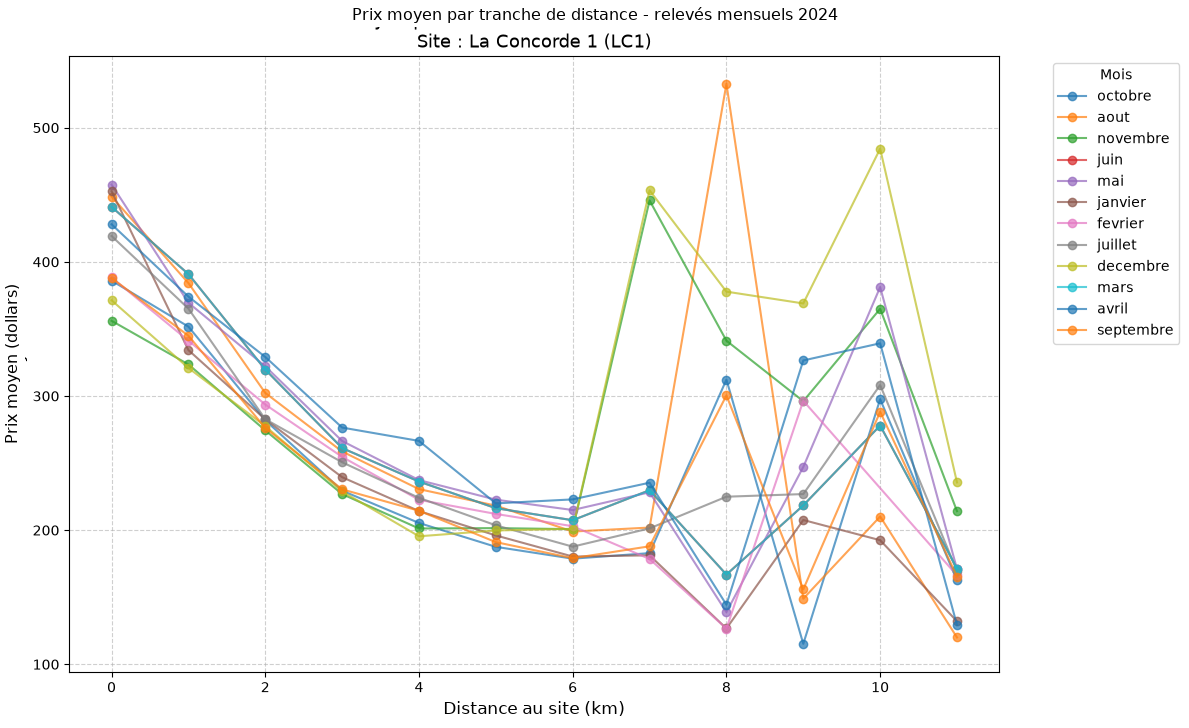
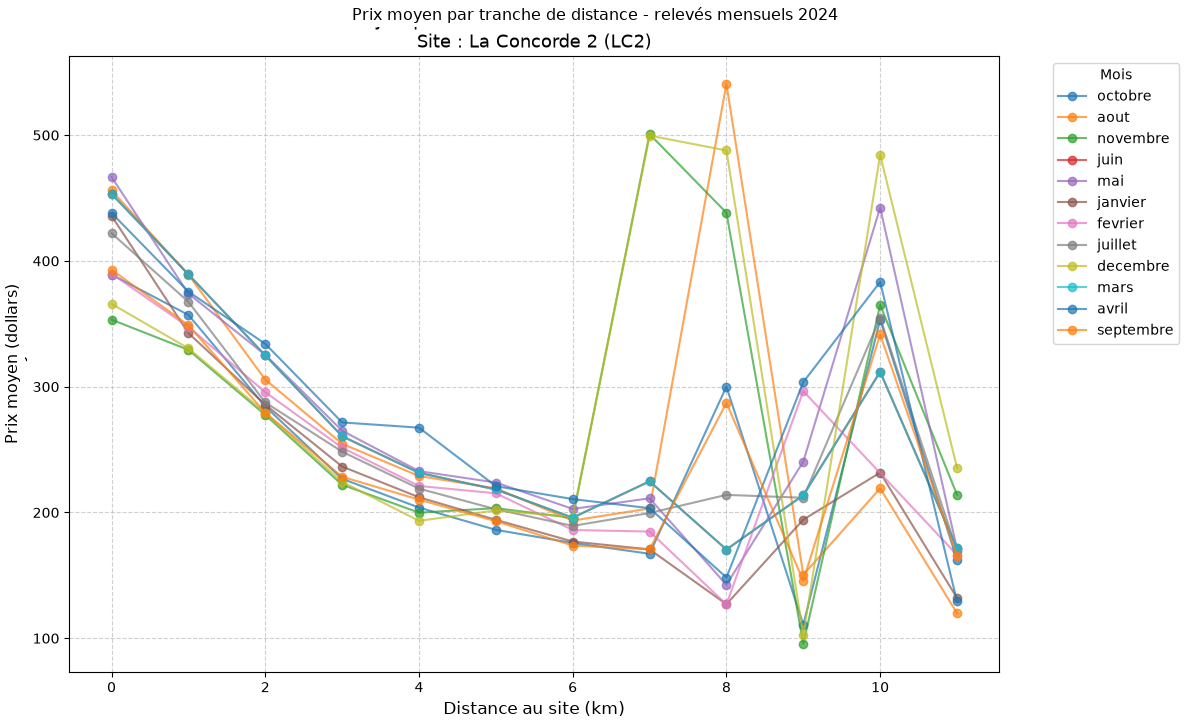
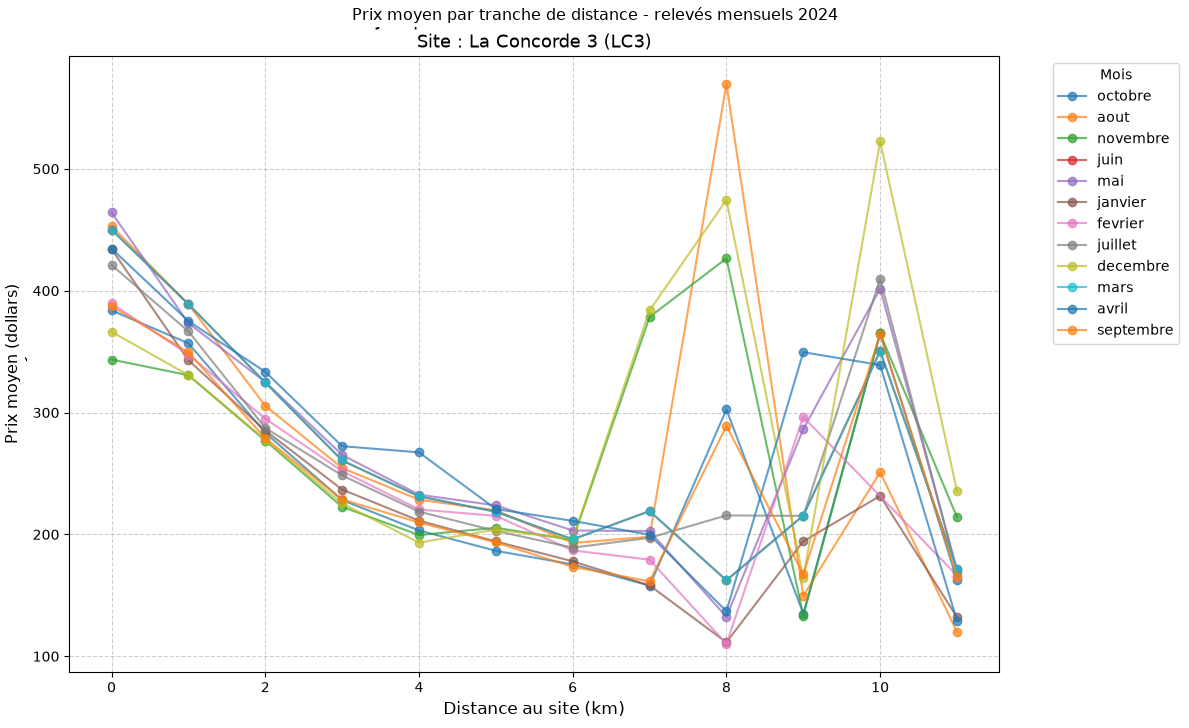
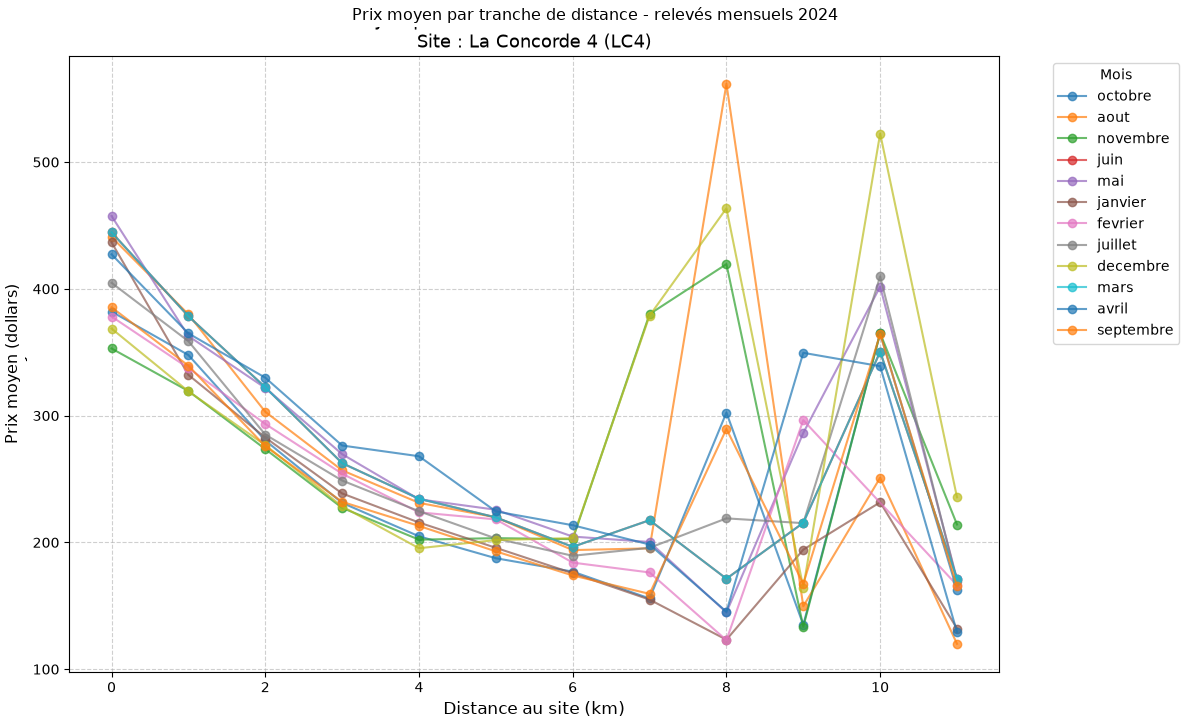
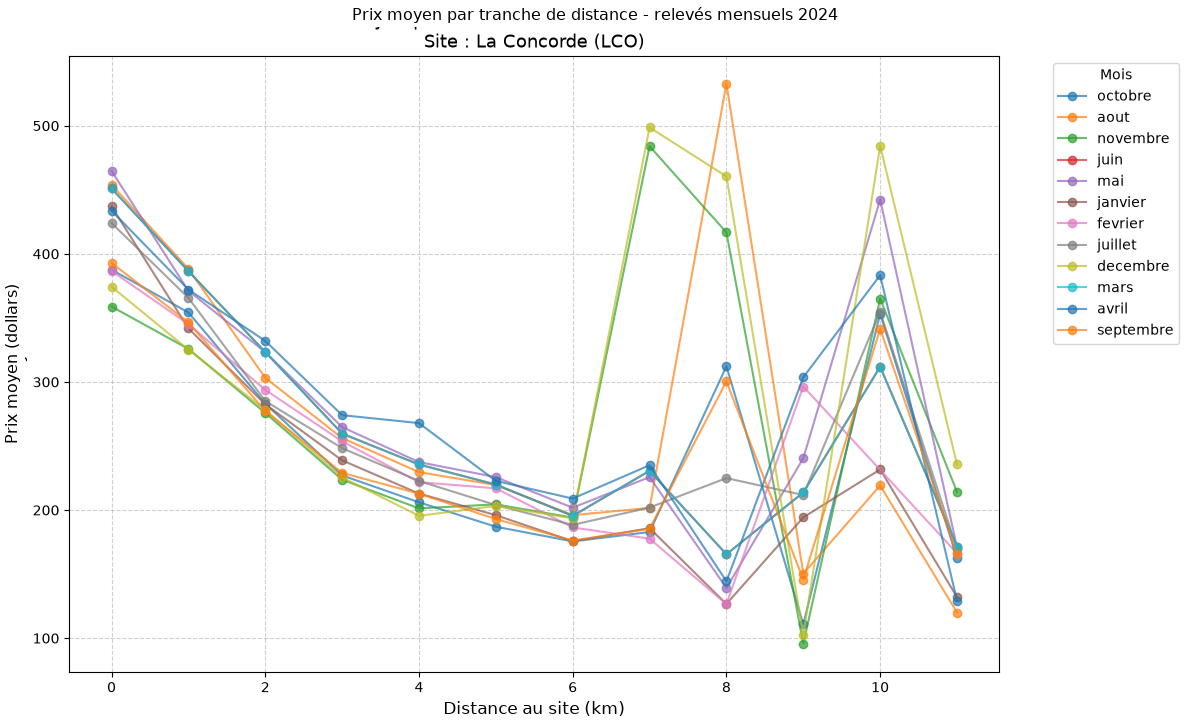

In [11]:
import base64
from html import escape
from IPython.display import HTML

codes_selectionnes = ['LCO', 'LC1', 'LC2', 'LC3', 'LC4']
commentaires = {'LCO': 'Concorde : les prix sont élevés près du site puis diminuent sur les premiers kilomètres, sur plusieurs relevés. Les variations lointaines, notamment en novembre et décembre, montrent que les écarts ne se limitent pas à l’été des Jeux.', 'LC1': 'Concorde 1 : les prix diminuent sur les premiers kilomètres, comme autour de Concorde. Les deux points étant proches, ils partagent largement les mêmes annonces ; leur ressemblance n’est pas une preuve indépendante d’un effet des Jeux.', 'LC2': 'Concorde 2 : la baisse initiale ressemble à celle des autres sites de Concorde. Les pics plus éloignés changent selon les mois et restent difficiles à interpréter sans connaître le nombre d’annonces de chaque tranche.', 'LC3': 'Concorde 3 : les prix baissent sur les premiers kilomètres à plusieurs mois de l’année. Cette tendance décrit une différence persistante entre les quartiers proches et plus éloignés, plutôt qu’un changement limité aux compétitions.', 'LC4': 'Concorde 4 : le profil rejoint ceux des autres points de Concorde, avec des prix plus élevés près du site. Leur proximité géographique et le recouvrement des annonces contribuent à cette similitude.'}
figures = []
for fichier in sorted(Path("graphiques_sites_paris_tous_les_mois").glob("site_*.png")):
    code_site = fichier.name.split("_")[1]
    if code_site in codes_selectionnes:
        image = base64.b64encode(fichier.read_bytes()).decode("ascii")
        figures.append(f'<figure><img src="data:image/png;base64,{image}" style="width:100%;max-width:1000px" alt="{code_site}"/><figcaption>{escape(commentaires[code_site])}</figcaption></figure>')
display(HTML('<details><summary>Afficher les courbes de ce groupe — relevés 2024</summary>' + ''.join(figures) + '</details>'))

#### Sud-ouest : Champ-de-Mars, Parc des Princes et Roland-Garros

Au Champ-de-Mars, le prix moyen est souvent un peu plus élevé entre 1 et moins de 2 km qu’à moins de 1 km, puis il diminue. Au Parc des Princes et à Roland-Garros, le maximum se situe lui aussi à quelques kilomètres du stade. Dans ces trois cas, les annonces immédiatement voisines ne sont donc pas systématiquement les plus chères.

Ce profil apparaît sur plusieurs relevés et ne se limite pas à l’été des Jeux. S’éloigner du site fait aussi changer de quartier et de caractéristiques de logement : ces différences peuvent contribuer au maximum décalé. Les courbes ne permettent toutefois ni de vérifier cette explication à elles seules, ni de conclure que les visiteurs recherchent une distance particulière par rapport au stade.


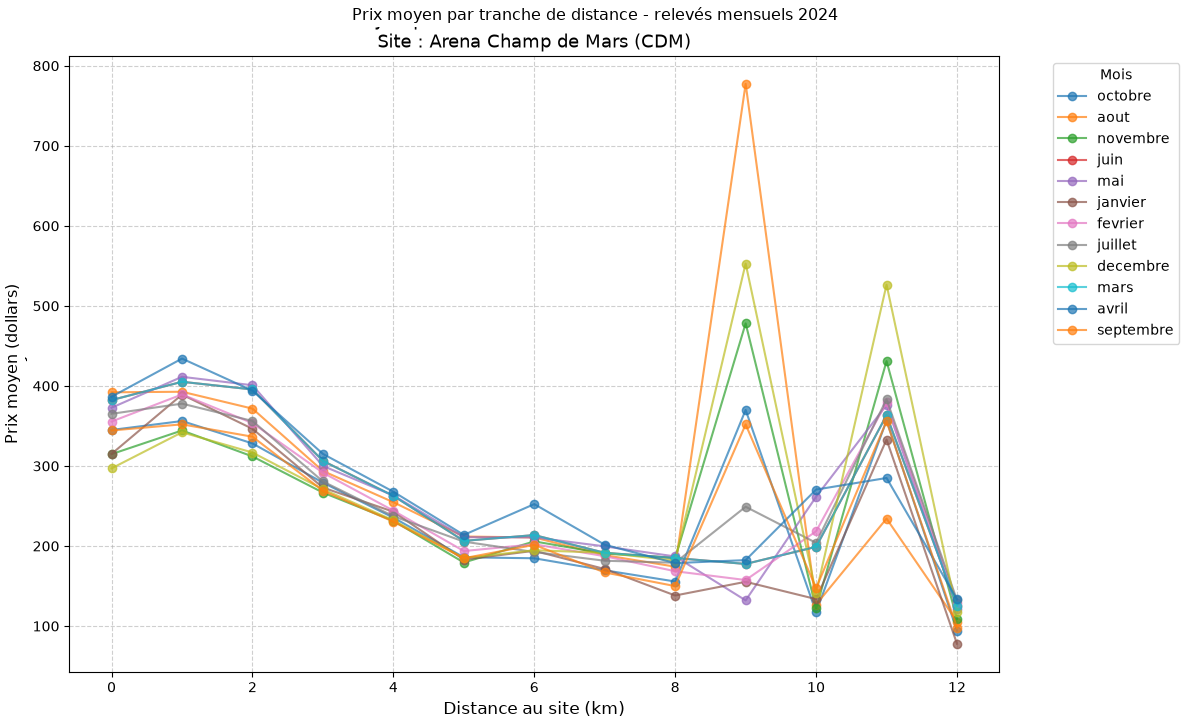
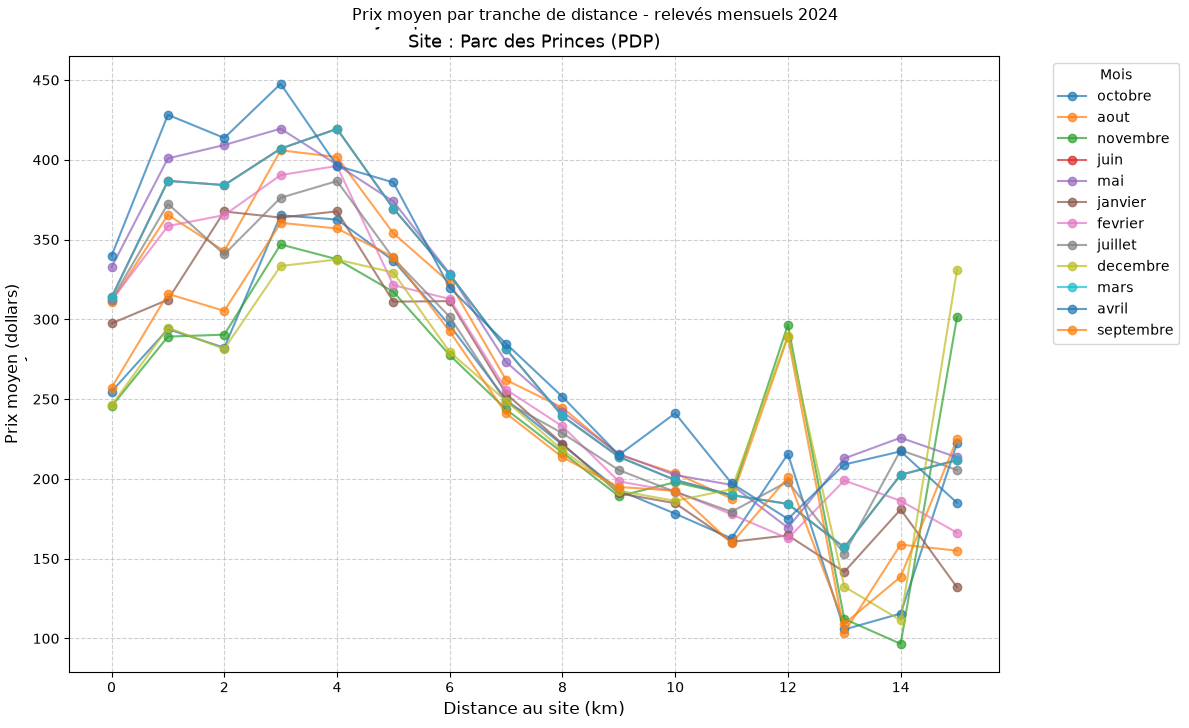
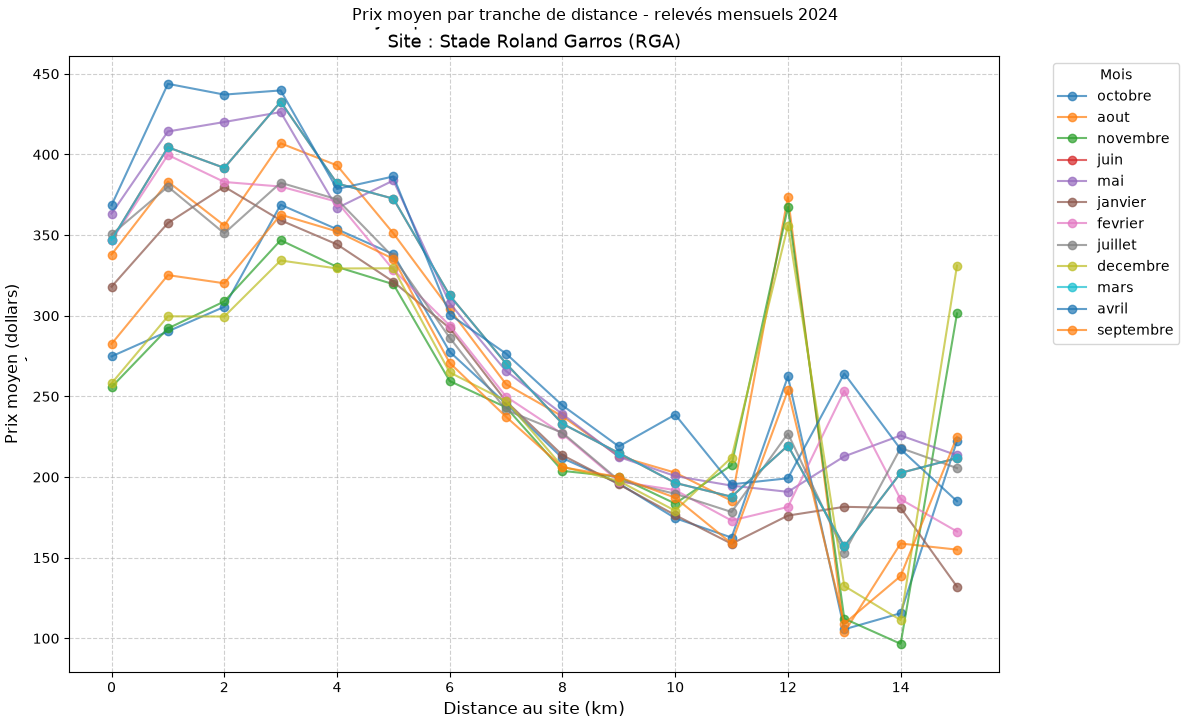

In [12]:
import base64
from html import escape
from IPython.display import HTML

codes_selectionnes = ['CDM', 'PDP', 'RGA']
commentaires = {'CDM': 'Champ-de-Mars : le prix moyen est souvent plus élevé entre 1 et moins de 2 km qu’à moins de 1 km, puis diminue. La proximité immédiate du site ne correspond donc pas systématiquement au maximum de prix.', 'PDP': 'Parc des Princes : les prix culminent à quelques kilomètres du stade avant de diminuer. Le même profil apparaît sur plusieurs mois ; il peut refléter les quartiers traversés, sans indiquer une distance recherchée par les visiteurs.', 'RGA': 'Roland-Garros : les prix augmentent d’abord à quelques kilomètres du stade, puis diminuent. Comme pour le Parc des Princes, les annonces les plus proches ne sont pas toujours les plus chères et le profil ne se limite pas à l’été.'}
figures = []
for fichier in sorted(Path("graphiques_sites_paris_tous_les_mois").glob("site_*.png")):
    code_site = fichier.name.split("_")[1]
    if code_site in codes_selectionnes:
        image = base64.b64encode(fichier.read_bytes()).decode("ascii")
        figures.append(f'<figure><img src="data:image/png;base64,{image}" style="width:100%;max-width:1000px" alt="{code_site}"/><figcaption>{escape(commentaires[code_site])}</figcaption></figure>')
display(HTML('<details><summary>Afficher les courbes de ce groupe — relevés 2024</summary>' + ''.join(figures) + '</details>'))

#### Porte de Versailles : les trois Arenas Paris Sud

Autour des trois Arenas Paris Sud, les prix moyens augmentent jusqu’à environ 3 km, puis diminuent. Le sommet se situe donc à quelques kilomètres du complexe, et non à son voisinage immédiat. Cette forme revient sur plusieurs mois, même si le niveau des prix varie selon le relevé : elle n’est pas propre à la période olympique.

Les trois sites étant voisins, leurs courbes concernent en grande partie les mêmes quartiers. Elles décrivent ainsi une structure géographique commune, sans permettre d’isoler l’influence de chaque Arena. À grande distance, certaines pointes de novembre ou de décembre dépassent celles de l’été. Il faudrait connaître les effectifs et la distribution des prix de ces tranches pour savoir si elles reflètent quelques annonces très chères ou un ensemble plus large.


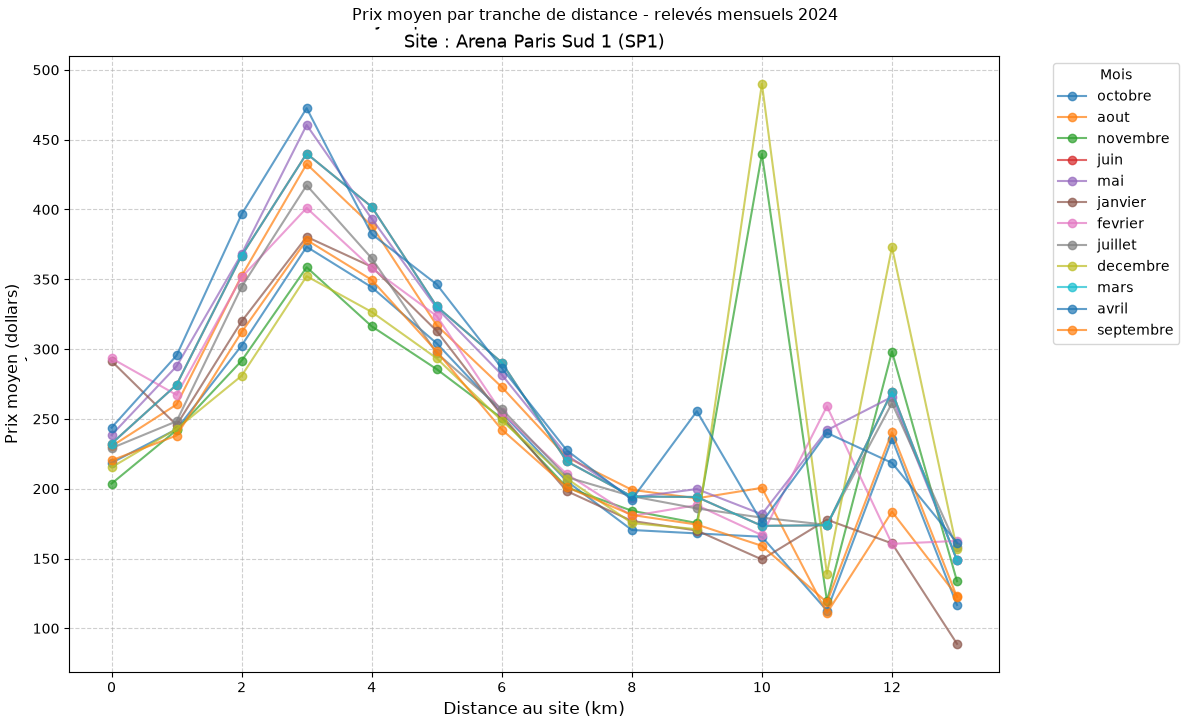
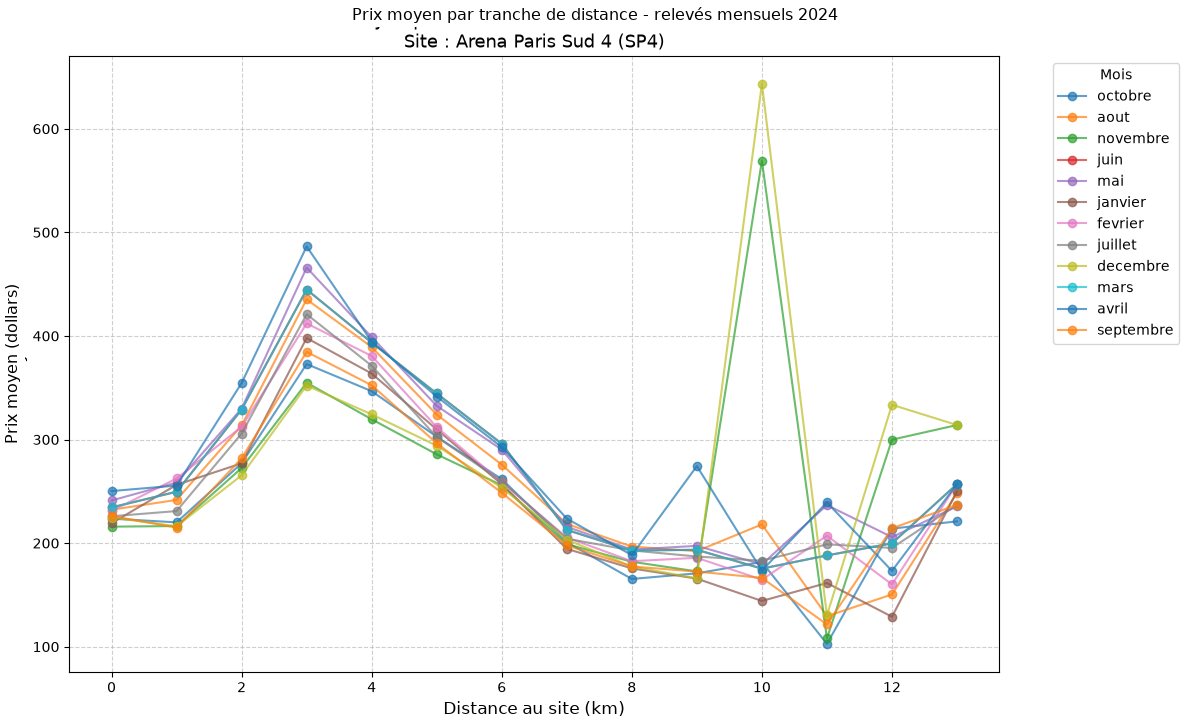
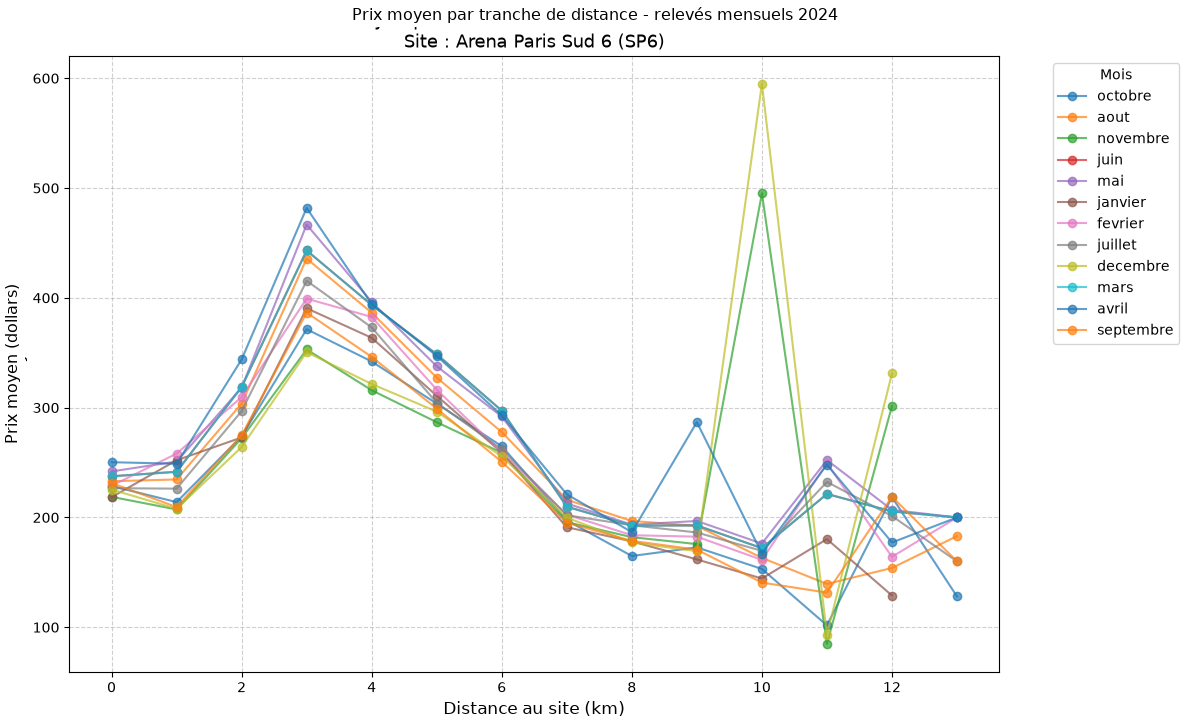

In [13]:
import base64
from html import escape
from IPython.display import HTML

codes_selectionnes = ['SP1', 'SP4', 'SP6']
commentaires = {'SP1': 'Arena Paris Sud 1 : les prix moyens atteignent un sommet vers 3 km, puis baissent. Cette forme apparaît à plusieurs saisons et ne peut donc pas être attribuée aux seuls Jeux.', 'SP4': 'Arena Paris Sud 4 : le maximum se situe vers 3 km, comme pour les deux autres Arenas. Les pointes plus éloignées de novembre et décembre demandent un contrôle des effectifs avant toute interprétation.', 'SP6': 'Arena Paris Sud 6 : les prix montent vers 3 km puis diminuent, comme autour de Paris Sud 1 et 4. Les trois sites sont voisins et leurs courbes décrivent en grande partie le même environnement.'}
figures = []
for fichier in sorted(Path("graphiques_sites_paris_tous_les_mois").glob("site_*.png")):
    code_site = fichier.name.split("_")[1]
    if code_site in codes_selectionnes:
        image = base64.b64encode(fichier.read_bytes()).decode("ascii")
        figures.append(f'<figure><img src="data:image/png;base64,{image}" style="width:100%;max-width:1000px" alt="{code_site}"/><figcaption>{escape(commentaires[code_site])}</figcaption></figure>')
display(HTML('<details><summary>Afficher les courbes de ce groupe — relevés 2024</summary>' + ''.join(figures) + '</details>'))

#### Nord, est et centre : Porte de la Chapelle, Bercy et Hôtel de Ville

À la Porte de la Chapelle, les prix moyens augmentent en s’éloignant du site, jusqu’à environ 6 km. À Bercy, ils restent assez stables sur les premiers kilomètres, puis montent à plus grande distance. À l’Hôtel de Ville, ils diminuent d’abord, puis remontent vers 5 km. Ces profils diffèrent de la baisse observée autour de plusieurs sites du centre-ouest : la proximité d’une compétition n’est donc pas systématiquement associée à des prix plus élevés.

Les forts pics éloignés de Bercy ne décrivent pas un surcoût au pied du site. Sans les effectifs par tranche, on ne peut pas savoir dans quelle mesure quelques prix élevés influencent la moyenne. Ces différences entre sites montrent pourquoi la régression doit tenir compte du quartier, de la distance au centre et des caractéristiques des logements avant d’interpréter un écart de prix comme un effet des Jeux.


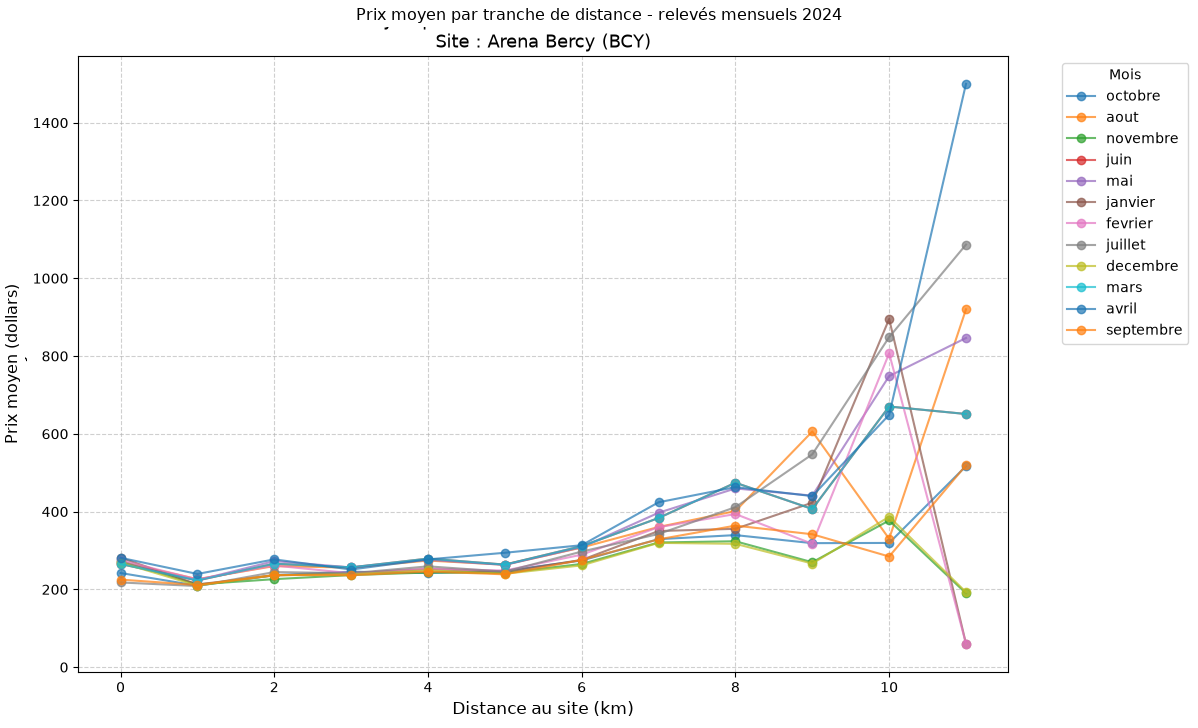
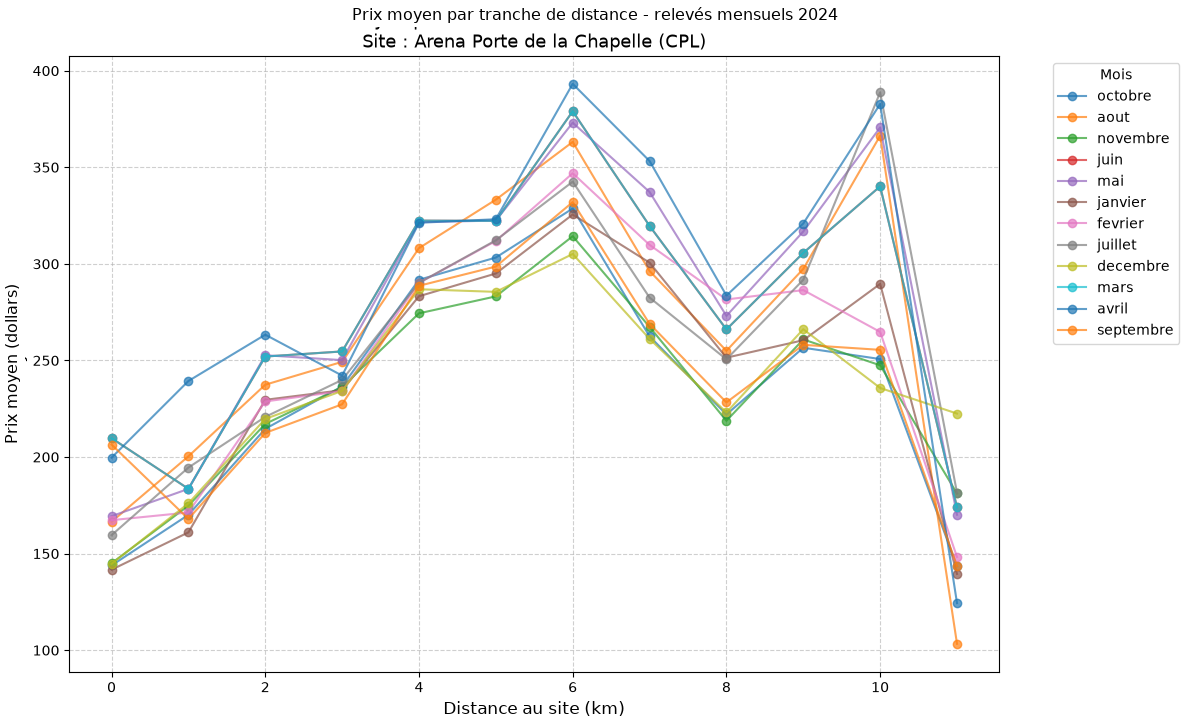
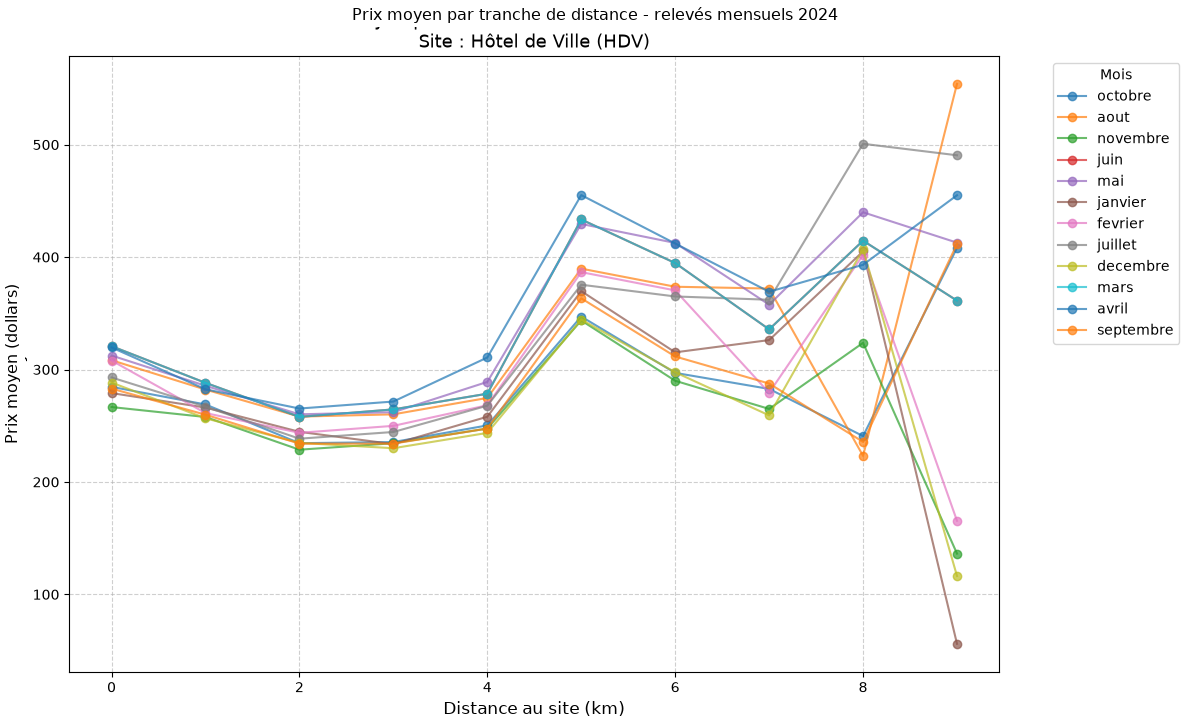

In [14]:
import base64
from html import escape
from IPython.display import HTML

codes_selectionnes = ['CPL', 'BCY', 'HDV']
commentaires = {'CPL': 'Porte de la Chapelle : les prix augmentent en s’éloignant du site jusqu’à environ 6 km. Contrairement aux sites du centre-ouest, le voisinage immédiat n’est pas le plus cher ; la distance reflète aussi un changement de quartier.', 'BCY': 'Bercy : les prix restent assez stables sur les premiers kilomètres, puis augmentent. Les forts pics à grande distance ne concernent pas les annonces voisines du site et restent difficiles à expliquer sans leurs effectifs.', 'HDV': 'Hôtel de Ville : les prix diminuent d’abord, puis remontent vers 5 km. Cette forme se retrouve sur plusieurs relevés et montre que la distance au site ne résume pas, à elle seule, la géographie des prix.'}
figures = []
for fichier in sorted(Path("graphiques_sites_paris_tous_les_mois").glob("site_*.png")):
    code_site = fichier.name.split("_")[1]
    if code_site in codes_selectionnes:
        image = base64.b64encode(fichier.read_bytes()).decode("ascii")
        figures.append(f'<figure><img src="data:image/png;base64,{image}" style="width:100%;max-width:1000px" alt="{code_site}"/><figcaption>{escape(commentaires[code_site])}</figcaption></figure>')
display(HTML('<details><summary>Afficher les courbes de ce groupe — relevés 2024</summary>' + ''.join(figures) + '</details>'))

### Comment les prix proches des sites évoluent-ils entre juillet et août ?

Le tableau ci-dessous compare les annonces situées à **moins de 1 km de chacun des 19 sites olympiques parisiens**, dans les relevés de juillet et d’août 2024. Pour chaque site, il indique le nombre d’annonces dont le prix est renseigné, leur prix médian et sa variation entre les deux relevés. Une variation positive signifie que la médiane est plus élevée en août ; une variation négative indique une baisse.

Les graphiques précédents utilisent des moyennes. Ici, nous retenons la médiane pour limiter l’influence de quelques tarifs très élevés. Les valeurs ne sont donc pas directement comparables à celles des courbes.

Deux précautions sont nécessaires : une même annonce peut être proche de plusieurs sites, donc les effectifs des lignes ne s’additionnent pas. De plus, les annonces dont le prix est connu peuvent changer entre juillet et août. Une hausse de la médiane ne signifie donc pas que chaque propriétaire a augmenté son tarif.

In [15]:
from prix_en_fonction_de_la_distance import calculer_distance
from sites_competition import charger_tables_locales, garder_sites_paris

sites_ete = garder_sites_paris(charger_tables_locales()[0]).drop_duplicates("code_site")
voisinages = []
for site in sites_ete.itertuples():
    ligne = {"site": site.code_site, "nom": site.nom_site}
    for mois in ["juillet", "aout"]:
        population = populations_ete[mois]
        distances = calculer_distance(population.latitude, population.longitude, site.latitude, site.longitude)
        prix = population.loc[(distances < 1) & population.prix_valide, "prix"]
        ligne[f"prix renseignés {mois}"] = len(prix)
        ligne[f"médiane {mois} (dollars)"] = prix.median()
    ligne["variation médiane (%)"] = 100 * (ligne["médiane aout (dollars)"] / ligne["médiane juillet (dollars)"] - 1)
    voisinages.append(ligne)
comparaison_sites = pd.DataFrame(voisinages).set_index("site")
display(comparaison_sites.drop(columns="nom").round(1))

,prix renseignés juillet,médiane juillet (dollars),prix renseignés aout,médiane aout (dollars),variation médiane (%)
site,,,,,
BCY,845,126.0,827,139.0,10.3
CDM,3281,200.0,3114,215.0,7.5
SP1,1247,144.0,1187,150.0,4.2
SP4,1108,141.5,1069,150.0,6.0
SP6,1019,139.0,982,149.0,7.2
CPL,528,110.0,508,126.0,14.5
GRP,1674,250.0,1692,270.0,8.0
HDV,5712,195.0,5722,206.0,5.6
INV,1705,213.0,1664,236.0,10.8


Le tableau fait apparaître deux dimensions différentes. En août, les médianes proches du Trocadéro et du Grand Palais atteignent respectivement **271 et 270 dollars**, contre **126 dollars** près de la Porte de la Chapelle et 139 dollars à Bercy. La hiérarchie des niveaux rejoint les cartes : les sites ne sont pas situés sur des marchés initialement équivalents.

La plus forte hausse relative entre juillet et août concerne pourtant la Porte de la Chapelle, de 110 à 126 dollars, soit **+14,5 %**. Les Invalides gagnent 10,8 %, Bercy 10,3 % et la Tour Eiffel 10,0 %. À l'autre extrémité, Roland-Garros reste à 200 dollars et le Parc des Princes passe de 195 à 192 dollars. Un quartier moins cher peut donc connaître une variation proportionnelle plus forte qu'un quartier touristique déjà cher. Se contenter des niveaux ou des couleurs les plus foncées masquerait cette différence.

Les cinq points de Concorde restent très proches : leurs hausses se situent entre 4,2 % et 4,8 %. Les trois Arenas Paris Sud augmentent de 4,2 % à 7,2 %. Ces similitudes sont cohérentes avec le recouvrement de leurs voisinages ; elles ne multiplient pas le nombre de comparaisons indépendantes.

Enfin, le nombre de prix renseignés diminue autour de plusieurs sites : de 2 900 à 2 795 pour la Tour Eiffel et de 528 à 508 pour la Porte de la Chapelle. Les écarts du tableau ne sont pas des augmentations tarifaires individuelles. Ils décrivent des groupes dont la composition peut changer, et ne fournissent aucun intervalle de confiance. La régression examine ensuite si une hausse supplémentaire demeure après contrôle de certaines différences entre logements et entre années.

### 5.4. Les annonces proches des parcours des cérémonies

La proximité d'un stade ne résume pas toute l'exposition aux Jeux. Le 26 juillet, le défilé olympique suit la Seine d'Austerlitz jusqu'au secteur Iéna–Trocadéro, sur environ six kilomètres ; le 28 août, le défilé paralympique descend le bas des Champs-Élysées vers la Concorde. Ces parcours sont documentés par le [CIO](https://www.olympics.com/ioc/news/paris-2024-olympic-games-opening-ceremony-flame-cauldron) et la [Ville de Paris](https://www.paris.fr/pages/accessibilite-des-quais-hauts-pendant-la-ceremonie-d-ouverture-27905).

Nous utilisons deux lignes simplifiées, conservées dans `parcours_ceremonies.geojson`. Leurs repères ont été saisis manuellement : ce ne sont ni des traces GPS officielles ni des périmètres de sécurité. La distance est calculée dans une projection locale en kilomètres. Une annonce est dite proche à moins de 750 mètres du tracé, et éloignée à partir de 2 km ; la zone intermédiaire est exclue. La position médiane d'un même identifiant fixe son groupe sur les quatre relevés.

Ce choix vise une proximité de quartier, pas une vue sur le défilé ni un accès garanti aux berges. Les deux voisinages se recouvrent en partie et ne constituent pas deux expériences indépendantes. Le tableau donne les effectifs et la couverture des prix pour rendre visible cette sélection.

annonces  prix_valides  part_prix_valides_pct  \
ceremonie    releve    groupe                                                   
olympique    aout      proche      11051          8958                   81.1   
                       éloigné     52855         38187                   72.2   
             juillet   proche      10997          9096                   82.7   
                       éloigné     53094         40167                   75.7   
             juin      proche      10608          8714                   82.1   
                       éloigné     51616         38978                   75.5   
             septembre proche      10719          8007                   74.7   
                       éloigné     51062         32294                   63.2   
paralympique aout      proche       1936          1666                   86.1   
                       éloigné     80453         59807                   74.3   
             juillet   proche       1903          1656                   87.0   
                       éloigné     80589         61926                   76.8   
             juin      proche       1822          1600                   87.8   
                       éloigné     78240         60037                   76.7   
             septembre proche       1861          1553                   83.4   
                       éloigné     77783         51010                   65.6   

                                prix_median_dollars  
ceremonie    releve    groupe                        
olympique    aout      proche                 225.0  
                       éloigné                150.0  
             juillet   proche                 207.0  
                       éloigné                140.0  
             juin      proche                 226.0  
                       éloigné                140.0  
             septembre proche                 211.0  
                       éloigné                131.0  
paralympique aout      proche                 275.5  
                       éloigné                160.0  
             juillet   proche                 255.5  
                       éloigné                150.0  
             juin      proche                 284.0  
                       éloigné                151.0  
             septembre proche                 267.0  
                       éloigné                149.0

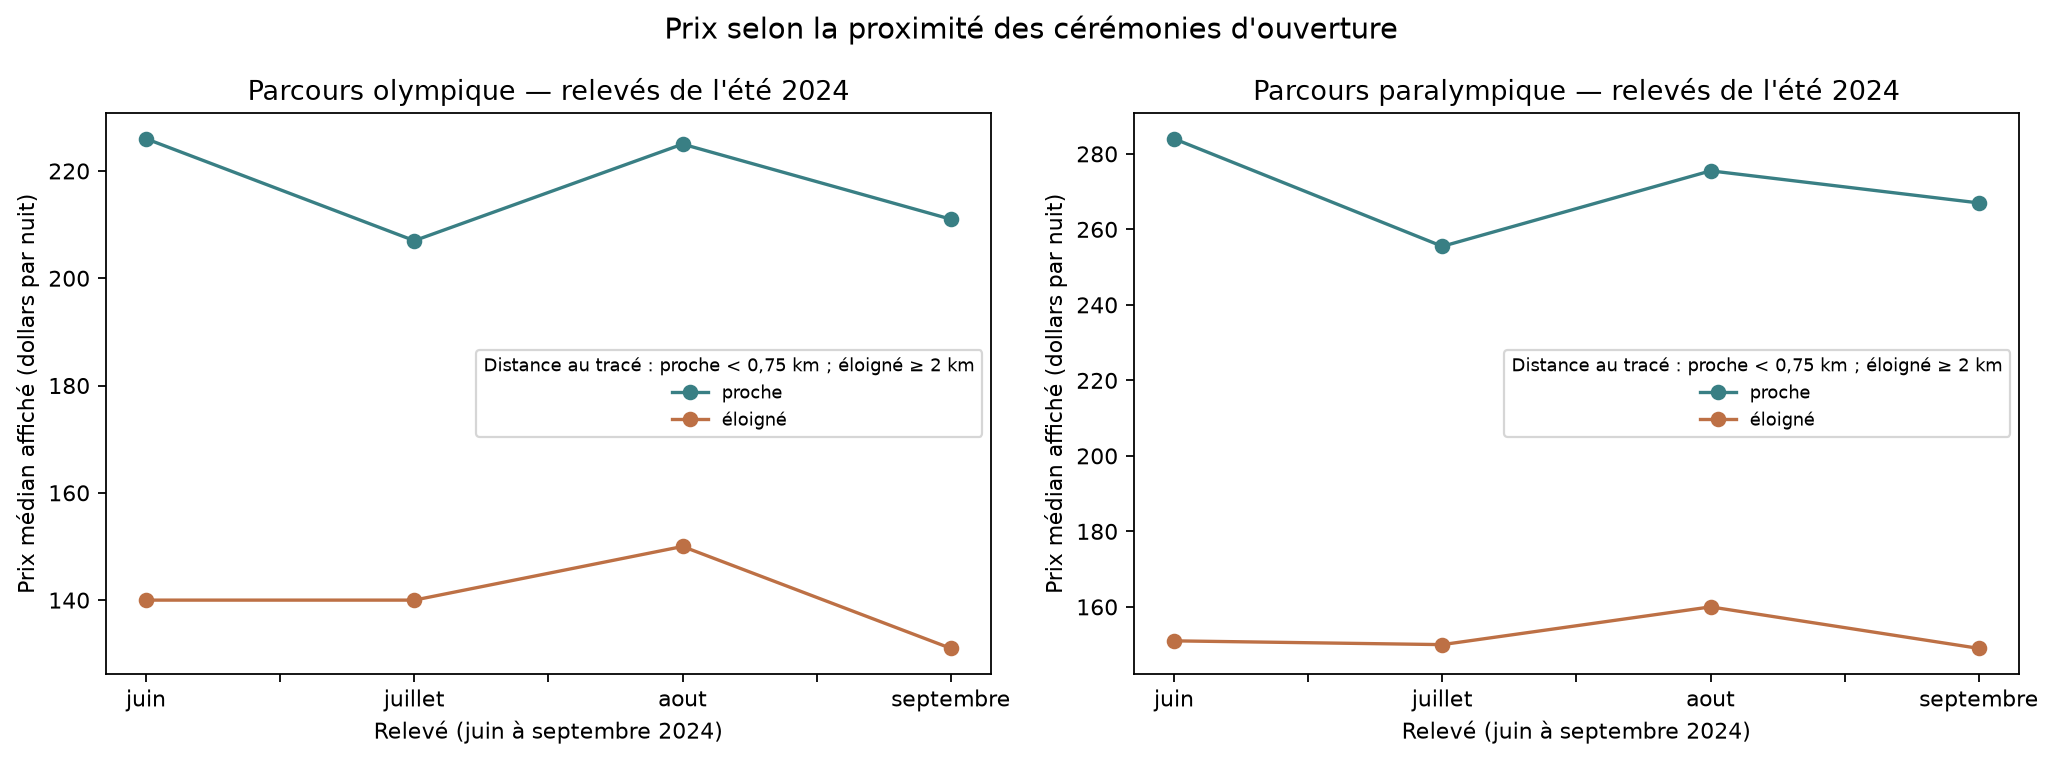

Juin à septembre 2024 : les deux graphiques ont des échelles verticales différentes.

In [16]:
import pandas as pd
ceremonies = pd.read_csv("resultats/prix_ceremonies.csv")
colonnes = ["ceremonie", "releve", "groupe", "annonces", "prix_valides", "part_prix_valides_pct", "prix_median_dollars"]
display(ceremonies[colonnes].round(1).set_index(["ceremonie", "releve", "groupe"]))
display(Image(filename="resultats/prix_ceremonies.png", width=1100))
display(Markdown("Juin à septembre 2024 : les deux graphiques ont des échelles verticales différentes."))

Près du parcours olympique, le prix médian est de **226 dollars en juin, 207 en juillet et 225 en août**, avant de passer à 211 en septembre. Le secteur est donc déjà cher avant la cérémonie. Entre juin et août, sa médiane baisse de 0,4 %, alors que celle du groupe éloigné passe de 140 à 150 dollars, soit +7,1 %. La proximité du tracé ne s'accompagne pas d'une hausse relative plus forte sur ces relevés.

Le voisinage du parcours paralympique est encore plus cher : 284 dollars en juin, 255,5 en juillet, 275,5 en août et 267 en septembre. Cette fois encore, le sommet ne se situe pas pendant le relevé suivant l'ouverture. La médiane de juin à août baisse d'environ 3,0 %, contre une hausse de 6,0 % dans le groupe éloigné. Mais le relevé d'août précède la cérémonie du 28 août : il ne peut pas mesurer directement ses effets du soir ou des jours qui suivent.

La couverture des prix diffère aussi entre groupes. En août, elle est de 81,1 % près du parcours olympique contre 72,2 % loin de celui-ci ; près du parcours paralympique, elle atteint 86,1 % contre 74,3 % loin du tracé. Ces écarts empêchent de traiter les médianes comme si les prix manquaient au hasard.

Nous avons refait le calcul à **500 mètres et à 1 km**. De juin à août, l'évolution près du parcours olympique varie de +1,3 % à −1,6 %, et reste inférieure à celle du groupe éloigné. Pour le parcours paralympique, elle reste négative aux trois seuils. Le constat descriptif résiste donc à ces choix de rayon, sans devenir une estimation causale : la centralité touristique, les restrictions d'accès et le calendrier des collectes restent mêlés à la proximité du défilé.

## 6. Régression linéaire : localisation et évolution des prix

### 6.1. La proximité des sites et les caractéristiques des logements

Les prix élevés autour de la Tour Eiffel ou du Grand Palais ne nous disent pas, à eux seuls, ce que les Jeux ont changé. Ces quartiers étaient déjà attractifs et les logements proposés peuvent être plus grands ou mieux équipés qu’ailleurs. La régression d’Othmane permet de tenir compte d’une partie de ces différences avant de comparer les prix près des sites et dans le reste de Paris.

Nous distinguons trois distances au site le plus proche : moins de 1 km, de 1 à moins de 3 km et 3 km ou plus. Le dernier groupe sert de référence. Le modèle porte sur le logarithme du prix et inclut notamment le type de logement, sa capacité, le nombre de chambres et de salles de bain, les avis et les caractéristiques de l’hôte. L’arrondissement et la distance au centre complètent ces variables. Les écarts estimés sont ensuite convertis en pourcentages.

Nous appliquons ce modèle aux relevés de juin et de juillet, en 2024 et en 2026. La comparaison avec 2026 sert à regarder si les annonces proches des sites sont aussi plus chères en dehors de l’année des Jeux. Elle ne fournit pas un témoin parfait, mais évite d’attribuer immédiatement aux compétitions une différence habituelle entre quartiers.

Les prix non positifs sont exclus, ainsi que les 1 % les plus bas et les plus hauts. La réservation instantanée n’étant pas renseignée en 2026, nous la retirons des deux années. Pour calculer l’incertitude des estimations, nous tenons compte des liens possibles entre annonces situées dans un même carré d’environ 500 mètres.

In [17]:
from pathlib import Path
import json
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf
from linearmodels.panel import PanelOLS
from shapely.geometry import shape
from shapely.ops import unary_union
from importation_données import lire_releve, chemin_cache, charger_contours
from carte_sites_paris import preparer_population, CONTOURS
from sites_competition import charger_tables_locales

paris = unary_union([shape(f["geometry"]) for f in charger_contours()])

def charger_annee(annee, mois):
    if not chemin_cache(annee, mois).exists():
        raise FileNotFoundError("Exécuter python importation_données.py avant de réestimer.")
    brut = lire_releve(annee, mois)
    brut["prix"] = pd.to_numeric(brut["price"].astype("string").str.replace(r"[$,]", "", regex=True), errors="coerce")
    for c in ["latitude", "longitude"]:
        brut[c] = pd.to_numeric(brut[c], errors="coerce")
    return preparer_population(brut, paris)[0]

def charger_releve(mois):
    return charger_annee(2024, mois)

def charger_releve_2026(mois):
    return charger_annee(2026, mois)

sites = pd.concat(charger_tables_locales()).dropna(subset=["latitude", "longitude"]).drop_duplicates("code_site").reset_index(drop=True)
print(f"{len(sites)} sites distincts ; périmètre parisien et nettoyage communs aux deux années.")


44 sites distincts ; périmètre parisien et nettoyage communs aux deux années.


In [18]:
def distance_km(lat1, lon1, lat2, lon2):
    """Distance de Haversine en km ; accepte des tableaux numpy."""
    lat1, lon1, lat2, lon2 = map(np.radians, (lat1, lon1, lat2, lon2))
    a = (np.sin((lat2 - lat1) / 2) ** 2
         + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2)
    return 2 * 6371.0 * np.arcsin(np.sqrt(np.clip(a, 0, 1)))


def distance_site_le_plus_proche(annonces, sites):
    """Pour chaque annonce : distance (km) et code du site de compétition le plus proche."""
    # Matrice annonces × sites, puis minimum sur les sites
    d = distance_km(
        annonces["latitude"].to_numpy()[:, None], annonces["longitude"].to_numpy()[:, None],
        sites["latitude"].to_numpy()[None, :], sites["longitude"].to_numpy()[None, :],
    )
    return d.min(axis=1), sites["code_site"].to_numpy()[d.argmin(axis=1)]


def cellule_500m(lat, lon):
    """Numéro du carré d'environ 500 m × 500 m qui contient chaque point."""
    # 0,0045° de latitude ≈ 500 m ; 0,0068° de longitude ≈ 500 m à la latitude de Paris
    # Identifiant stable entre jeux de données : pas de factorisation séparée par année.
    ligne = np.floor(np.asarray(lat) / 0.0045).astype(np.int64)
    colonne = np.floor(np.asarray(lon) / 0.0068).astype(np.int64)
    return (ligne + 20000) * 100000 + (colonne + 30000)



def en_pourcent(x):
    """Coefficient sur le log du prix -> écart en %."""
    return (np.exp(x) - 1) * 100

In [19]:
CENTRE_PARIS = (48.85341, 2.34880)  # point zéro, parvis de Notre-Dame
TRANCHE = "C(tranche, Treatment('plus de 3 km'))"
FORMULE = (f"log_prix ~ {TRANCHE} + dist_centre_km + C(room_type) + accommodates + bedrooms + bathrooms"
           " + note + sans_note + log_nb_avis + superhote + log_nuits_min"
           " + hote_multi_annonces + C(arrondissement)")


def preparer(df):
    df = df.assign(prix=pd.to_numeric(df["price"].astype("string").str.replace(r"[$,]", "", regex=True), errors="coerce"))
    df = df.loc[df["prix"].gt(0)].copy()
    df = df[df["prix"].between(*df["prix"].quantile([0.01, 0.99]))].copy()
    df["log_prix"] = np.log(df["prix"])
    df["dist_site_km"], _ = distance_site_le_plus_proche(df, sites)
    df["tranche"] = pd.cut(df["dist_site_km"], [0, 1, 3, np.inf], right=False,
                           labels=["moins de 1 km", "1 à 3 km", "plus de 3 km"])
    df["dist_centre_km"] = distance_km(df["latitude"], df["longitude"], *CENTRE_PARIS)
    df["cellule"] = cellule_500m(df["latitude"], df["longitude"])
    df["arrondissement"] = df["neighbourhood_cleansed"]
    df["sans_note"] = df["review_scores_rating"].isna().astype(int)
    df["note"] = df["review_scores_rating"].fillna(df["review_scores_rating"].mean())
    df["log_nb_avis"] = np.log1p(df["number_of_reviews"])
    df["log_nuits_min"] = np.log(df["minimum_nights"].clip(lower=1))
    df["superhote"] = (df["host_is_superhost"] == "t").astype(int)
    df["hote_multi_annonces"] = (df["calculated_host_listings_count"] > 1).astype(int)
    return df.dropna(subset=["bedrooms", "bathrooms", "accommodates", "room_type", "arrondissement",
                              "log_nb_avis", "log_nuits_min"])


def estimer(formule, df):
    modele = smf.ols(formule, data=df)
    if len(modele.endog) != len(df) or not np.isfinite(modele.exog).all():
        raise ValueError("Échantillon ou valeurs non finies à vérifier.")
    rang = np.linalg.matrix_rank(modele.exog)
    if rang != modele.exog.shape[1]:
        raise ValueError("Matrice de régression non identifiable.")
    print(f"OLS : {len(df)} observations ; rang {rang}/{modele.exog.shape[1]} ; {df.cellule.nunique()} groupes spatiaux.")
    return modele.fit(cov_type="cluster", cov_kwds={"groups": df["cellule"].to_numpy()})


lignes, modeles = [], {}
for mois in ["juin", "juillet"]:
    d24, d26 = preparer(charger_releve(mois)), preparer(charger_releve_2026(mois))
    m24, m26 = estimer(FORMULE, d24), estimer(FORMULE, d26)
    modeles[f"{mois} 2024"], modeles[f"{mois} 2026"] = m24, m26
    test = estimer(FORMULE.replace(TRANCHE, f"{TRANCHE} * annee_2024"),
                   pd.concat([d24.assign(annee_2024=1), d26.assign(annee_2024=0)], ignore_index=True))
    for tranche in ["moins de 1 km", "1 à 3 km"]:
        nom = f"{TRANCHE}[T.{tranche}]"
        lignes.append({"mois": mois, "tranche": tranche,
                       "prime 2024 (%)": en_pourcent(m24.params[nom]), "p 2024": m24.pvalues[nom],
                       "prime 2026 (%)": en_pourcent(m26.params[nom]), "p 2026": m26.pvalues[nom],
                       "écart relatif 2024 / 2026 (%)": en_pourcent(test.params[nom + ":annee_2024"]),
                       "p écart": test.pvalues[nom + ":annee_2024"]})
display(pd.DataFrame(lignes).set_index(["mois", "tranche"]).round(3))


# Coefficients de toutes les variables (effets fixes arrondissement et constante non affichés)
def etoiles(p):
    return "***" if p < 0.01 else "**" if p < 0.05 else "*" if p < 0.1 else ""


coefficients = pd.DataFrame({
    # Variable constante dans un relevé (ex. caractéristique constante dans un relevé) : pas de coefficient
    releve: [f"{b:.3f}{etoiles(p)}" if m.model.exog[:, j].std() > 0 or nom == "Intercept" else "non disponible"
             for j, (nom, b, p) in enumerate(zip(m.params.index, m.params, m.pvalues))]
    for releve, m in modeles.items()
}, index=next(iter(modeles.values())).params.index)
coefficients = coefficients[~coefficients.index.str.startswith(("C(arrondissement)", "Intercept"))]
coefficients.index = (coefficients.index.str.replace(f"{TRANCHE}[T.", "distance au site : ", regex=False)
                      .str.replace("C(room_type)[T.", "type : ", regex=False).str.rstrip("]"))
coefficients.loc["R²"] = [f"{m.rsquared:.3f}" for m in modeles.values()]
coefficients.loc["annonces"] = [f"{int(m.nobs)}" for m in modeles.values()]
coefficients


OLS : 72976 observations ; rang 35/35 ; 415 groupes spatiaux.


OLS : 35695 observations ; rang 35/35 ; 389 groupes spatiaux.


OLS : 108671 observations ; rang 38/38 ; 417 groupes spatiaux.


OLS : 75358 observations ; rang 35/35 ; 412 groupes spatiaux.


OLS : 36159 observations ; rang 35/35 ; 391 groupes spatiaux.


OLS : 111517 observations ; rang 38/38 ; 414 groupes spatiaux.


prime 2024 (%)  p 2024  prime 2026 (%)  p 2026  \
mois    tranche                                                         
juin    moins de 1 km           5.428   0.024           5.986   0.042   
        1 à 3 km                1.700   0.325           1.192   0.507   
juillet moins de 1 km           3.827   0.065           3.965   0.133   
        1 à 3 km                0.134   0.923          -0.141   0.929   

                       écart relatif 2024 / 2026 (%)  p écart  
mois    tranche                                                
juin    moins de 1 km                          0.104    0.947  
        1 à 3 km                               0.162    0.905  
juillet moins de 1 km                         -2.084    0.141  
        1 à 3 km                              -1.225    0.326

,juin 2024,juin 2026,juillet 2024,juillet 2026
distance au site : moins de 1 km,0.053**,0.058**,0.038*,0.039
distance au site : 1 à 3 km,0.017,0.012,0.001,-0.001
type : Hotel room,0.486***,0.222***,0.246***,0.154**
type : Private room,-0.167***,-0.186***,-0.191***,-0.207***
type : Shared room,-0.449***,-0.794***,-0.398***,-0.754***
dist_centre_km,-0.094***,-0.098***,-0.080***,-0.084***
accommodates,0.136***,0.139***,0.111***,0.129***
bedrooms,0.158***,0.114***,0.198***,0.128***
bathrooms,0.091***,0.108***,0.111***,0.107***
note,0.149***,0.172***,0.167***,0.183***


En juin 2024, le modèle estime un prix supérieur de **5,43 % à moins de 1 km d’un site**, par rapport aux annonces situées à 3 km ou plus, après prise en compte des caractéristiques observées. L’écart atteint 5,99 % en juin 2026. En juillet, les estimations sont également proches : 3,83 % en 2024 et 3,97 % en 2026. Celle de juillet 2024 est toutefois moins précise et n’est pas significative au seuil de 5 %.

Le résultat à retenir est donc la ressemblance entre les deux années. Lorsque nous les réunissons dans un même modèle, le supplément relatif associé à 2024 est de +0,10 % en juin et de −2,08 % en juillet. Les p-valeurs, respectivement 0,947 et 0,141, ne permettent pas de distinguer ces écarts de zéro au seuil de 5 %. Sur ces relevés, nous retrouvons une différence de prix près des sites, mais pas de supplément significatif propre à l’année olympique. Les interactions de ce modèle regroupé ne sont pas la simple soustraction des primes estimées séparément.

Les autres coefficients correspondent aussi à des différences attendues entre logements : la capacité et le nombre de chambres sont positivement associés au prix, tandis que la distance au centre lui est négativement associée. Les R² vont de 0,438 à 0,594. Le modèle explique ainsi une partie des écarts, tout en laissant de côté des éléments comme la vue, l’état précis du logement ou l’attrait d’une rue.

### 6.2. L’évolution des annonces au cours de l’été

Les annonces dont le prix est connu ne sont pas exactement les mêmes à chaque collecte. Une variation de médiane peut donc venir d’un changement dans les logements observés. Le panel permet de suivre les identifiants au fil des relevés de juin à septembre, séparément pendant chaque été.

Nous retenons les annonces à moins de 1 km d’un site et les comparons à celles situées à plus de 2 km. La zone intermédiaire est exclue. Le seuil du groupe éloigné est ramené de 3 à 2 km pour conserver suffisamment d’observations. La position de chaque annonce est fixée à la médiane de ses coordonnées : un léger déplacement de la localisation affichée ne modifie ainsi pas son groupe à chaque relevé.

Le tableau compte les identifiants avant l’exclusion finale des prix manquants ou extrêmes. Certaines annonces ne sont observées qu’à une partie des dates, et leur présence dans les deux années n’est pas exigée. Le modèle compare leurs prix au cours d’un même été.

In [20]:
MOIS_ETE = {"juin": 6, "juillet": 7, "aout": 8, "septembre": 9}

morceaux = []
for annee, charger in [(2024, charger_releve), (2026, charger_releve_2026)]:
    for mois, num in MOIS_ETE.items():
        r = charger(mois)
        r["annee"], r["mois"] = annee, num
        morceaux.append(r)
ete = pd.concat(morceaux, ignore_index=True).drop_duplicates(subset=["id", "annee", "mois"])

# Position fixe par annonce, puis groupes proche / témoin
pos_ete = ete.groupby("id")[["latitude", "longitude"]].median()
pos_ete["dist_site_km"], _ = distance_site_le_plus_proche(pos_ete, sites)
pos_ete["cellule"] = cellule_500m(pos_ete["latitude"], pos_ete["longitude"])
pos_ete["groupe"] = np.select([pos_ete["dist_site_km"] < 1, pos_ete["dist_site_km"] > 2],
                              ["proche", "témoin"], default="intermédiaire")
ete = ete.merge(pos_ete[["groupe", "cellule"]], left_on="id", right_index=True)
ete = ete[ete["groupe"] != "intermédiaire"].copy()
ete["proche"] = (ete["groupe"] == "proche").astype(int)

# Variables : prix extrêmes retirés avec des bornes propres à chaque année
ete["prix"] = pd.to_numeric(ete["price"].astype("string").str.replace(r"[$,]", "", regex=True), errors="coerce")
ete.loc[~ete["prix"].gt(0), "prix"] = np.nan
bornes = ete.groupby("annee")["prix"].quantile([0.01, 0.99]).unstack()
dans_bornes = ete["prix"].between(ete["annee"].map(bornes[0.01]), ete["annee"].map(bornes[0.99]))
ete["log_prix"] = np.log(ete["prix"].where(dans_bornes))

ete.groupby(["annee", "groupe"])["id"].nunique().unstack().rename_axis(None, axis=1)

C:\Users\assia\OneDrive\Documents\GitHub\Projet-Python-2A-1\.venv\Lib\site-packages\pandas\core\arrays\masked.py:902: RuntimeWarning: divide by zero encountered in log
  result = getattr(ufunc, method)(*inputs2, **kwargs)


,proche,témoin
annee,,
2024,22915,35544
2026,18640,26674


Nous prenons juin comme point de départ et regardons si les prix évoluent davantage près des sites que dans les quartiers éloignés. Nous faisons ce calcul pour 2024, puis pour 2026. L’écart entre les deux années, appelé triple différence, mesure le supplément d’évolution propre à 2024. L’année de comparaison sert ici à tenir compte du fait que les quartiers touristiques peuvent avoir leur propre saisonnalité.

Le modèle intègre un effet fixe pour chaque annonce et chaque année, qui tient compte de ses caractéristiques constantes pendant l’été. Des effets de période prennent en charge les mouvements communs aux groupes lors d’un même relevé. Reste une hypothèse que les données ne permettent pas de vérifier suffisamment : sans les Jeux, l’écart d’évolution entre quartiers proches et éloignés aurait été comparable en 2024 et en 2026. Avec juin comme seul mois de référence avant l’été, nous manquons de recul pour juger de cette stabilité.

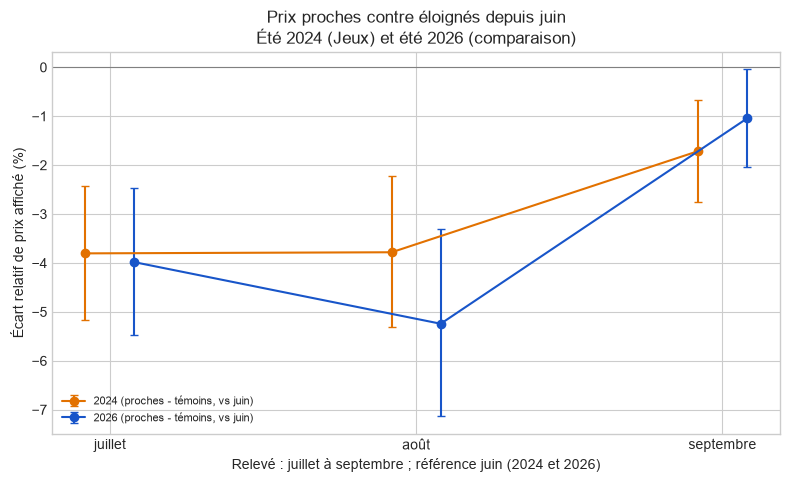

Observations utilisées : 252900 ; annonces-années : 78025 ; cellules spatiales : 346


,supplément relatif 2024 (%),bas IC 95 %,haut IC 95 %,p-valeur
juillet,0.188,-1.054,1.445,0.768
août,1.542,-0.338,3.458,0.109
septembre,-0.676,-2.195,0.867,0.389


In [21]:
def ecarts(d, noms, entite, temps):
    """Régression de panel du log du prix ; erreurs standard regroupées par carré de 500 m."""
    d = d.set_index([entite, temps])
    return PanelOLS(d["log_prix"], d[noms], entity_effects=True, time_effects=True).fit(
        cov_type="clustered", clusters=d[["cellule"]])


donnees_td = ete.dropna(subset=["log_prix"]).copy()
donnees_td["annonce_annee"] = pd.factorize(donnees_td["id"].astype(str) + "_" + donnees_td["annee"].astype(str))[0]
donnees_td["periode"] = donnees_td["annee"] * 100 + donnees_td["mois"]
for m in [7, 8, 9]:
    donnees_td[f"proche × {m}"] = donnees_td["proche"] * (donnees_td["mois"] == m)
    donnees_td[f"proche × {m} × 2024"] = donnees_td[f"proche × {m}"] * (donnees_td["annee"] == 2024)

# Triple différence : effet des Jeux
noms_jeux = [f"proche × {m} × 2024" for m in [7, 8, 9]]
triple = ecarts(donnees_td, [f"proche × {m}" for m in [7, 8, 9]] + noms_jeux, "annonce_annee", "periode")

# Écart proches - témoins par rapport à juin, année par année (pour le graphique)
fig, ax = plt.subplots(figsize=(8, 4.5))
for annee, couleur in [(2024, "#e27100"), (2026, "#1855c9")]:
    r = ecarts(donnees_td[donnees_td["annee"] == annee], [f"proche × {m}" for m in [7, 8, 9]], "id", "mois")
    effet, ic = en_pourcent(r.params.to_numpy()), en_pourcent(r.conf_int().to_numpy())
    ax.errorbar(np.array([7, 8, 9]) + (0.08 if annee == 2026 else -0.08), effet,
                yerr=[effet - ic[:, 0], ic[:, 1] - effet],
                fmt="o-", capsize=3, color=couleur, label=f"{annee} (proches - témoins, vs juin)")
ax.axhline(0, color="grey", linewidth=0.8)
ax.set_xticks([7, 8, 9], ["juillet", "août", "septembre"])
ax.set_ylabel("Écart relatif de prix affiché (%)")
ax.set_xlabel("Relevé : juillet à septembre ; référence juin (2024 et 2026)")
fig.tight_layout()
ax.set_title("Prix proches contre éloignés depuis juin\nÉté 2024 (Jeux) et été 2026 (comparaison)")
ax.legend(fontsize=8)
plt.show()

resultats_triple = pd.DataFrame({
    "supplément relatif 2024 (%)": en_pourcent(triple.params[noms_jeux]).to_numpy(),
    "bas IC 95 %": en_pourcent(triple.conf_int().loc[noms_jeux, "lower"]).to_numpy(),
    "haut IC 95 %": en_pourcent(triple.conf_int().loc[noms_jeux, "upper"]).to_numpy(),
    "p-valeur": triple.pvalues[noms_jeux].to_numpy(),
}, index=["juillet", "août", "septembre"]).round(3)
print("Observations utilisées :", len(donnees_td), "; annonces-années :", donnees_td.annonce_annee.nunique(), "; cellules spatiales :", donnees_td.cellule.nunique())

display(resultats_triple)


Le graphique présente, pour chaque année, le changement de prix des annonces proches par rapport aux annonces éloignées depuis juin. Une courbe sous zéro peut correspondre à une hausse des prix moins forte près des sites, et pas nécessairement à une baisse de leurs tarifs. Le tableau donne ensuite la différence entre les évolutions de 2024 et de 2026.

Le supplément estimé pour 2024 est de **+0,19 % en juillet, +1,54 % en août et −0,68 % en septembre**. Aucun ne se distingue de zéro au seuil de 5 %. Pour août, l’intervalle à 95 % s’étend de −0,34 % à +3,46 %, avec une p-valeur de 0,109. Le résultat reste donc compatible avec une petite hausse près des sites, sans permettre de l’établir avec suffisamment de précision.

Nous observions pourtant un prix médian parisien de 170 dollars en août, le plus élevé de l’année. Les deux résultats peuvent coexister : une hausse générale à Paris n’implique pas que les quartiers proches des compétitions aient augmenté davantage que les autres. C’est ce supplément local que le modèle ne met pas en évidence. Une anticipation avant juin ou un effet commun à toute la capitale restent hors de cette comparaison.

### 6.3. La couverture des prix dans les deux années

La comparaison repose sur moins de prix renseignés en 2026 qu’en 2024. Le tableau rassemble les effectifs, la part de prix exploitables et les dates réelles de collecte des huit relevés. Il précise ainsi quelles annonces entrent dans la comparaison et à quel moment elles ont été observées.

In [22]:
from importation_données import lire_releve

controle_ete = []
for annee in [2024, 2026]:
    for mois in ["juin", "juillet", "aout", "septembre"]:
        table = lire_releve(annee, mois)
        prix = pd.to_numeric(table["price"].astype("string").str.replace(r"[$,]", "", regex=True), errors="coerce")
        valides = prix.gt(0).fillna(False)
        dates = pd.to_datetime(table["last_scraped"], errors="coerce")
        controle_ete.append({"année": annee, "relevé": mois, "annonces": len(table),
            "prix exploitables": int(valides.sum()), "prix exploitables (%)": 100 * valides.sum() / len(table),
            "collecte début": dates.min().date(), "collecte fin": dates.max().date()})
qualite_ete = pd.DataFrame(controle_ete)
display(qualite_ete.set_index(["année", "relevé"]).round(1))

annonces  prix exploitables  prix exploitables (%)  \
année relevé                                                          
2024  juin          95885              74579                   77.8   
      juillet       98810              77010                   77.9   
      aout          98736              74401                   75.4   
      septembre     95461              64230                   67.3   
2026  juin          77679              48402                   62.3   
      juillet       78071              48741                   62.4   
      aout          78504              47445                   60.4   
      septembre     77149              43537                   56.4   

                collecte début collecte fin  
année relevé                                 
2024  juin          2024-06-11   2024-06-14  
      juillet       2024-07-14   2024-07-28  
      aout          2024-08-09   2024-08-15  
      septembre     2024-09-06   2024-09-13  
2026  juin          2026-06-17   2026-06-29  
      juillet       2026-07-15   2026-07-22  
      aout          2026-08-15   2026-08-29  
      septembre     2026-09-17   2026-09-24

En juin, nous disposons d’un prix exploitable pour 77,8 % des annonces en 2024, contre 62,3 % en 2026. En septembre, ces proportions sont de 67,3 % et 56,4 %. Si les annonces sans prix diffèrent des autres, par leur emplacement ou leur type de logement, les estimations peuvent refléter en partie cette sélection.

Les dates ne coïncident pas non plus : le relevé de septembre couvre le 6 au 13 en 2024, contre le 17 au 24 en 2026. Nous comparons donc les mêmes mois, sans observer exactement les mêmes moments de la saison. Les effets fixes et les caractéristiques incluses dans le modèle ne suffisent pas à corriger automatiquement ces écarts. Ils expliquent pourquoi nous interprétons les résultats comme une comparaison conditionnelle, et non comme une mesure définitive de l’effet des Jeux.

## 7. Biais et portée des résultats

### Ce que nous observons réellement

Une annonce observée n'est pas nécessairement louée. Une nuit indisponible n'est pas nécessairement réservée : l'hôte peut la bloquer ou imposer des conditions qui empêchent une réservation. Enfin, un prix affiché n'est pas nécessairement le prix payé. Ni les effectifs, ni `availability_30`, ni les tarifs ne donnent directement le nombre de séjours vendus ou les revenus des hôtes.

Les relevés ne décrivent pas le marché en continu. Entre deux collectes, une annonce peut apparaître, disparaître ou modifier plusieurs fois son tarif sans que nous le voyions. Les collectes de juillet et septembre chevauchent respectivement l'ouverture olympique et la fin des Paralympiques ; aucun relevé n'observe précisément la soirée du 28 août. Les données ne permettent donc pas de distinguer proprement les deux événements ou une variation très courte liée à une cérémonie.

### Saison et année de comparaison

Comparer les mêmes mois en 2024 et en 2026 est plus informatif que comparer seulement juin et août 2024. Le modèle autorise une saisonnalité différente entre quartiers proches et éloignés. Il ne neutralise pas tous les changements intervenus en deux ans : réglementation, demande touristique, composition de l'offre ou chocs locaux peuvent modifier cette saisonnalité. Les contrôles réduisent le problème ; ils ne le font pas disparaître.

Juin peut aussi être déjà affecté par l'anticipation des Jeux. Dans ce cas, prendre juin comme référence masque une partie d'un éventuel ajustement antérieur. La direction exacte du biais dépend des réactions des deux groupes. Il faudrait davantage de relevés avant les Jeux et d'années comparables pour tester les tendances préalables.

### Prix renseignés et sélection des annonces

En septembre 2024, seules 67,3 % des annonces ont un prix exploitable, contre 77,9 % en juillet. Nous décrivons les prix connus, pas ceux de l'ensemble des annonces. La présence d'un prix peut dépendre du calendrier, des conditions du séjour et de la disponibilité ; une valeur manquante ne suffit pas à identifier un logement complet.

Le suivi des mêmes identifiants et les effets fixes réduisent les changements de composition. Ils ne corrigent pas une disparition sélective des prix, ni une modification de la qualité du logement au cours de l'été. Les différences d'effectifs entre 2024 et 2026 appellent donc une vérification de la couverture, au-delà des seuls coefficients.

### Distance, voisinages et groupe témoin

Les coordonnées Airbnb sont approximatives. Une annonce près d'une borne peut changer de classe sans que sa distance réelle au site ait changé. La distance à vol d'oiseau ignore aussi les transports et l'accessibilité. Les sites centraux ont des voisinages qui se recouvrent ; le regroupement spatial des erreurs standard évite de traiter toutes les annonces comme indépendantes, sans éliminer les facteurs omis.

Les annonces éloignées ne sont pas nécessairement à l'écart des Jeux. Les visiteurs peuvent loger ailleurs dans Paris. La triple différence porte donc sur un effet relatif de proximité, et non sur l'effet total des Jeux sur le marché parisien.


## 8. Réponse à la problématique

L'été 2024 associe une offre d'annonces élevée à un sommet du prix médian en août, mais les deux ne culminent pas au même relevé. L'offre est déjà maximale en juillet, alors que les prix médians y baissent. La hausse d'août est ensuite assez diffuse : elle concerne 72,3 % des mailles communes avec juillet et apparaît pour les logements entiers comme pour les chambres privées.

La proximité des compétitions ne suffit pas à expliquer les niveaux ni les variations. Le centre-ouest est cher à plusieurs périodes de l'année, tandis que certains sites périphériques ont un voisinage moins cher mais une hausse relative plus forte en août. Les parcours des cérémonies traversent eux aussi des secteurs déjà chers avant l'événement. Ces observations rendent insuffisante une comparaison qui opposerait simplement « près » et « loin » pendant les Jeux.

La régression retrouve une prime près des sites, mais ne détecte pas de supplément significatif propre à 2024 sur les comparaisons étudiées. Dans le panel, l'estimation supplémentaire d'août vaut +1,54 %, avec un intervalle à 95 % allant de −0,34 % à +3,46 %. **Les données ne permettent donc pas d'établir une hausse particulière des prix affichés près des sites attribuable aux Jeux.**

Cette réponse porte sur un effet relatif de proximité, pas sur l'effet total sur Paris. Elle reste compatible avec une petite hausse locale, une anticipation antérieure à juin ou une évolution qui aurait touché toute la capitale. Les différences de couverture des prix et le manque de recul avant les Jeux empêchent une conclusion causale plus ferme. Les revenus et les réservations effectives demeurent, eux, hors de notre mesure.